# Data Science for COVID-19

## Introduction

**Context**

This is a structured dataset based on the report materials of KCDC and local governments. The data is obtained from Kaggle website: https://www.kaggle.com/datasets/kimjihoo/coronavirusdataset?select=Region.csv.
COVID-19 has infected more than 10,000 people in South Korea. KCDC (Korea Centers for Disease Control & Prevention) announces the information of COVID-19 quickly and transparently. 

**Project**

The COVID-19 dataset is used for Capstone project of Data Wrangling. Data analysis is done using python and primarily pandas library. For visualization matplotlib, geopandas, windrose and seaborn libraries were used. 

# Before starting to explore data

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
import ipywidgets as widgets
import os
from scipy.stats import chi2_contingency
from windrose import WindroseAxes, plot_windrose
from collections import defaultdict

In [2]:
dir_path = 'archive/'

files = []

for file_path in os.listdir(dir_path):
    # check if current file_path is a file
    if os.path.isfile(os.path.join(dir_path, file_path)):
        files.append(file_path)

print(files)
print(f'There are {len(files)} files in total')

['Case.csv', 'PatientInfo.csv', 'Policy.csv', 'Region.csv', 'SearchTrend.csv', 'SeoulFloating.csv', 'Time.csv', 'TimeAge.csv', 'TimeGender.csv', 'TimeProvince.csv', 'Weather.csv']
There are 11 files in total


Start with opening all of data files

In [3]:
case = pd.read_csv(dir_path + 'Case.csv', na_values='-')
case.columns = case.columns.str.strip()
case.head()

,case_id,province,city,group,infection_case,confirmed,latitude,longitude
0,1000001,Seoul,Yongsan-gu,True,Itaewon Clubs,139,37.538621,126.992652
1,1000002,Seoul,Gwanak-gu,True,Richway,119,37.482080,126.901384
2,1000003,Seoul,Guro-gu,True,Guro-gu Call Center,95,37.508163,126.884387
3,1000004,Seoul,Yangcheon-gu,True,Yangcheon Table Tennis Club,43,37.546061,126.874209
4,1000005,Seoul,Dobong-gu,True,Day Care Center,43,37.679422,127.044374


In [4]:
patient = pd.read_csv(dir_path + 'PatientInfo.csv')
patient.head()

,patient_id,sex,age,country,province,city,infection_case,infected_by,contact_number,symptom_onset_date,confirmed_date,released_date,deceased_date,state
0,1000000001,male,50s,Korea,Seoul,Gangseo-gu,overseas inflow,NaN,75,2020-01-22,2020-01-23,2020-02-05,NaN,released
1,1000000002,male,30s,Korea,Seoul,Jungnang-gu,overseas inflow,NaN,31,NaN,2020-01-30,2020-03-02,NaN,released
2,1000000003,male,50s,Korea,Seoul,Jongno-gu,contact with patient,2002000001,17,NaN,2020-01-30,2020-02-19,NaN,released
3,1000000004,male,20s,Korea,Seoul,Mapo-gu,overseas inflow,NaN,9,2020-01-26,2020-01-30,2020-02-15,NaN,released
4,1000000005,female,20s,Korea,Seoul,Seongbuk-gu,contact with patient,1000000002,2,NaN,2020-01-31,2020-02-24,NaN,released


In [5]:
policy = pd.read_csv(dir_path + 'Policy.csv', index_col=0)
policy.head()

,country,type,gov_policy,detail,start_date,end_date
policy_id,,,,,,
1,Korea,Alert,Infectious Disease Alert Level,Level 1 (Blue),2020-01-03,2020-01-19
2,Korea,Alert,Infectious Disease Alert Level,Level 2 (Yellow),2020-01-20,2020-01-27
3,Korea,Alert,Infectious Disease Alert Level,Level 3 (Orange),2020-01-28,2020-02-22
4,Korea,Alert,Infectious Disease Alert Level,Level 4 (Red),2020-02-23,NaN
5,Korea,Immigration,Special Immigration Procedure,from China,2020-02-04,NaN


In [6]:
region = pd.read_csv(dir_path + 'Region.csv')
region.head()

,code,province,city,latitude,longitude,elementary_school_count,kindergarten_count,university_count,academy_ratio,elderly_population_ratio,elderly_alone_ratio,nursing_home_count
0,10000,Seoul,Seoul,37.566953,126.977977,607,830,48,1.44,15.38,5.8,22739
1,10010,Seoul,Gangnam-gu,37.518421,127.047222,33,38,0,4.18,13.17,4.3,3088
2,10020,Seoul,Gangdong-gu,37.530492,127.123837,27,32,0,1.54,14.55,5.4,1023
3,10030,Seoul,Gangbuk-gu,37.639938,127.025508,14,21,0,0.67,19.49,8.5,628
4,10040,Seoul,Gangseo-gu,37.551166,126.849506,36,56,1,1.17,14.39,5.7,1080


In [7]:
search_trend = pd.read_csv(dir_path + 'SearchTrend.csv')
search_trend.head()

,date,cold,flu,pneumonia,coronavirus
0,2016-01-01,0.11663,0.05590,0.15726,0.00736
1,2016-01-02,0.13372,0.17135,0.20826,0.00890
2,2016-01-03,0.14917,0.22317,0.19326,0.00845
3,2016-01-04,0.17463,0.18626,0.29008,0.01145
4,2016-01-05,0.17226,0.15072,0.24562,0.01381


In [8]:
seoul_floating = pd.read_csv(dir_path + 'SeoulFloating.csv')
seoul_floating.head()

,date,hour,birth_year,sex,province,city,fp_num
0,2020-01-01,0,20,female,Seoul,Dobong-gu,19140
1,2020-01-01,0,20,male,Seoul,Dobong-gu,19950
2,2020-01-01,0,20,female,Seoul,Dongdaemun-gu,25450
3,2020-01-01,0,20,male,Seoul,Dongdaemun-gu,27050
4,2020-01-01,0,20,female,Seoul,Dongjag-gu,28880


In [9]:
time = pd.read_csv(dir_path + 'Time.csv')
time.head()

,date,time,test,negative,confirmed,released,deceased
0,2020-01-20,16,1,0,1,0,0
1,2020-01-21,16,1,0,1,0,0
2,2020-01-22,16,4,3,1,0,0
3,2020-01-23,16,22,21,1,0,0
4,2020-01-24,16,27,25,2,0,0


In [10]:
time_age = pd.read_csv(dir_path + 'TimeAge.csv')
time_age.head()

,date,time,age,confirmed,deceased
0,2020-03-02,0,0s,32,0
1,2020-03-02,0,10s,169,0
2,2020-03-02,0,20s,1235,0
3,2020-03-02,0,30s,506,1
4,2020-03-02,0,40s,633,1


In [11]:
time_gender = pd.read_csv(dir_path + 'TimeGender.csv')
time_gender.head()

,date,time,sex,confirmed,deceased
0,2020-03-02,0,male,1591,13
1,2020-03-02,0,female,2621,9
2,2020-03-03,0,male,1810,16
3,2020-03-03,0,female,3002,12
4,2020-03-04,0,male,1996,20


In [12]:
time_province = pd.read_csv(dir_path + 'TimeProvince.csv')
time_province.head()

,date,time,province,confirmed,released,deceased
0,2020-01-20,16,Seoul,0,0,0
1,2020-01-20,16,Busan,0,0,0
2,2020-01-20,16,Daegu,0,0,0
3,2020-01-20,16,Incheon,1,0,0
4,2020-01-20,16,Gwangju,0,0,0


In [13]:
weather = pd.read_csv(dir_path + 'Weather.csv')
weather.head()

,code,province,date,avg_temp,min_temp,max_temp,precipitation,max_wind_speed,most_wind_direction,avg_relative_humidity
0,10000,Seoul,2016-01-01,1.2,-3.3,4.0,0.0,3.5,90.0,73.0
1,11000,Busan,2016-01-01,5.3,1.1,10.9,0.0,7.4,340.0,52.1
2,12000,Daegu,2016-01-01,1.7,-4.0,8.0,0.0,3.7,270.0,70.5
3,13000,Gwangju,2016-01-01,3.2,-1.5,8.1,0.0,2.7,230.0,73.1
4,14000,Incheon,2016-01-01,3.1,-0.4,5.7,0.0,5.3,180.0,83.9


In [14]:
def check_for_duplicates_and_nulls(df):
    '''
    This function takes a pandas dataframe and checks if there are any nulls or
    duplicates.

    Prints out if there are duplicates and nulls.
    '''
    if df.isnull().any().any() == True:
        print('There are null values.')

    if df.duplicated().any() == True:
        print('There are duplicated values.')

    if df.columns.duplicated().any() == True:
        print('There are duplicated features.')

    if (df.isnull().any().any() == False) & (df.duplicated().any() == False) & (df.columns.duplicated().any() == False):
        print('No duplicated or null values.')

    return None

In [15]:
def get_df_name(df):
    '''
    A function which gets a name of a pandas dataframe
    '''
    name = [x for x in globals() if globals()[x] is df][0]
    return name

In [16]:
# Making a list of dataframes to check for null and dublicate values
list_of_df = [
    case,
    patient,
    policy,
    region,
    search_trend,
    seoul_floating,
    time,
    time_age,
    time_gender,
    time_province,
    weather,
]

In [17]:
for df in list_of_df:
    print(f'{get_df_name(df)}:')
    check_for_duplicates_and_nulls(df)
    print('\n')

case:
There are null values.


patient:
There are null values.


policy:
There are null values.


region:
No duplicated or null values.


search_trend:
No duplicated or null values.


seoul_floating:
No duplicated or null values.


time:
No duplicated or null values.


time_age:
No duplicated or null values.


time_gender:
No duplicated or null values.


time_province:
No duplicated or null values.


weather:
There are null values.




There are null values in four of the datasets: case, patient, policy and weather.

## Functions

Here is collection for most of the functions used throughout the notebook. Very case specific ones are left next to the place where it was used.

In [18]:
def count_percentage(value: float, total: float, round_value: int = 2) -> float:
    '''
    Function to count % of a value.
    '''
    return round(value / total * 100, round_value)

In [19]:
def bar_graph_f(data, name, total, palet, padding=(0, 0), bar_label_rotation=0, **kwargs):
    '''
    Function to draw Seaborn barplot easier.
    It has % on bar labels together with instances count.

    Defaut value is (0,0) - no padding for any of labels.
    First value of the tuple will increase padding of 0, 2, 4... label,
    Second will increase padding of every 1, 3, 5... label.
    '''
    ax = sns.barplot(x=data.index, y=data, palette=palet, **kwargs)
    ax.set_title(name)
    ax.set_xticklabels(labels=data.index, fontsize=9, alpha=0.8)
    labels_list_1 = []
    labels_list_2 = []
    for i in range(len(data)):
        if i % 2 == 0:
            labels_list_2.append('')
            labels_list_1.append(f'{data[i]} ({count_percentage(data[i], total)}%)')
        else:
            labels_list_2.append(f'{data[i]} ({count_percentage(data[i], total)}%)')
            labels_list_1.append('')
    ax.bar_label(ax.containers[0], labels=labels_list_1, padding=padding[0], fontsize=9, rotation=bar_label_rotation)
    ax.bar_label(ax.containers[0], labels=labels_list_2, padding=padding[1], fontsize=9, rotation=bar_label_rotation)
    ax.tick_params(left=False)
    ax.set(ylabel=None, xlabel=None, yticklabels=[])
    return ax

In [20]:
def bar_graph_f_no_percent(data, name, palet, **kwargs):
    '''
    Function to draw Seaborn barplot easier.
    '''
    ax = sns.barplot(x=data.index, y=data, palette=palet, **kwargs)
    ax.set_title(name)
    ax.set_xticklabels(labels=data.index, fontsize=9, alpha=0.8)
    labels_list = []
    for i in range(len(data)):
        labels_list.append(data[i])
    ax.bar_label(ax.containers[0], labels=labels_list, fontsize=9)
    ax.tick_params(left=False)
    ax.set(ylabel=None, xlabel=None, yticklabels=[])
    return ax

In [21]:
def palette_by_value(data, pal_name):
    '''
    Custom palette maker to rank palettes by values.
    Takes data and an existing colour palette.
    Sorts palette colours by rank based on data values.
    '''
    pal = sns.color_palette(pal_name, len(data))
    rank = data.argsort().argsort()
    return np.array(pal[::-1])[rank]

In [22]:
def df_from_multiindex(s_multi, new_index, filling=0):
    '''
    Takes a multi index series made by grouping patients data on multiple
    value counts. Returns a df used to draw a graph.

    By default fills nan values with 0
    '''
    df = s_multi.unstack().fillna(filling).stack().reset_index().set_index(new_index)
    return df

In [23]:
def bar_graph_f_multi_hue(data, x, hue, name, palet, **kwargs):
    '''
    This is a function made to draw a graph from pandas multi series
    index. It takes one of the indexes as x and another one as hue.
    '''
    df = df_from_multiindex(data, x)
    ax = sns.barplot(df, x=df.index, y=df.iloc[:, 1], palette=palet, hue=hue, **kwargs)
    ax.set_title(name)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=9, alpha=0.8)

    things = df[hue].unique()
    # iterating through bars with different hue
    for j in range(len(ax.containers)):
        labels_list = []
        # selecting only values for that group of bars according to hue
        mask = df[hue] == things[j]
        temporary = df[mask].iloc[:, 1]
        # calculating sum of different populations according to hue
        total = sum(temporary)
        # creation of bar labels only for columns with selected hue
        for i in range(len(temporary)):
            labels_list.append(f'{temporary.iloc[i]} ({count_percentage(temporary.iloc[i], total)}%)')
        ax.bar_label(ax.containers[j], labels=labels_list, fontsize=9)

    ax.tick_params(left=False)
    ax.set(ylabel=None, xlabel=None, yticklabels=[])
    plt.pyplot.legend(loc='upper left', bbox_to_anchor=(1, 1), title='', frameon=False)
    return ax

In [24]:
def scatter_graph_f(data, x, y=None, alpha=0.4, edgecolor='none', xticker=60, xlabel_name='Date', **kwargs):
    '''
    Function to draw scatter plot of seaborn easier.
    '''
    if y == None:
        y = data
    ax = sns.scatterplot(data=data, x=x, y=y, alpha=alpha, edgecolor=edgecolor, **kwargs)
    ax.xaxis.set_major_locator(plt.ticker.MultipleLocator(xticker))
    ax.set_xlabel(xlabel_name)
    return ax

In [25]:
def remove_second_ylabel(ax):
    '''
    Removes every second label for y ticks in a graph.
    '''
    for index, label in enumerate(ax.get_yticklabels()):
        if index % 2 == 0:
            label.set_visible(True)
        else:
            label.set_visible(False)

Time to go through each of the dataframes. In addition, investigate why there are null values and what can be done about them and clean up data if there is need for it.

# Exploring data in the datasets

## Case

Data of COVID-19 infection cases in South Korea

Here's information about the data:

    case_id: the ID of the infection case

            case_id(7) = region_code(5) + case_number(2)
            You can check the region_code in 'Region.csv'

    province: Special City / Metropolitan City / Province(-do)
    city: City(-si) / Country (-gun) / District (-gu)

            The value 'from other city' means that where the group infection started is other city.

    group: TRUE: group infection / FALSE: not group

            If the value is 'TRUE' in this column, the value of 'infection_cases' means the name of group.
            The values named 'contact with patient', 'overseas inflow' and 'etc' are not group infection.

    infection_case: the infection case (the name of group or other cases)

            The value 'overseas inflow' means that the infection is from other country.
            The value 'etc' includes individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation.

    confirmed: the accumulated number of the confirmed
    latitude: the latitude of the group (WGS84)
    longitude: the longitude of the group (WGS84)


### Case null data

Let's start with exploring missing data in the dataset

In [26]:
case_missing = case.isnull().sum()
case_missing

case_id             0
province            0
city               53
group               0
infection_case      0
confirmed           0
latitude          109
longitude         109
dtype: int64

We can check for patterns in missing city and coordinate (latitude and longitude) data. 

In [27]:
missing_city_mask = case.city.isnull()
missing_city = case[missing_city_mask]
missing_city.infection_case.unique()

array(['Orange Life', 'overseas inflow', 'contact with patient', 'etc',
       'Door-to-door sales in Daejeon',
       'SMR Newly Planted Churches Group'], dtype=object)

All of overseas inflow cases have missing city data, since it is from people who traveled from other countries. To separate them from local city data, 'abroad' is filled in missing values.

In [28]:
overseas_mask = case.infection_case.str.contains('overseas inflow')
case.loc[overseas_mask, 'city'] = case.loc[overseas_mask, 'city'].fillna('abroad')

case[overseas_mask].head()

,case_id,province,city,group,infection_case,confirmed,latitude,longitude
35,1000036,Seoul,abroad,False,overseas inflow,298,NaN,NaN
45,1100008,Busan,abroad,False,overseas inflow,36,NaN,NaN
55,1200008,Daegu,abroad,False,overseas inflow,41,NaN,NaN
60,1300003,Gwangju,abroad,False,overseas inflow,23,NaN,NaN
67,1400005,Incheon,abroad,False,overseas inflow,68,NaN,NaN


Rest of the missing cities data are not located to one area, like door-to-door sales, contact with patient, individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation.

In [29]:
# This is checking how many of them were empty from original dataset,
# without any filling.

print(f'There are {missing_city.shape[0]} empty city data')
missing_city[['latitude', 'longitude']].isnull().sum()

There are 53 empty city data


latitude     53
longitude    53
dtype: int64

If city data is missing, latitude and longitude data will not be there as well. We can check for rest of missing latitude and longitude datas. Also if latitude data is missing, longitude data will be missing too.

In [30]:
mask_latitude = case.latitude.isnull()
missing_latitude = case[mask_latitude]

# selecting only missing coordinate data with existing city from original data
missing_latitude_with_city = missing_latitude[~missing_latitude.index.isin(missing_city.index)]
missing_latitude_with_city.city.value_counts()

city
from other city    51
Gangnam-gu          1
Geumcheon-gu        1
Seocho-gu           1
Seongnam-si         1
Gumi-si             1
Name: count, dtype: int64

We can see that majority of missing coordinates data is "from other city". It is as expected, since we do not know exact location, we don't have coordinates. Let's check other missing values.

In [31]:
mask = missing_latitude_with_city.city.str.contains('from other city')
missing_latitude_with_city[~mask]

,case_id,province,city,group,infection_case,confirmed,latitude,longitude
17,1000018,Seoul,Gangnam-gu,True,Gangnam Yeoksam-dong gathering,6,NaN,NaN
19,1000020,Seoul,Geumcheon-gu,True,Geumcheon-gu rice milling machine manufacture,6,NaN,NaN
26,1000027,Seoul,Seocho-gu,True,Seocho Family,5,NaN,NaN
108,2000019,Gyeonggi-do,Seongnam-si,True,Seongnam neighbors gathering,5,NaN,NaN
154,6000010,Gyeongsangbuk-do,Gumi-si,True,Gumi Elim Church,10,NaN,NaN


There are some gatherings and family meetings, which are unlikely to have an exact location. Gumi Elim Church address can be found online: https://www.localchurches.org/churches/gumi-gyeongsangbukdo-south-korea/. According to it we can obtain coordinate data from google maps: 36.085065, 128.347285. I was unable to obtain location of rice milling machine manufacture in Geumcheon-gu. It might refer to a process across few facilities and exact location could not be obtained. 

In [32]:
case.loc[154, 'latitude'] = 36.085065
case.loc[154, 'longitude'] = 128.347285
case.loc[154]

case_id                    6000010
province          Gyeongsangbuk-do
city                       Gumi-si
group                         True
infection_case    Gumi Elim Church
confirmed                       10
latitude                 36.085065
longitude               128.347285
Name: 154, dtype: object

### Exploring case data

In [33]:
case.shape[0]

174

There were 174 cases in total.

In [34]:
case_province_count = len(case.province.unique())
case_province_count

17

There are 17 provinces in South Korea.

In [35]:
case.dtypes

case_id             int64
province           object
city               object
group                bool
infection_case     object
confirmed           int64
latitude          float64
longitude         float64
dtype: object

Column case_id should be categorical values, since it represents region code and case number.

In [36]:
case['case_id'] = case['case_id'].astype(str)
case.dtypes

case_id            object
province           object
city               object
group                bool
infection_case     object
confirmed           int64
latitude          float64
longitude         float64
dtype: object

In [37]:
case.confirmed.describe()

count     174.000000
mean       65.488506
std       355.097654
min         0.000000
25%         4.000000
50%        10.000000
75%        31.750000
max      4511.000000
Name: confirmed, dtype: float64

Most of infection case instances spread covid from 4 to 32 patients.

In [38]:
# Creating case_number column
case['case_number'] = case['case_id'].str[-2:].astype(int)

In [39]:
# [0] at the end makes a series out of dataframe which is returned by str.extract.
# In case nothing was extracted, values are filled with original data.
suffix = case.city.str.extract(r'-(\S*)')[0].fillna(case.city)
suffix.sample(n=10)

169                NaN
54     from other city
122    from other city
171                NaN
153                 si
112    from other city
87              abroad
167             abroad
128    from other city
50                  gu
Name: 0, dtype: object

In [40]:
def city_area(x):
    '''
    This is a function to return area based on case df, city column values.

    Returns area based on string:

    extracted suffix:
    'si' – city, 'gun' – country,
    'gu' – is a district of a city and therefore it will return a city.

    If string was 'abroad' or 'from other city', returns input string.

    Any other string or value will return 'other' as it is
    not located to one area, like door-to-door sales or contact with patient.
    '''

    if (x == 'si') or (x == 'gu'):
        return 'City/district'
    elif x == 'gun':
        return 'Country'
    elif x == 'abroad':
        return 'Abroad'
    elif x == 'from other city':
        return 'From other city'
    else:
        return 'Other'

In [41]:
case['area'] = suffix.apply(city_area)
case.area.unique()

array(['City/district', 'From other city', 'Other', 'Abroad', 'Country'],
      dtype=object)

In [42]:
case.head()

,case_id,province,city,group,infection_case,confirmed,latitude,longitude,case_number,area
0,1000001,Seoul,Yongsan-gu,True,Itaewon Clubs,139,37.538621,126.992652,1,City/district
1,1000002,Seoul,Gwanak-gu,True,Richway,119,37.482080,126.901384,2,City/district
2,1000003,Seoul,Guro-gu,True,Guro-gu Call Center,95,37.508163,126.884387,3,City/district
3,1000004,Seoul,Yangcheon-gu,True,Yangcheon Table Tennis Club,43,37.546061,126.874209,4,City/district
4,1000005,Seoul,Dobong-gu,True,Day Care Center,43,37.679422,127.044374,5,City/district


In [43]:
total_cases = case.confirmed.sum()
total_cases

11395

During the period, there were 11,395 cases of COVID confirmed in total. 

In [44]:
case_group = case.groupby(['group']).confirmed.sum()
case_group

group
False    3544
True     7851
Name: confirmed, dtype: int64

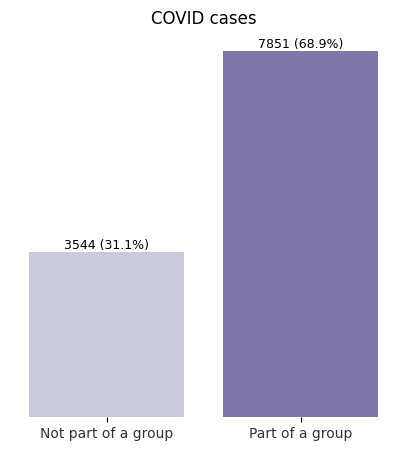

In [45]:
fig = plt.pyplot.figure(figsize=(5, 5))

ax = bar_graph_f(case_group, 'COVID cases', total_cases, 'Purples')
ax.set_xticklabels(['Not part of a group', 'Part of a group'], fontsize=10)

sns.despine(left=True, bottom=True)

Majority of COVID cases started as part of a group.

In [46]:
case['infection_case'].value_counts().head()

infection_case
etc                     17
overseas inflow         17
contact with patient    16
Shincheonji Church      15
Itaewon Clubs            9
Name: count, dtype: int64

Most of infection cases are 'etc', which includes individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation. It's going to be removed for now, to check what other infection cases repeat.

In [47]:
infection_case_count = case['infection_case'].value_counts().iloc[1:]
print(f' There are {len(infection_case_count)} different infection cases.')
infection_case_count.head(5)

 There are 80 different infection cases.


infection_case
overseas inflow         17
contact with patient    16
Shincheonji Church      15
Itaewon Clubs            9
Guro-gu Call Center      4
Name: count, dtype: int64

Most common infection case is overseas inflow it appeared in all 17 provinces. Contact with patient appeared in 16 provinces. There seems to be a lot of cases related to Shincheonji Church. Also in 9 provinces Itaewon Clubs were related to infections. There is also Guro-gu Call Center case which seems to have spread over 4 provinces.

In [48]:
len(infection_case_count[infection_case_count > 1])

20

Out of 80 different infection cases, 20 of them appear more than once.

In [49]:
confirmed_0 = case.loc[case.confirmed == 0]
confirmed_0

,case_id,province,city,group,infection_case,confirmed,latitude,longitude,case_number,area
29,1000030,Seoul,Gangseo-gu,True,SJ Investment Call Center,0,37.559649,126.835102,30,City/district
118,3000007,Gangwon-do,NaN,False,contact with patient,0,NaN,NaN,7,Other
171,7000002,Jeju-do,NaN,False,contact with patient,0,NaN,NaN,2,Other


There are some infection cases where they resulted in 0 confirmed cases for COVID. It seems that contact with a patient, does not always result in COVID or it has incubation period.

In [50]:
highest_confirmed_index = case.confirmed.idxmax()
highest_confirmed = case.loc[highest_confirmed_index]
highest_confirmed

case_id                      1200001
province                       Daegu
city                          Nam-gu
group                           True
infection_case    Shincheonji Church
confirmed                       4511
latitude                    35.84008
longitude                   128.5667
case_number                        1
area                   City/district
Name: 48, dtype: object

Case with highest infection count comes from Daegu province, Shincheonji Church. 

Let's check if there are any other occurences with high confirmed infection count. To do that, we will check for outliers in confirmed cases count. 

### Outliers for confirmed cases

Detecting if there are any outliers within 1.5IQR. We will use Tukey's rule to detect outliers, also known as IQR rule. First, we will calculate the Interquartile Range of the data (IQR = Q3 - Q1). Later we determine our outlier boundaries with IQR.

Outliers will not be removed, as they are valid data points and we are interested in how many confirmed cases there are overall and causes behind them. However, we can check if there is anything interesting about them.

In [51]:
case_confirmed = case.loc[:, 'confirmed']

Q1 = case_confirmed.quantile(0.25)
Q3 = case_confirmed.quantile(0.75)
IQR = Q3 - Q1

# Boundaries
IQR_lower = Q1 - 1.5 * IQR
IQR_upper = Q3 + 1.5 * IQR

In [52]:
outliers_bellow = case_confirmed < IQR_lower
outliers_bellow.sum()

0

No outlier cases with unusually low confirmed count. 

In [53]:
outliers_above = case_confirmed > IQR_upper
outliers_above.sum()

19

In [54]:
case_outliers = case[outliers_above].sort_values('confirmed', ascending=False)
case_outliers.head(10)

,case_id,province,city,group,infection_case,confirmed,latitude,longitude,case_number,area
48,1200001,Daegu,Nam-gu,True,Shincheonji Church,4511,35.840080,128.566700,1,City/district
56,1200009,Daegu,NaN,False,contact with patient,917,NaN,NaN,9,Other
57,1200010,Daegu,NaN,False,etc,747,NaN,NaN,10,Other
145,6000001,Gyeongsangbuk-do,from other city,True,Shincheonji Church,566,NaN,NaN,1,From other city
109,2000020,Gyeonggi-do,abroad,False,overseas inflow,305,NaN,NaN,20,Abroad
35,1000036,Seoul,abroad,False,overseas inflow,298,NaN,NaN,36,Abroad
49,1200002,Daegu,Dalseong-gun,True,Second Mi-Ju Hospital,196,35.857375,128.466651,2,Country
156,6000012,Gyeongsangbuk-do,NaN,False,contact with patient,190,NaN,NaN,12,Other
36,1000037,Seoul,NaN,False,contact with patient,162,NaN,NaN,37,Other
0,1000001,Seoul,Yongsan-gu,True,Itaewon Clubs,139,37.538621,126.992652,1,City/district


In [55]:
case_outliers.province.value_counts()

province
Daegu                6
Seoul                6
Gyeongsangbuk-do     4
Gyeonggi-do          2
Chungcheongnam-do    1
Name: count, dtype: int64

We can see that the case with most infections, Shincheonji Church, is something out of ordinary. This case and 3 more come from Daegu province and are in top 10 infection cases with most confirmed COVID instances. We can also see that Daegu appears 6 times in outlier values. Seoul also appears 6 times in outliers. There are total of 5 provinces in outliers, meaning that the outbreak there is much higher than in the rest of South Koreas provinces.

In [56]:
case_outliers.infection_case.value_counts()

infection_case
etc                                4
contact with patient               3
Shincheonji Church                 2
overseas inflow                    2
Second Mi-Ju Hospital              1
Itaewon Clubs                      1
Hansarang Convalescent Hospital    1
Richway                            1
Cheongdo Daenam Hospital           1
gym facility in Cheonan            1
Daesil Convalescent Hospital       1
Guro-gu Call Center                1
Name: count, dtype: int64

In outliers etc is most occuring infection case. It is not surprising, since it includes individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation, meaning there is a lot of different cases hidden under one value. Contact with patient also has a lot of cases, therefore there is a lot of COVID spread from one person to other person, not in groups. As we can see overseas inflow is also important cause for covid cases. We can also see a lot of hospitals in outlier values. COVID patients are brought there and the infection easelly spread among elderly and sick people. We can also see a club and a gym, which is more likely to have young people there, therefore the virus can spread among younger people as well.

### Case data analysis

In [57]:
case_confirmed_median = case.confirmed.median()
case_confirmed_mean = case.confirmed.mean()
case_confirmed_sem = case.confirmed.sem()  # standart error for mean
lowest_case_outlier = case_outliers.confirmed.min()

print(f'Median for confirmed cases is {case_confirmed_median}.')
print(f'Mean for confirmed cases is {round(case_confirmed_mean, 0)}\u00B1{round(case_confirmed_sem, 0)}.')
print(f'Least cases for outlier is {lowest_case_outlier}.')

Median for confirmed cases is 10.0.
Mean for confirmed cases is 65.0±27.0.
Least cases for outlier is 84.


We can see that median per infection case is only 10 confirmed cases, while the mean is 65. Most of cases result in low confirmed case count, and only a few result in a lot. We can see that from the fact that the lowest outlier case is 84 confirmed cases, just 19 more than the mean.

In [58]:
infection_case_sum = case.groupby(['infection_case']).confirmed.sum().sort_values(ascending=False)

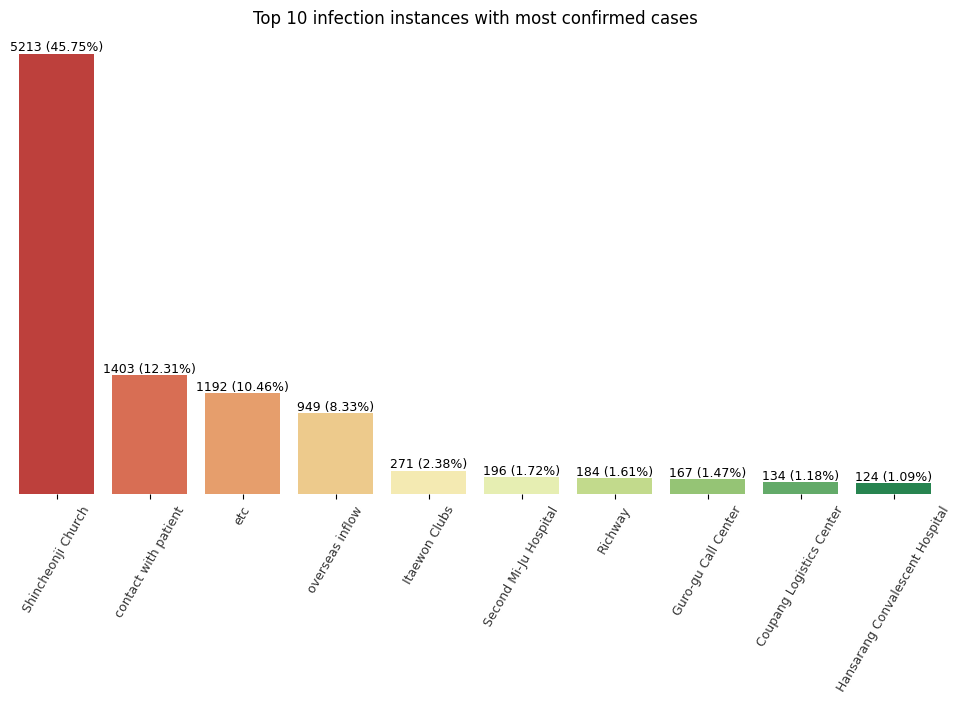

In [59]:
fig = plt.pyplot.figure(figsize=(12, 6))

ax = bar_graph_f(
    infection_case_sum.head(10), 'Top 10 infection instances with most confirmed cases', total_cases, 'RdYlGn'
)
ax.tick_params(axis='x', rotation=60)

sns.despine(left=True, bottom=True)

Most cases (even 45.75%) originated from Shincheonji Churches. Second most prelavent reason why person got COVID was contact with a patient (12.31%). Etc, which includes individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation is 3rd most common (10.46%). Traveling abroad is the 4th most common cause of COVID (8.33%). 

Group acitivities such as going to a church seem to cause most of infection cases. 

Since, infection cases refers to a specific location or activity (for example Shincheonji Church instead of just a church, or religious location), to look for most common activities or locations were people get infected, we need to look for most common words. To do that we need to count separate word occurences instead of infection cases.

In [60]:
words_count_infection_cases = case['infection_case'].str.lower().str.split(expand=True).stack().value_counts()
words_count_infection_cases.head(10)

church         30
overseas       17
etc            17
inflow         17
patient        16
with           16
contact        16
center         15
shincheonji    15
hospital       12
Name: count, dtype: int64

Most common word in infection cases is church, which appeared 30 times. Shincheonji also refers to a church movement in South Korea. Inflow, as we can see from before, always goes with overseas, same for contact with patient. Words which come together with another word will be removed, to get a clearer top ten list. Locations for cities or parts names (like church name) will be removed.

In [61]:
drop_list = [
    'inflow',
    'with',
    'contact',
    'shincheonji',
    'itaewon',
    'in',
    'of',
    'call',
    'logistics',
    'korea',
    'guro-gu',
    'daejeon',
    'convalescent',
    'second',
    'mi-ju',
    'home',
    'coupang',
    'hansarang',
    'cheongdo',
    'daenam',
    'facility',
]

for word in drop_list:
    if word in words_count_infection_cases:
        words_count_infection_cases.drop(word, inplace=True)

words_count_infection_cases.head(10)

church          30
overseas        17
etc             17
patient         16
center          15
hospital        12
clubs            9
door-to-door     4
richway          4
group            4
Name: count, dtype: int64

In [62]:
contains_group = case.infection_case.str.contains('group', case=False)
case.infection_case[contains_group].unique()

array(['SMR Newly Planted Churches Group', 'Anyang Gunpo Pastors Group'],
      dtype=object)

Church is most common word in infection cases. Word group is also related to religious activities. Hospitals, centers, clubs are places where a lot of people gather and they also repeat. Door-to-door refers to sales, and reappears few times. Richway is a health product provider. Etc, like always, refers to individual cases, cases being classified and cases under investigation.

Let's check how many confirmed cases are under different keywords in infection cases

In [63]:
# Creating a dictionary to hold values
common_word_cases_sum = defaultdict()

for word in words_count_infection_cases.index:
    contains_word_mask = case.infection_case.str.contains(fr'{word}\b', case=False, regex=True)
    temp = int(case.confirmed.loc[contains_word_mask].sum())
    common_word_cases_sum[word] = temp

# Creating a series to draw a graph easier
common_word_cases_sum = pd.Series(common_word_cases_sum).sort_values(ascending=False)

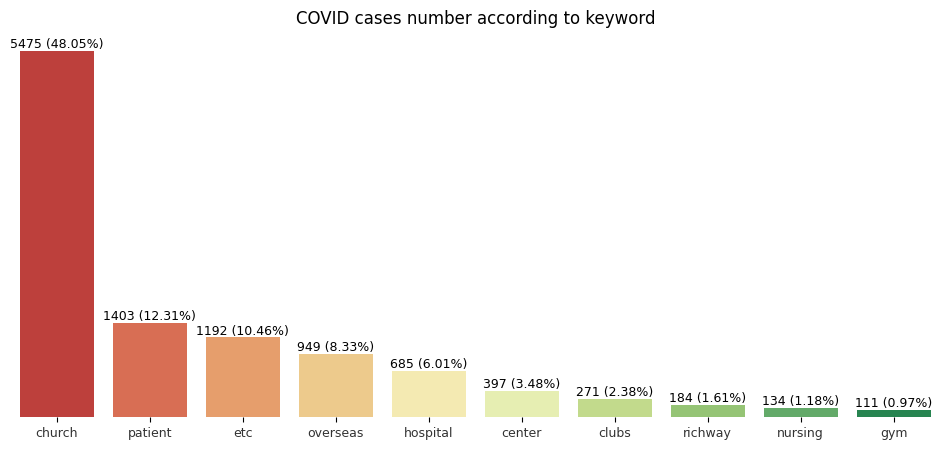

In [64]:
fig = plt.pyplot.figure(figsize=(12, 5))

ax = bar_graph_f(common_word_cases_sum.head(10), 'COVID cases number according to keyword', total_cases, 'RdYlGn')

sns.despine(left=True, bottom=True)

As we can see, the most cases resulted from religious group activities, such as going to church. Other locations where a lot of people meet are in here aswell, such as hospitals, centers, clubs, nursing homes and gyms.  Richway refers to a health product provider and is a part of a group transfers. Patient, refers to patient to patient contact, not a group transfer. Cases under overseas and etc, are also classified as not group transfers.

There might be a lot of cases in churches, because older people tend to be more religious, and althought a mix different age people attend the church, there will be higher percent of older generations. Elderly and immunocompromised (have a weakened immune system) are more susceptible to COVID and its symptoms. We can also see that there are hospitals and nursing homes in this list. Places often visited by younger people, such as clubs or gyms, have much less cases.

Although, majority of cases did come from group activities, there is still a considerable percent of them originating from individual to individual transfers. 

In [65]:
case_area = case.groupby(['area']).confirmed.sum().sort_values(ascending=False)

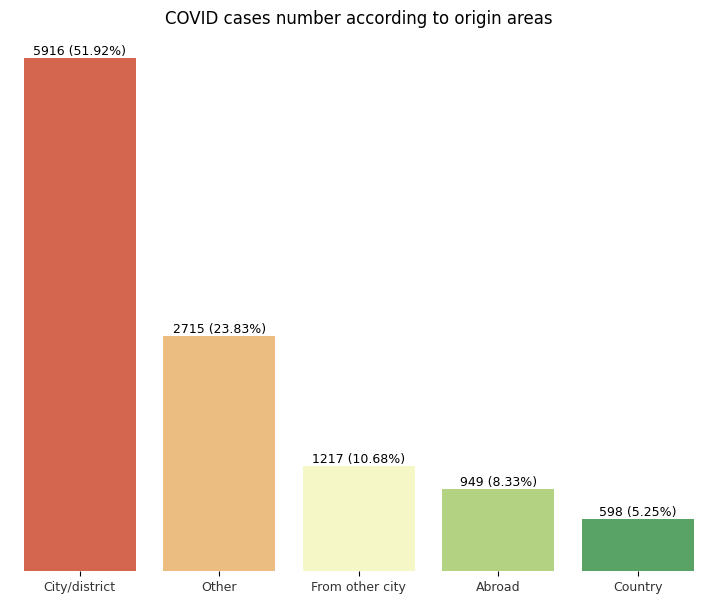

In [66]:
fig = plt.pyplot.figure(figsize=(9, 7))

ax = bar_graph_f(case_area, 'COVID cases number according to origin areas', total_cases, 'RdYlGn')

sns.despine(left=True, bottom=True)

Around half of COVID cases originated from city or city district in the province itself. Value from other city means that they are from the city in another province. Under other are cases which were not located to one area, like door-to-door sales or contact with patient, also individual cases, cases where relevance classification is ongoing after investigation, and cases under investigation. Least amount of cases originated from country, most likely due to low density of people. 8.33% of cases originated from abroad, all of these cases originate from overseas travels.

Highest spread of COVID was in cities, it seems to be related to people density, as in countryside there are ten times less covid cases. Although, spread from other provinces and abroad is much lower, it is still significant.

In [67]:
case_confirmed_province = case.groupby(['province']).confirmed.sum().sort_values(ascending=False)

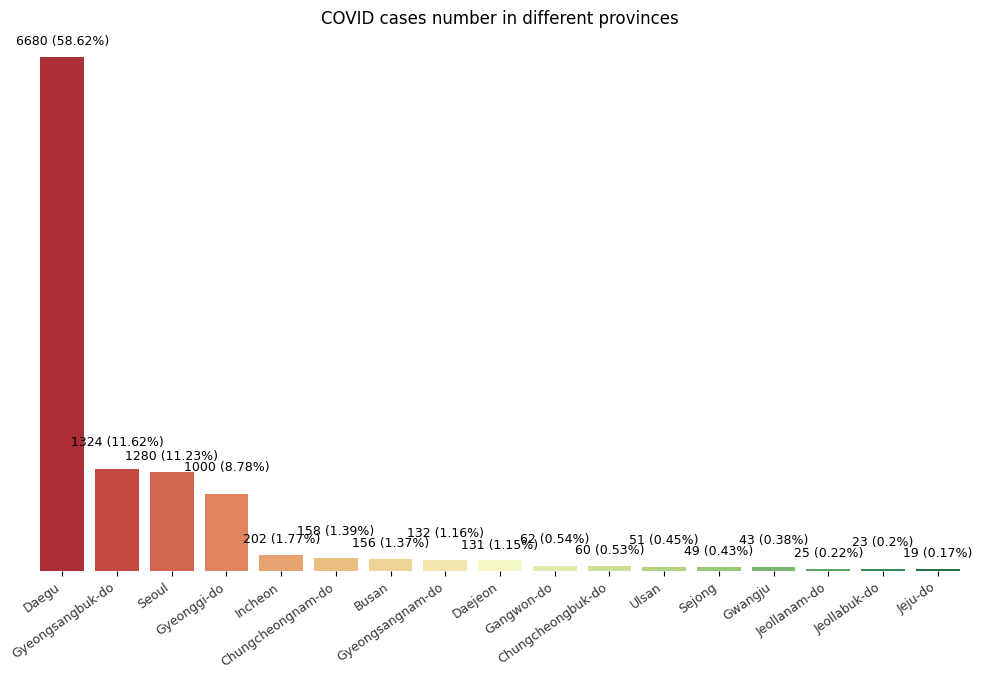

In [68]:
fig = plt.pyplot.figure(figsize=(12, 7))

ax = bar_graph_f(
    case_confirmed_province, 'COVID cases number in different provinces', total_cases, 'RdYlGn', padding=(7, 15)
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")

sns.despine(left=True, bottom=True)

More than half of cases were in Daegu province. Second province by number of COVID cases is Gyeongsangbuk-do with 11.62% of all cases, and third is Seoul with 11.23%. Least amount of cases was in Jeju-do - only 19 (or 0.17% of all cases), Jeollabuk-do – 23 cases (0.2%) and Jeollanam-do – 25 cases (0.22%).

To represent datapoints on the map better, cases with 0 confirmed will be removed. Also the instance with a lot of confirmed cases (outliers). Like in Shincheonji Church will be drawn separatelly.

In [69]:
# Data without outlier points
case_geo_prep = case.drop(case_outliers.index)
case_geo_prep = case_geo_prep.drop(confirmed_0.index)

# Not all cases have location data on it, and we are going to use only that
case_geo_prep = case_geo_prep.dropna(subset=['longitude', 'latitude'])

geo_case = gpd.GeoDataFrame(
    case_geo_prep, geometry=gpd.points_from_xy(case_geo_prep.longitude, case_geo_prep.latitude), crs="EPSG:4326"
)
geo_case.head()

,case_id,province,city,group,infection_case,confirmed,latitude,longitude,case_number,area,geometry
3,1000004,Seoul,Yangcheon-gu,True,Yangcheon Table Tennis Club,43,37.546061,126.874209,4,City/district,POINT (126.87421 37.54606)
4,1000005,Seoul,Dobong-gu,True,Day Care Center,43,37.679422,127.044374,5,City/district,POINT (127.04437 37.67942)
5,1000006,Seoul,Guro-gu,True,Manmin Central Church,41,37.481059,126.894343,6,City/district,POINT (126.89434 37.48106)
7,1000008,Seoul,Dongdaemun-gu,True,Dongan Church,17,37.592888,127.056766,8,City/district,POINT (127.05677 37.59289)
9,1000010,Seoul,Gwanak-gu,True,Wangsung Church,30,37.481735,126.930121,10,City/district,POINT (126.93012 37.48174)


In [70]:
# Just outlier points
case_outliers_geo_prep = case.loc[case_outliers.index]
case_outliers_geo_prep = case_outliers_geo_prep.dropna(subset=['longitude', 'latitude'])

geo_case_outliers = gpd.GeoDataFrame(
    case_outliers_geo_prep,
    geometry=gpd.points_from_xy(case_outliers_geo_prep.longitude, case_outliers_geo_prep.latitude),
    crs="EPSG:4326",
)

In [71]:
# To be able to use location data with contextily
geo_case_map = geo_case.to_crs(epsg=3857)
geo_case_outliers_map = geo_case_outliers.to_crs(epsg=3857)

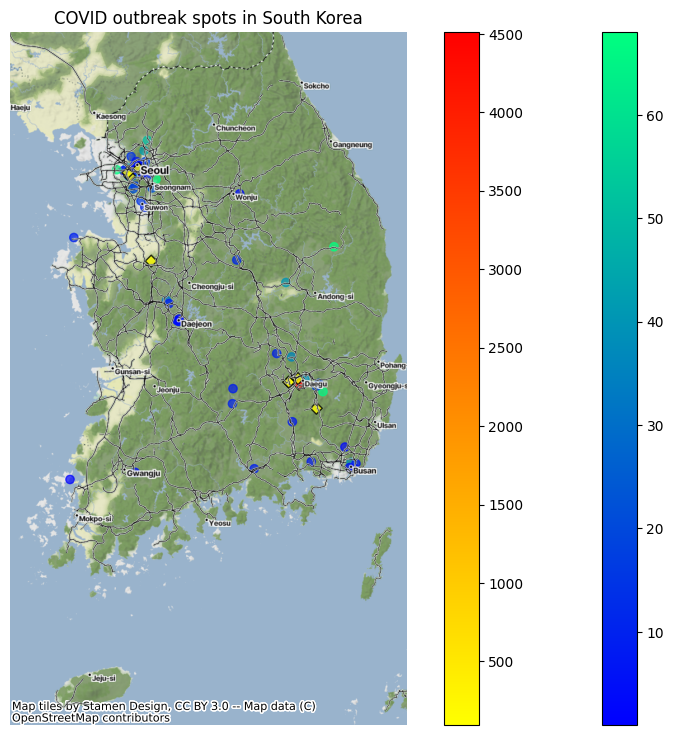

In [72]:
ax1 = geo_case_map.plot('confirmed', figsize=(12, 9), alpha=0.7, cmap='winter', edgecolor=None, legend=True)
ax2 = geo_case_outliers_map.plot(
    'confirmed', ax=ax1, alpha=0.8, cmap='autumn_r', marker='D', edgecolor="k", legend=True
)

ax1.set_title('COVID outbreak spots in South Korea')

# To have whole South Korea on a map
ax1.set_xlim(min(ax1.get_xlim()) - 50000, max(ax1.get_xlim()) + 40000)
ax1.set_ylim(min(ax1.get_ylim()) - 250000, max(ax1.get_ylim()) + 100000)

ax1.set_axis_off()

cx.add_basemap(ax1, source=cx.providers.Stamen.TerrainBackground)
cx.add_basemap(ax1, source=cx.providers.Stamen.TonerLines)
cx.add_basemap(ax1, source=cx.providers.Stamen.TonerLabels)

This is a map with infection cases, for which locations were available. Diamonds represent outliers and circles represent other values. We can see that there are a lot of infection spots with low count of confirmed COVID infections. There are few with higher infection rate, they are marked in yellow. The red diamond shape spot in Daegu is the infection case with most confirmed COVID cases. Most of confirmed locations are in Cities. There are a lot of them around Seoul. Also, there are no outbreak spots in Jeju-Do island of South Korea (bottom, left). From the map it seems, that there are more cases in cities and less in remote areas.

In [73]:
case_number_province = case.groupby(['province']).case_number.max().sort_values(ascending=False)

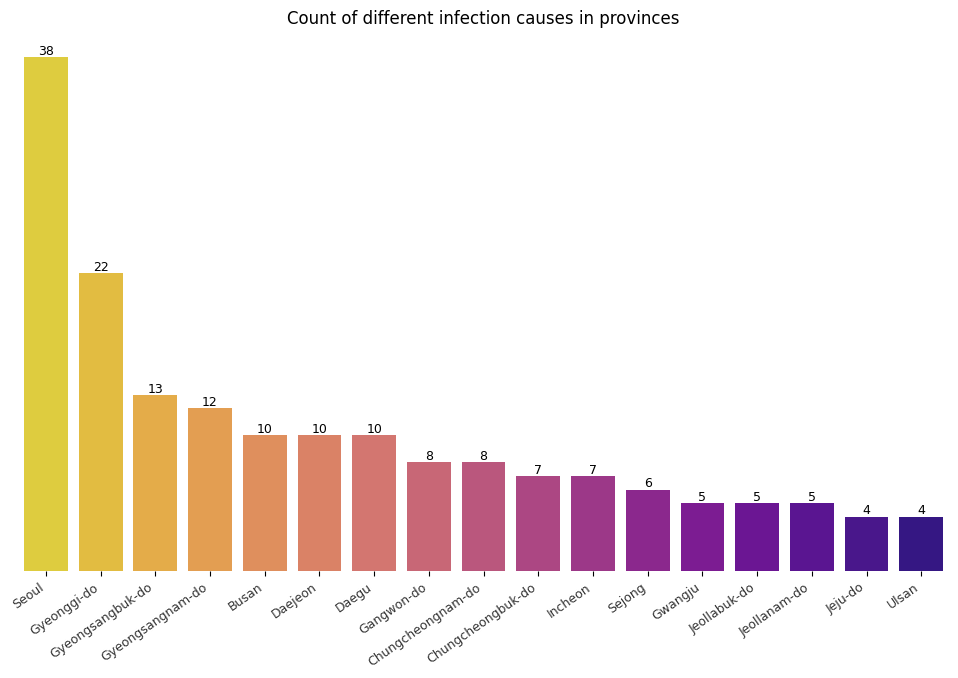

In [74]:
fig = plt.pyplot.figure(figsize=(12, 7))

ax = bar_graph_f_no_percent(case_number_province, 'Count of different infection causes in provinces', 'plasma_r')
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")

sns.despine(left=True, bottom=True)

Seoul has most of different infection causes out of all provinces, and they were 3rd in infection amount. Daegu on other hand had most confirmed cases and only a few different infection reasons. 

We can check if there is any correlation between different cases count and confirmed cases count. 

In [75]:
case_grouped_province = pd.concat(
    {'infection cases count': case_number_province, 'total confirmed': case_confirmed_province},
    axis=1,
)
case_grouped_province.head()

,infection cases count,total confirmed
province,,
Seoul,38,1280
Gyeonggi-do,22,1000
Gyeongsangbuk-do,13,1324
Gyeongsangnam-do,12,132
Busan,10,156


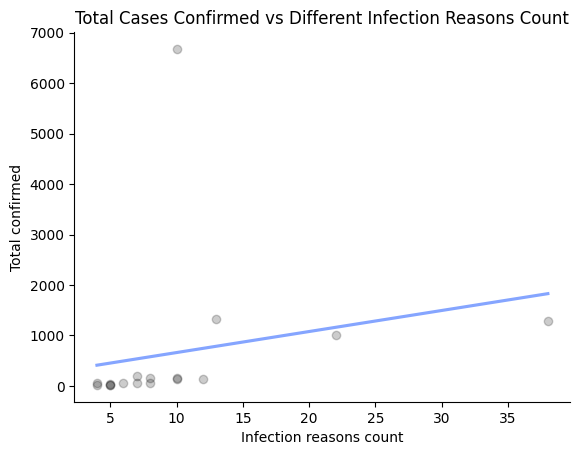

In [76]:
ax = sns.regplot(
    x=case_grouped_province['infection cases count'],
    y=case_grouped_province['total confirmed'],
    ci=None,
    scatter_kws={"color": "black", "alpha": 0.2},
    line_kws={"color": "#85A5FF"},
)
ax.set(
    title='Total Cases Confirmed vs Different Infection Reasons Count',
    ylabel='Total confirmed',
    xlabel='Infection reasons count',
)
sns.despine()

In [77]:
case_correlation_linear = case_grouped_province.corr()
case_correlation_linear

,infection cases count,total confirmed
infection cases count,1.000000,0.217537
total confirmed,0.217537,1.000000


In [78]:
case_correlation_monotone = case_grouped_province.corr(method='spearman')
case_correlation_monotone

,infection cases count,total confirmed
infection cases count,1.000000,0.845177
total confirmed,0.845177,1.000000


We can see some tendencies for confirmed case number increase with the number of different infection reasons, but they seem to be more monotonic instead of linear, as we can see from different methods used to calculate correlation coefficients (method used to calculate monotonic relation produced strong correlation, while for linear only weak). It means that the more different spots for infection the more confirmed cases there are. However, even if we can see correlation between confirmed cases and different infection reasons (spots) counts, the matter is more complex than just reducing different places for people to meet up, as we saw from the massive amount of confirmed cases originating from one church. It seems that it is more important to prevent massive people meetings, spread in hospitals (as people in hospitals will be affected by COVID the worst) and find ways to deal with overseas inflow.

## Patient

Information about patient dataset:

Epidemiological data of COVID-19 patients in South Korea

    patient_id: the ID of the patient

            patient_id(10) = region_code(5) + patient_number(5)
            You can check the region_code in 'Region.csv'
            There are two types of the patient_number
            1) local_num: The number given by the local government.
            2) global_num: The number given by the KCDC

    sex: the sex of the patient
    age: the age of the patient

            0s: 0 ~ 9
            10s: 10 ~ 19
            ...
            90s: 90 ~ 99
            100s: 100 ~ 109

    country: the country of the patient
    province: the province of the patient
    city: the city of the patient
    infection_case: the case of infection
    infected_by: the ID of who infected the patient

            This column refers to the 'patient_id' column.

    contact_number: the number of contacts with people
    symptom_onset_date: the date of symptom onset
    confirmed_date: the date of being confirmed
    released_date: the date of being released
    deceased_date: the date of being deceased
    state: isolated / released / deceased

            isolated: being isolated in the hospital
            released: being released from the hospital
            deceased: being deceased

#### Patient dataframe null values 

In [79]:
patient_missing = patient.isnull().sum()
patient_missing

patient_id               0
sex                   1122
age                   1380
country                  0
province                 0
city                    94
infection_case         919
infected_by           3819
contact_number        4374
symptom_onset_date    4475
confirmed_date           3
released_date         3578
deceased_date         5099
state                    0
dtype: int64

We can see that there is a lot of missing information about the patients. Removing missing values would also drop most of collected data and there is nothing to fill them with. Also some of the values should not be there, for example, deceased_date will not be there if the person did not die. 

### Exploring patient data

In [80]:
patient.dtypes

patient_id             int64
sex                   object
age                   object
country               object
province              object
city                  object
infection_case        object
infected_by           object
contact_number        object
symptom_onset_date    object
confirmed_date        object
released_date         object
deceased_date         object
state                 object
dtype: object

Patient_id should be categorical data, also symptom_onset_date, confirmed_date, released_date and deceased_date should be datetime columns. Patient data should also be converted into a numerical data.

In [81]:
patient['contact_number'].unique()

array(['75', '31', '17', '9', '2', '43', '0', '68', '6', '23', '117',
       '27', '8', nan, '4', '3', '1', '1000000796', '13', '12', '1091',
       '131', '16', '14', '485', '19', '296', '15', '34', '37', '22', '7',
       '10', '28', '21', '5', '25', '18', '159', '11', '30', '41', '71',
       '38', '24', '185', '69', '39', '1160', '450', '65', '156', '47',
       '86', '74', '46', '64', '66', '40', '20', '42', '107', '29', '26',
       '45', '-', '95', '422', '290', '32', '53', '70', '35', '51', '130',
       '106', '174', '78', '33', '89', '61', '113', '36', '6100000098',
       '6100000099', '87', '84', '140', '72'], dtype=object)

We can see that there is '-'. Also, we see some numbers, which are imposible as contact, like '1000000796', which is more than population of South Korea itself (it had population of around 52 million in year 2020). These values are going to be replaced with NaN.

In [82]:
to_replace = ['-', '1000000796', '6100000098', '6100000099']
for value in to_replace:
    patient.contact_number.replace(value, np.nan, inplace=True)

patient['contact_number'].unique()

array(['75', '31', '17', '9', '2', '43', '0', '68', '6', '23', '117',
       '27', '8', nan, '4', '3', '1', '13', '12', '1091', '131', '16',
       '14', '485', '19', '296', '15', '34', '37', '22', '7', '10', '28',
       '21', '5', '25', '18', '159', '11', '30', '41', '71', '38', '24',
       '185', '69', '39', '1160', '450', '65', '156', '47', '86', '74',
       '46', '64', '66', '40', '20', '42', '107', '29', '26', '45', '95',
       '422', '290', '32', '53', '70', '35', '51', '130', '106', '174',
       '78', '33', '89', '61', '113', '36', '87', '84', '140', '72'],
      dtype=object)

In [83]:
patient['patient_id'] = patient['patient_id'].astype(str)
patient['contact_number'] = patient['contact_number'].astype(float)

to_date_list = ['symptom_onset_date', 'confirmed_date', 'released_date', 'deceased_date']
for col in to_date_list:
    patient[col] = pd.to_datetime(patient[col], errors='coerce')

patient.dtypes

patient_id                    object
sex                           object
age                           object
country                       object
province                      object
city                          object
infection_case                object
infected_by                   object
contact_number               float64
symptom_onset_date    datetime64[ns]
confirmed_date        datetime64[ns]
released_date         datetime64[ns]
deceased_date         datetime64[ns]
state                         object
dtype: object

In [84]:
total_patient_nr = patient.shape[0]
total_patient_nr

5165

There are 5165 patient data recorded in patient dataset.

In [85]:
patient_start_end = patient.confirmed_date.agg(['min', 'max'])
patient_start_end

min   2020-01-20
max   2020-06-30
Name: confirmed_date, dtype: datetime64[ns]

This dataset was taken for a little bit longer than 5 months: from 2020-01-20 to 2020-06-30.

In [86]:
patient_state = patient.state.value_counts()

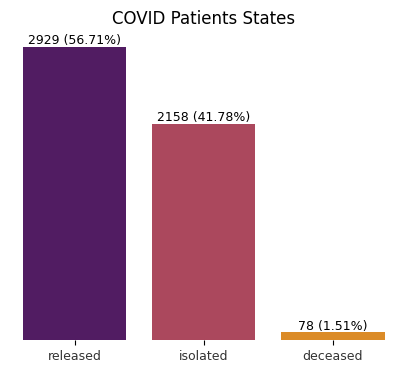

In [87]:
fig = plt.pyplot.figure(figsize=(5, 4))

ax = bar_graph_f(patient_state, 'COVID Patients States', total_patient_nr, 'inferno')

sns.despine(left=True, bottom=True)

From the collected data we can see that 56.71% of COVID patients were released. 41.78% of patients were in isolations by the time this dataset was obtained. 1.51% of patients are deceased.

In [88]:
total_contact = patient.contact_number.sum()
total_contact

13583.0

In [89]:
patient.contact_number.describe()

count     784.000000
mean       17.325255
std        67.533881
min         0.000000
25%         2.000000
50%         4.000000
75%        14.000000
max      1160.000000
Name: contact_number, dtype: float64

In [90]:
patient.loc[patient.contact_number.idxmax()]

patient_id                     1200000031
sex                                female
age                                   60s
country                             Korea
province                            Daegu
city                                  NaN
infection_case         Shincheonji Church
infected_by                           NaN
contact_number                     1160.0
symptom_onset_date                    NaT
confirmed_date        2020-02-18 00:00:00
released_date                         NaT
deceased_date                         NaT
state                            isolated
Name: 1463, dtype: object

We can see that one patient had even 1160 contacts. It is a patient from Shincheonji Church. As we saw from case dataset, it was an event with a lot of confirmed covid cases.

In [91]:
patient_contact_median = patient.contact_number.median()
patient_contact_mode = patient.contact_number.mode()
patient_contact_mean = patient.contact_number.mean()
patient_contact_sem = patient.contact_number.sem()  # standart error for mean

print(f'Median for patient contact is {patient_contact_median}.')
print(f'Mode for patient contact is {patient_contact_mode[0]}.')
print(f'Mean for patient contact is {round(patient_contact_mean, 0)}\u00B1{round(patient_contact_sem, 0)}.')

Median for patient contact is 4.0.
Mode for patient contact is 3.0.
Mean for patient contact is 17.0±2.0.


On average one patient had contact with 17 patients. The value which appears most often is 3, therefore most patients had contact with 3 other people.

In [92]:
timeline_confirmed = patient.confirmed_date.value_counts().sort_index()

In [93]:
# to color the graph:
Q1 = timeline_confirmed.quantile(0.25)
Q3 = timeline_confirmed.quantile(0.75)
IQR = Q3 - Q1

# Boundaries
IQR_lower = Q1 - 1.5 * IQR
IQR_upper = Q3 + 1.5 * IQR

In [94]:
bellow = timeline_confirmed < IQR_lower
bellow.sum()

0

In [95]:
above = timeline_confirmed > IQR_upper
above.sum()

7

In [96]:
timeline_deceased = patient.deceased_date.value_counts().sort_index()
timeline_released = patient.released_date.value_counts().sort_index()

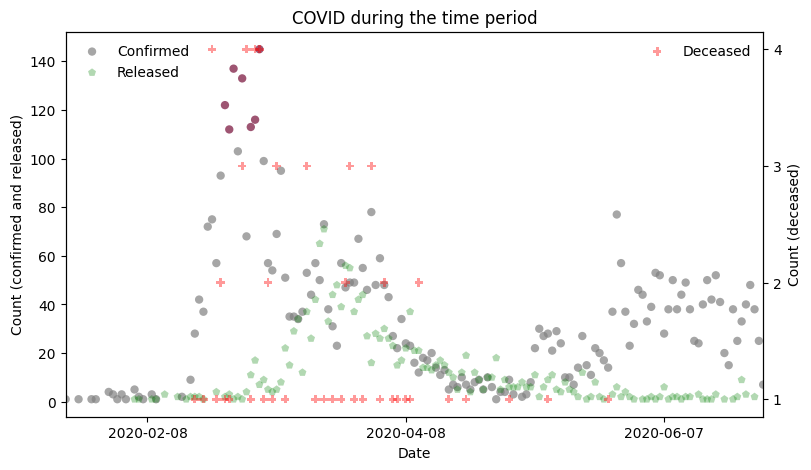

In [97]:
fig = plt.pyplot.figure(figsize=(9, 5))

clrs = ['grey' if (x < IQR_upper) else '#750D37' for x in timeline_confirmed]

ax = scatter_graph_f(timeline_confirmed, timeline_confirmed.index, alpha=0.7, color=clrs)
ax = scatter_graph_f(timeline_released, timeline_released.index, alpha=0.3, color='green', marker='p')

ax2 = ax.twinx()
ax2 = scatter_graph_f(timeline_deceased, timeline_deceased.index, marker='P', color='red')

ax.set(title='COVID during the time period', ylabel='Count (confirmed and released)')
ax.set_xlim(patient_start_end)
ax2.set(ylabel='Count (deceased)')
ax2.set_yticks([1, 2, 3, 4])
ax.legend(['Confirmed', 'Released'], frameon=False, fontsize=10, loc='upper left')
ax2.legend(['Deceased'], frameon=False, fontsize=10);

Purple circles indicate outlier values for days with a lot of confirmed values. We can see that confirmed count rises in waves. The second wave was smaller than the first one and maximums for waves are separated around by 3 months. After the 1st wave there was also a wave of released patients, meaning there was increased capacity for hospitals. During the 1st wave there seems to be an increase of deceased as they become more frequent. Note: released and deceased counts should be higher since not all dates were recorded.

To see how isolated amount of patients in hospitals changed over time, we need to remove the amount of deceased and released people in that day. Since not all released and deceased patients have release and decease dates, I will use cofirmation date as released or deceased date.

In [98]:
# making a copy to not overwrite original dataset
deceased_date_filled = patient.deceased_date.copy()
mask = patient.state == 'deceased'
deceased_date_filled.loc[mask] = deceased_date_filled.loc[mask].fillna(patient.confirmed_date)
deceased_filled_counts = deceased_date_filled.value_counts()

In [99]:
released_date_filled = patient.released_date.copy()
mask = patient.state == 'releasead'
released_date_filled.loc[mask] = released_date_filled.loc[mask].fillna(patient.confirmed_date)
released_filled_counts = released_date_filled.value_counts()

In [100]:
cumsum_confirmed = timeline_confirmed.cumsum()

In [101]:
# Creating dataframe to align indexes.
counts = pd.concat(
    {
        'confirmed_cumsum': cumsum_confirmed,
        'confirmed': timeline_confirmed,
        'released': released_filled_counts,
        'deceased': deceased_filled_counts,
    },
    axis=1,
)
counts.isnull().sum()

confirmed_cumsum      4
confirmed             4
released             22
deceased            104
dtype: int64

In [102]:
# First fill in missing cumsum values, for dates when there were no new confirmed cases
counts.confirmed_cumsum.ffill(inplace=True)

# Fill the days when there were no deceased or released patients
counts.fillna(0, inplace=True)
counts.isnull().sum()

confirmed_cumsum    0
confirmed           0
released            0
deceased            0
dtype: int64

In [103]:
counts['isolated'] = counts.confirmed_cumsum - counts.released - counts.deceased

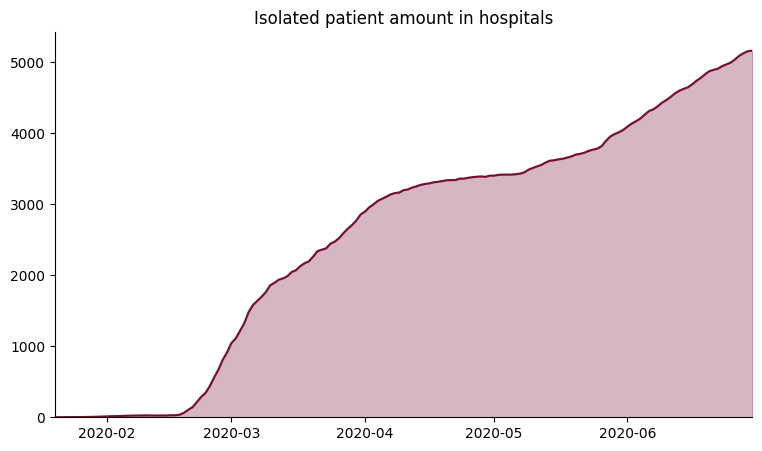

In [104]:
fig = plt.pyplot.figure(figsize=(9, 5))

ax = sns.lineplot(x=counts.index, y=counts['isolated'], color='#750D37')

ax.fill_between(counts.index, counts['isolated'], color='#750D37', alpha=0.3)

ax.set_xlim(patient_start_end)
ax.set_ylim(0)
ax.set(title='Isolated patient amount in hospitals', ylabel='')

sns.despine()

### Exploring contact number outliers

Checking for outliers. They will not be removed, but data surounding them will be investigated, as we are interested in cases with most of contacts.

In [105]:
patient_contact_number = patient.loc[:, 'contact_number'].dropna()

Q1 = patient_contact_number.quantile(0.25)
Q3 = patient_contact_number.quantile(0.75)
IQR = Q3 - Q1

# Boundaries
IQR_lower = Q1 - 1.5 * IQR
IQR_upper = Q3 + 1.5 * IQR

In [106]:
outliers_bellow = patient_contact_number < IQR_lower
outliers_bellow.sum()

0

In [107]:
outliers_above = patient_contact_number > IQR_upper
outliers_above.sum()

74

74 patients had unusually high COVID transfer rate.

In [108]:
contact_outlier_index = patient_contact_number.loc[outliers_above].index
contact_outlier = patient.loc[contact_outlier_index].sort_values('contact_number', ascending=False)
contact_outlier.head()

,patient_id,sex,age,country,province,city,infection_case,infected_by,contact_number,symptom_onset_date,confirmed_date,released_date,deceased_date,state
1463,1200000031,female,60s,Korea,Daegu,NaN,Shincheonji Church,NaN,1160.0,NaT,2020-02-18,NaT,NaT,isolated
1312,1100000001,male,10s,Korea,Busan,Dongnae-gu,Onchun Church,NaN,1091.0,NaT,2020-02-21,NaT,NaT,released
1318,1100000007,male,20s,China,Busan,NaN,Shincheonji Church,NaN,485.0,NaT,2020-02-22,NaT,NaT,released
1600,1300000001,female,40s,Korea,Gwangju,NaN,overseas inflow,NaN,450.0,2020-01-27,2020-02-03,2020-02-20,NaT,released
2215,2000000003,male,40s,China,Gyeonggi-do,Bucheon-si,contact with patient,NaN,422.0,NaT,2020-02-01,2020-02-18,NaT,released


Churches appear 3 times as infection spots in top 5 patients with most contacts. We also see overseas inflow and contact with patient as infection reasons. These reasons were most infectious ones in case dataset also.

In [109]:
contact_outlier.country.value_counts()

country
Korea         70
China          3
Bangladesh     1
Name: count, dtype: int64

3 patients in outlier contacts come from China and one from Bangladesh. Majority come from Korea.

In [110]:
# Unknowns will not be included since we do not know their gender
contact_outlier_sex = (
    contact_outlier.groupby('sex').contact_number.mean().dropna().sort_values(ascending=False).astype(int)
)
contact_outlier_count_sex = contact_outlier.sex.value_counts().dropna()

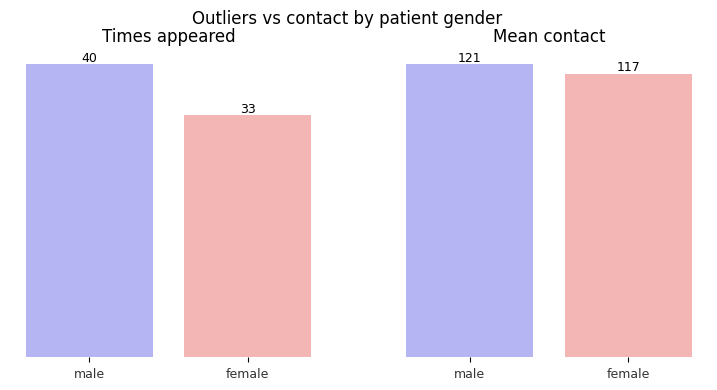

In [111]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(9, 4))
fig.suptitle('Outliers vs contact by patient gender', fontsize=12)

ax1 = bar_graph_f_no_percent(contact_outlier_count_sex, 'Times appeared', 'bwr', ax=axs[0])
ax2 = bar_graph_f_no_percent(contact_outlier_sex, 'Mean contact', 'bwr', ax=axs[1])

sns.despine(left=True, bottom=True)

We can see that males appear in outliers more often than females. Also they had more contacts on average than females, but the difference is not very high and does not seem to be significant.

In [112]:
outlier_province_count = contact_outlier.province.value_counts()
outlier_province_contact_mean = contact_outlier.groupby('province').contact_number.mean().sort_values(ascending=False)

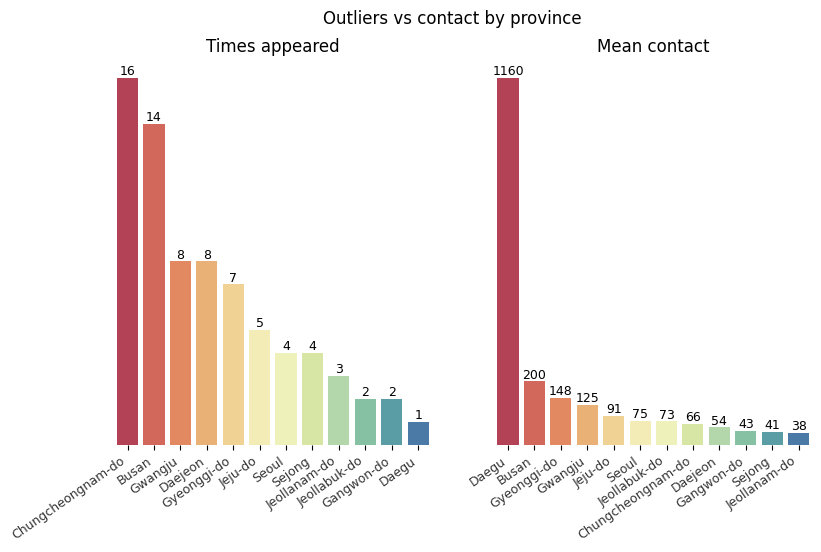

In [113]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(9, 5))
fig.suptitle('Outliers vs contact by province', fontsize=12)

ax1 = bar_graph_f_no_percent(outlier_province_count, 'Times appeared', 'Spectral', ax=axs[0])
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=35, ha="right")

ax2 = bar_graph_f_no_percent(outlier_province_contact_mean.astype(int), 'Mean contact', 'Spectral', ax=axs[1])
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha="right")

sns.despine(left=True, bottom=True)

Chungcheongnam-do province appears most times in outlier values, however Daegu has one outlier with a lot of cases, making it highest on average.

In [114]:
outlier_infection_case_counts = contact_outlier.infection_case.value_counts()
outlier_infection_case_means = (
    contact_outlier.groupby('infection_case').contact_number.mean().sort_values(ascending=False)
)

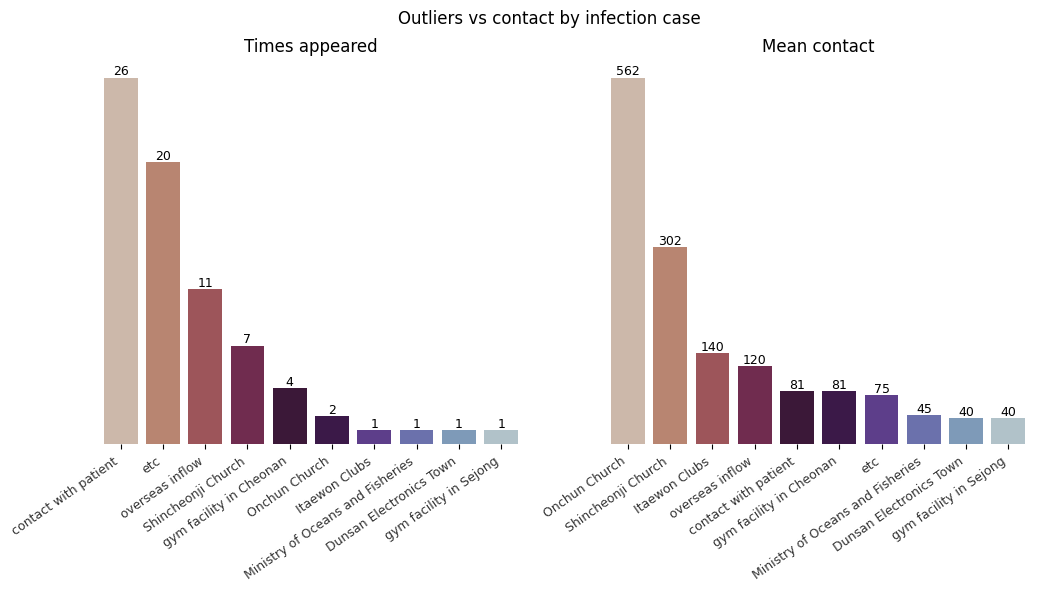

In [115]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Outliers vs contact by infection case', fontsize=12)

ax1 = bar_graph_f_no_percent(outlier_infection_case_counts, 'Times appeared', 'twilight_r', ax=axs[0])
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=35, ha="right")

ax2 = bar_graph_f_no_percent(outlier_infection_case_means.astype(int), 'Mean contact', 'twilight_r', ax=axs[1])
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha="right")

sns.despine(left=True, bottom=True)

Contact with patient is the reason which genereated most of outliers in contacts. Etc stands for miscellaneous cases. Overseas inflow is a third cause which generates outlier contact as it appears 11 times. There are two churches and gyms in which COVID patients had a lot of contacts. Churches also top mean contacts per patient. One patient had a lot of contacts in a club. 

In [116]:
outlier_age_counts = contact_outlier.age.value_counts().dropna().sort_index()
outlier_age_means = contact_outlier.groupby('age').contact_number.mean().astype(int).dropna().sort_index()

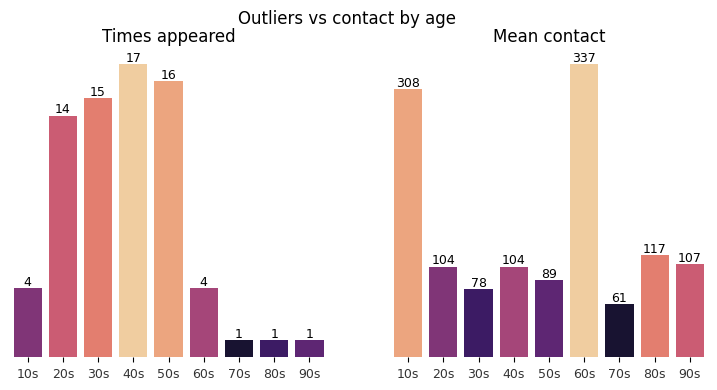

In [117]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(9, 4))
fig.suptitle('Outliers vs contact by age', fontsize=12)

pal_name = 'magma_r'

ax1 = bar_graph_f_no_percent(
    outlier_age_counts, 'Times appeared', palette_by_value(outlier_age_counts, pal_name), ax=axs[0]
)
ax2 = bar_graph_f_no_percent(
    outlier_age_means, 'Mean contact', palette_by_value(outlier_age_means, pal_name), ax=axs[1]
)

sns.despine(left=True, bottom=True)

People in their forties appear most times in outliers. There are also a lot COVID patients in fifties, thirties and twenties. The most spread on average was from people in their sixties and adolescences. It is likely that people in these age groups happened to be in huge gatherings where it is much easier to spread COVID, and therefore mean contact is much higher for them, than any other age group.

### Exploring whole patient dataset

In [118]:
patient_gender = patient.dropna(subset=['sex'])
patient_gender_count = patient_gender.sex.value_counts()
patient_gender_contact = patient_gender.groupby('sex').contact_number.sum()
patient_gender_state = patient_gender.groupby('sex').state.value_counts()
total_patient_gender = len(patient_gender)

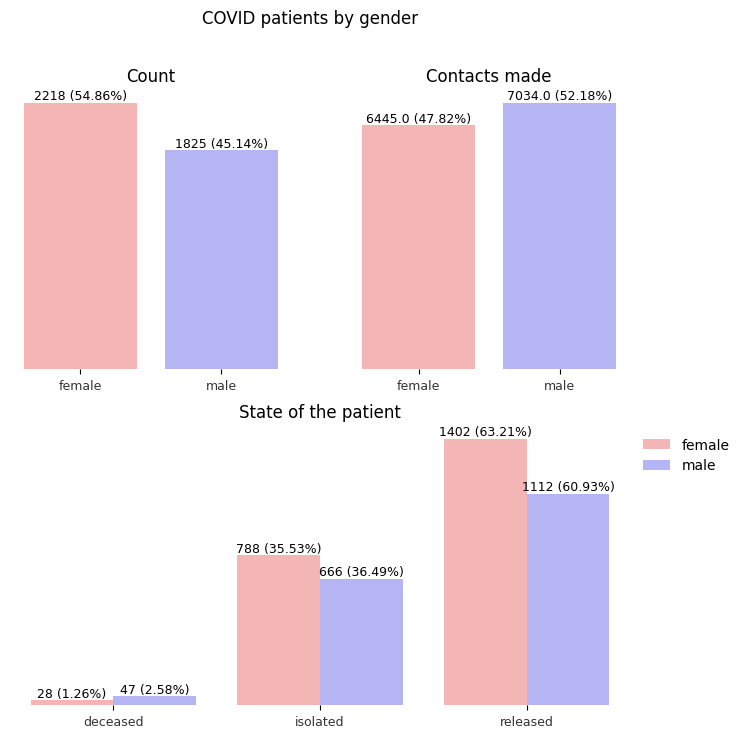

In [119]:
fig = plt.pyplot.figure(figsize=(8, 8))
fig.suptitle('COVID patients by gender', fontsize=12)

ax1 = plt.pyplot.subplot(2, 2, 1)
ax1 = bar_graph_f(patient_gender_count, 'Count', total_patient_gender, 'bwr_r')
ax2 = plt.pyplot.subplot(2, 2, 2)
ax2 = bar_graph_f(patient_gender_contact, 'Contacts made', patient_gender_contact.sum(), 'bwr_r')
ax3 = plt.pyplot.subplot(2, 1, 2)
ax3 = bar_graph_f_multi_hue(patient_gender_state, 'state', 'sex', 'State of the patient', 'bwr_r')

sns.despine(left=True, bottom=True)

There were more females than males in the dataset, but males made more contacts with others. Also, the virus was more deadly to males compared to females, as 1.26% of females died compared to 2.58% of males.

In [120]:
patient_country = patient.country.value_counts()
len(patient_country)

16

There is 16 different patient countries in the dataset.

In [121]:
mask = patient_country > 1
patient_country[mask]

country
Korea            5123
China              11
Foreign             7
United States       6
Bangladesh          5
Thailand            2
Indonesia           2
Name: count, dtype: int64

Only 6 of these countries appear more than once. Majority of patients come from South Korea. We can also see country foreign, which indicates that the patient was a foreigner, but their country is unknown. 

In [122]:
patient_province_count = patient.province.value_counts()
patient_province_contact = patient.groupby('province').contact_number.sum().sort_values(ascending=False).astype(int)
patient_province_state = patient.groupby('province').state.value_counts()
total_patient_province = len(patient.dropna(subset=['province']))

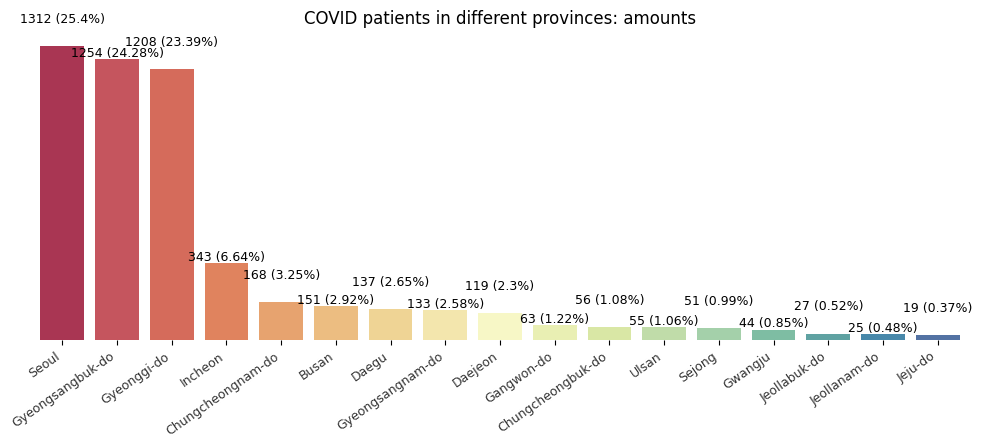

In [123]:
fig = plt.pyplot.figure(figsize=(12, 4))
ax = bar_graph_f(
    patient_province_count,
    'COVID patients in different provinces: amounts',
    total_patient_province,
    'Spectral',
    padding=(15, 0),
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")

sns.despine(left=True, bottom=True)

In this data set most of COVID patients were from Seoul. A little bit less of patients in Gyengsangbuk-do and Gyenggi-do. Incheon, which is close to Seoul, has only 343 patients, compared to Seoul with 1312. Jeju-do, which is a remote island in South Korea, has least amount of the patients: only 19. Overall, least amount of patients in dataset were from west-south parts of South Korea: Gwangju, Jeollabuk-do, Jeollanam-do and Jeju-do.

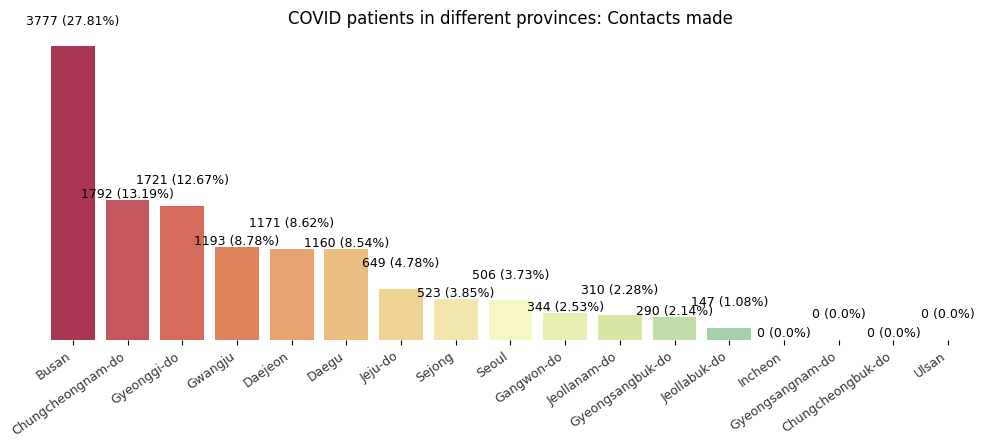

In [124]:
fig = plt.pyplot.figure(figsize=(12, 4))

ax = bar_graph_f(
    patient_province_contact,
    'COVID patients in different provinces: Contacts made',
    patient_province_contact.sum(),
    'Spectral',
    padding=(14, 0),
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
sns.despine(left=True, bottom=True)

Most of contacts made were in Busan, 27.81% of all contacts recorded by this dataset. That's twice as many contacts as in second place Chungcheongnam-do (13.19%). On other hand there were no contacts recorded in this dataset which were made in Incheon, Gyeongsangnam-do, Chungcheongbuk-do and Ulsan.

In [125]:
# Filling missing values with 0 for graphs
patient_province_state = patient_province_state.unstack().fillna(0).stack()

In [126]:
def plots_in_subplot(multi_index_s, index_list, palette, column_count=4):
    '''
    This is a helper function to draw barplots in subplots from a
    multiindex series.

    column_count is how many columns we have in subplot grid.
    '''
    i = 0
    j = 0
    for thing in index_list:
        total = multi_index_s[thing].sum()
        # place in subplot:
        place = axs[j, i]
        i += 1
        if i == column_count:
            i = 0
            j += 1
        ax = bar_graph_f(multi_index_s[thing].astype(int), thing, total, palette, ax=place)

    while i < column_count:
        place = axs[j, i]
        place.tick_params(left=False, bottom=False)
        place.set(ylabel=None, xlabel=None, yticklabels=[], xticklabels=[])
        i += 1

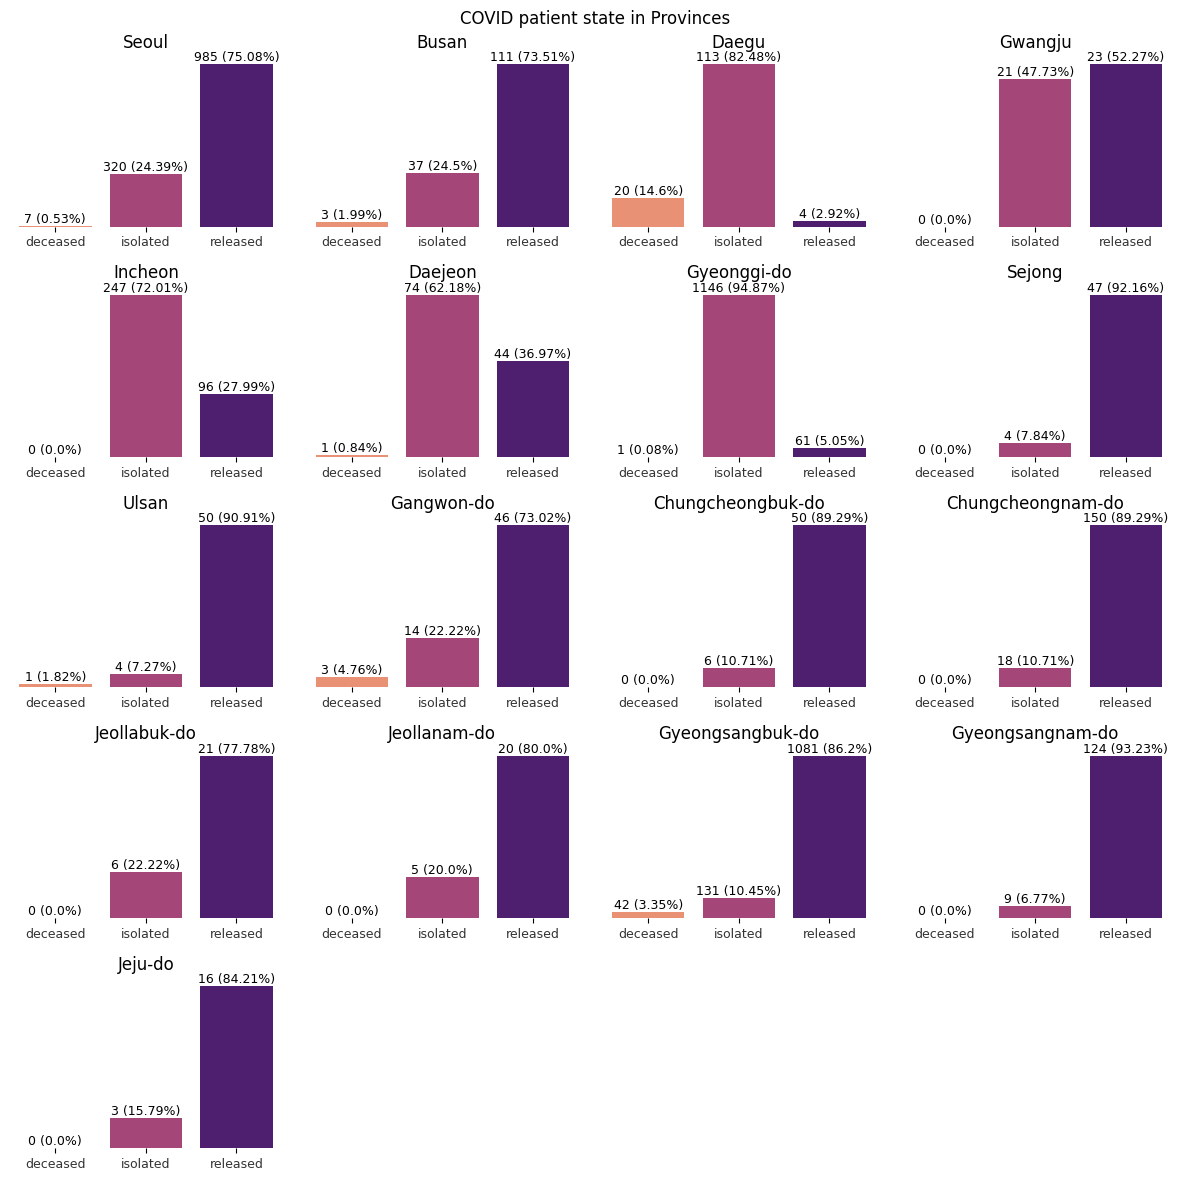

In [127]:
p_provinces = patient.province.unique()

fig, axs = plt.pyplot.subplots(5, 4, figsize=(12, 12))
fig.suptitle('COVID patient state in Provinces', fontsize=12)
fig.subplots_adjust(top=0.95)

plots_in_subplot(patient_province_state, p_provinces, 'magma_r')

fig.tight_layout()
sns.despine(left=True, bottom=True)

Each province has COVID patients in isolation and released, but not every province has deceased patients. Provinces with 0% deceased: Sejong, Gwangju, Incheon, Chungcheongbuk-do, Chungcheongnam-do, Jeollabuk-do, Jeollanam-do, Gyeongsangnam-do and Jeju-do. Highest percentage of deceased patients is in Daegu: even 14.6% of patients died. Second highest mortality rate is only 4.76% in Gangwon-do. However, most deceased patients are in Gyeongsangbuk-do (42 and 3.35% mortality rate), thats twice as much as in Daegu (20).

Majority of provinces have more released patients than isolated ones. Provinces with higher percent of isolated patients than released ones: Daegu, Incheon, Daejeon and Gyeonggi-do. Gyeonggi-do has highest percent of isolated patients (94.87%, in total 1146 pateints), and Ulsan has lowest percent of isolated patients (7.27%, or 4 patients). Lowest amount of isolated patients is in Jeju-do - 3, but they have a low amount of total patients (19), therefore isolated percent is high (15.79%).

Highest percent of released patients is in Gyeongsangnam-do (93.23%, or 124 in total), lowest in Daegu (2.92%, or 4 released, which is also a lowest amount). Gyeongsangbuk-do has highest amount of released patients (1081).

In [128]:
patient.infection_case.value_counts().head()

infection_case
contact with patient    1610
overseas inflow          840
etc                      703
Itaewon Clubs            162
Richway                  128
Name: count, dtype: int64

In [129]:
patient_words_infection = patient['infection_case'].str.lower().str.split(expand=True).stack().value_counts()

In [130]:
drop_list = [
    'inflow',
    'with',
    'contact',
    'shincheonji',
    'itaewon',
    'in',
    'of',
    'call',
    'logistics',
    'korea',
    'guro-gu',
    'daejeon',
    'convalescent',
    'second',
    'mi-ju',
    'home',
    'coupang',
    'hansarang',
    'cheongdo',
    'daenam',
    'facility',
    'yangcheon',
    'table',
    'club',
    'day',
    'care',
]

for word in drop_list:
    if word in patient_words_infection:
        patient_words_infection.drop(word, inplace=True)

top_10_keywords = patient_words_infection.head(10)
top_10_keywords

patient     1610
overseas     840
etc          703
center       254
church       189
clubs        162
richway      128
nursing       46
tennis        44
hospital      37
Name: count, dtype: int64

In patient dataset we can see some difference in most common keywords in infection cases. While in case dataset most common cause for COVID was meetings churches, in patient daset it is contacts with other patients.

In [131]:
symptom_to_confirm = (patient.confirmed_date - patient.symptom_onset_date).dropna()
len(symptom_to_confirm)

688

There are 688 patients recorded with symptom onset dates.

In [132]:
symptom_to_confirm_df = pd.DataFrame(symptom_to_confirm)
# Converting days column to int, to draw a graph easier
symptom_to_confirm_df['days'] = symptom_to_confirm_df.iloc[:, 0].astype(str).str.split(" ", expand=True)[0].astype(int)

In [133]:
print(
    f'On average {round(symptom_to_confirm_df.days.mean(), 1)}\u00B1{round(symptom_to_confirm_df.days.sem(), 1)}',
    end='',
)
print(' days from symptom to confirmation date.')

On average 4.5±0.2 days from symptom to confirmation date.


In [134]:
symptom_to_confirm_df['days'].describe()

count    688.000000
mean       4.508721
std        5.464980
min       -8.000000
25%        2.000000
50%        3.000000
75%        6.000000
max       48.000000
Name: days, dtype: float64

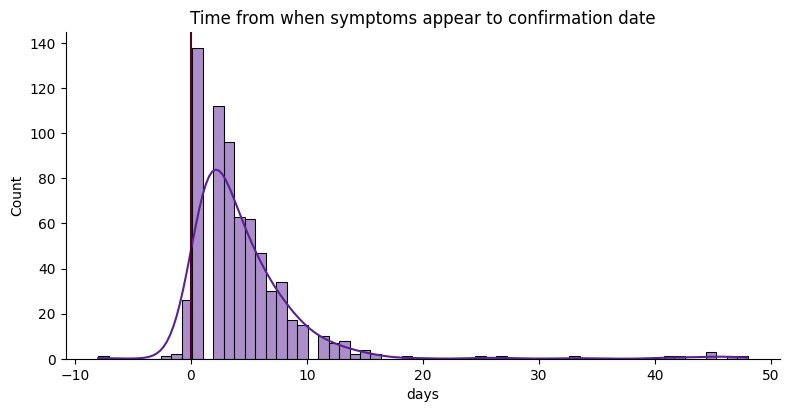

In [135]:
ax = sns.displot(x=symptom_to_confirm_df['days'], height=4, aspect=2, color='#5A2197', kde=True)
plt.pyplot.axvline(x=0, c='#4E0420')

ax.set(title='Time from when symptoms appear to confirmation date');

There are some negative values, which mean that symptoms only appeared after confirmation of COVID (there are 4 people in this dataset who had symptoms appear after confirming COVID). There are people who do not show symptoms, but have COVID. Most of people had to wait up to ten days to get confirmation that they got covid. There are few who had to wait more than 40 days to have COVID confirmed.

In [136]:
symptoms_after = symptom_to_confirm_df['days'] < 0
symptoms_after.sum()

4

In [137]:
mask_maxwait = symptom_to_confirm_df.days.idxmax()
print(f'Longest wait from symptom to COVID is {symptom_to_confirm_df.days.max()} days.')
patient.loc[mask_maxwait]

Longest wait from symptom to COVID is 48 days.


patient_id                      4100000018
sex                                   male
age                                    30s
country                              Korea
province                 Chungcheongnam-do
city                            Cheonan-si
infection_case        contact with patient
infected_by                     4100000049
contact_number                        51.0
symptom_onset_date     2020-02-27 00:00:00
confirmed_date         2020-04-15 00:00:00
released_date          2020-05-04 00:00:00
deceased_date                          NaT
state                             released
Name: 3556, dtype: object

Longest time to confirm COVID was in Chungcheongnam-do province. The patient also had 51 contacts. Perhaps some of them could have been prevented if COVID was diagnosed sooner.

In [138]:
patient_age = patient.dropna(subset=['age'])

# to short values by age:
custom_dict = {
    '0s': 0,
    '10s': 1,
    '20s': 2,
    '30s': 3,
    '40s': 4,
    '50s': 5,
    '60s': 6,
    '70s': 7,
    '80s': 8,
    '90s': 9,
    '100s': 10,
}
key = lambda x: x.map(custom_dict)

patient_age_count = patient_age.age.value_counts().sort_index(key=key)
patient_age_contact = patient_age.groupby('age').contact_number.sum().sort_index(key=key)
patient_age_state = patient_age.groupby('age').state.value_counts()
total_patient_age = len(patient_age)

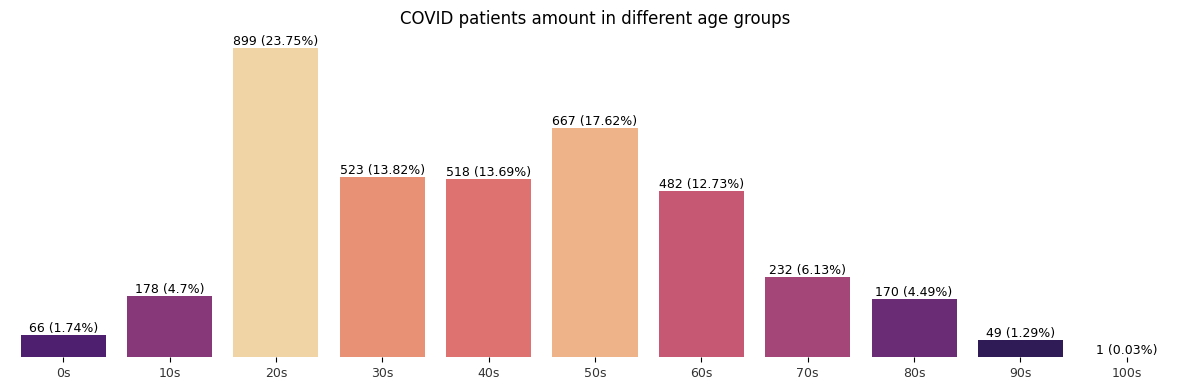

In [139]:
fig = plt.pyplot.figure(figsize=(12, 4))
pal_name = 'magma_r'

ax = bar_graph_f(
    patient_age_count,
    'COVID patients amount in different age groups',
    total_patient_age,
    palette_by_value(patient_age_count, pal_name),
)

fig.tight_layout()
sns.despine(left=True, bottom=True)

Highest amount of COVID patients were in their 20s. It is likely due to them having the most contacts with other people. There was one patient in their 100s. 

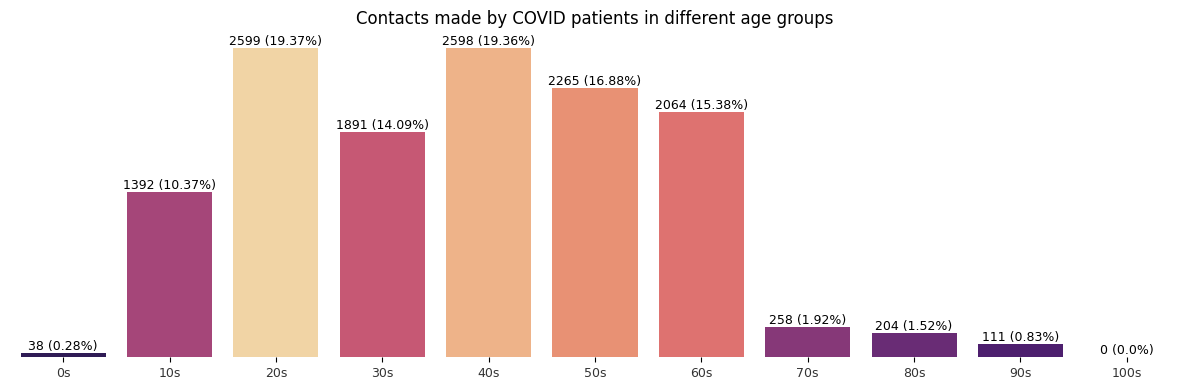

In [140]:
fig = plt.pyplot.figure(figsize=(12, 4))

ax = bar_graph_f(
    patient_age_contact.astype(int),
    'Contacts made by COVID patients in different age groups',
    patient_age_contact.sum(),
    palette_by_value(patient_age_contact, pal_name),
)

fig.tight_layout()
sns.despine(left=True, bottom=True)

Most contacts with others were made by people in their 20s, but in their 40s are very close second. 

In [141]:
patient_age_contact.corr(patient_age_count)

0.907153753466627

There is also strong correlation between contacts made and patient amount. Of course, the more patients you have in that age group, more chances for contact. However, it might indicate that age groups tend to make more contacts with others overall, and therefore there are more patients.

In [142]:
# Filling missing values with 0 for graphs
patient_age_state = patient_age_state.unstack().fillna(0).stack()

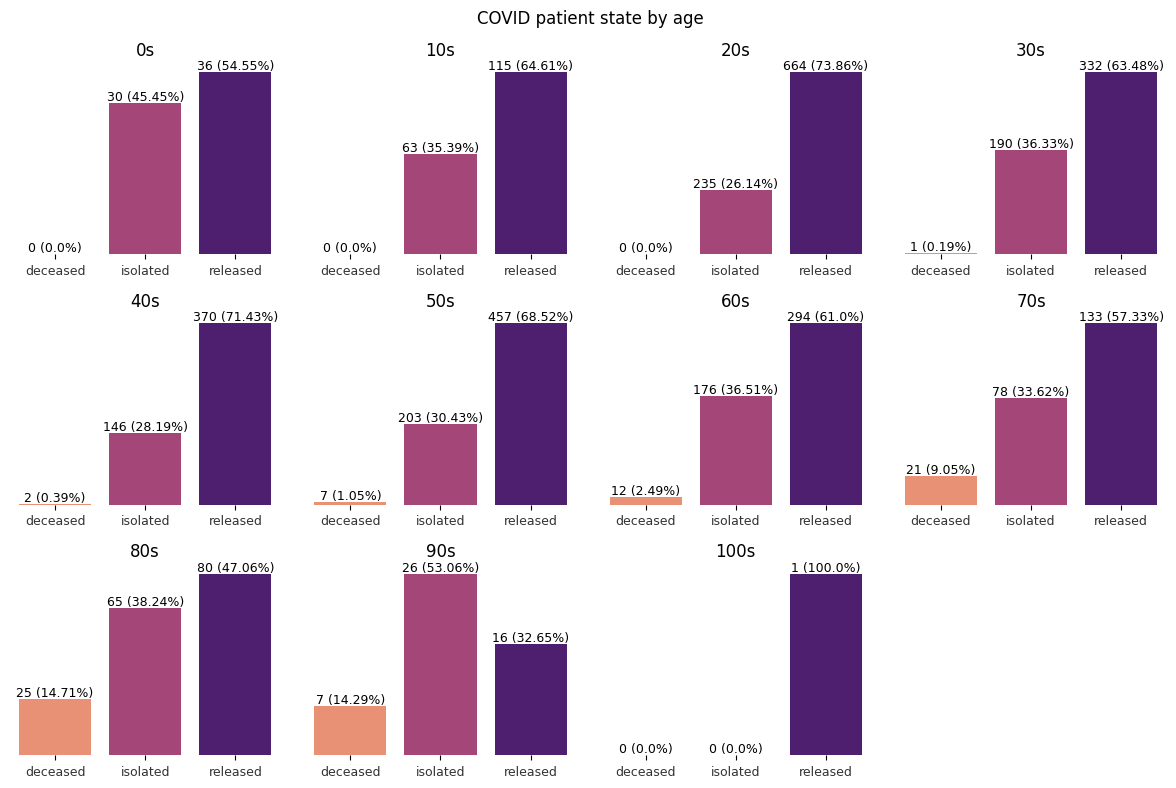

In [143]:
p_age = patient_age_count.index

fig, axs = plt.pyplot.subplots(3, 4, figsize=(12, 8))
fig.suptitle('COVID patient state by age', fontsize=12)
fig.subplots_adjust(top=0.95)

plots_in_subplot(patient_age_state, p_age, 'magma_r')

fig.tight_layout()
sns.despine(left=True, bottom=True)

There are no deceased for people from 0 to 29 years old. There is one person deceased with COVID in their 30s (0.19%), and two in their 40s (0.39%). With age mortality rate increases. With age mortality tend to increase. Highest mortality rate in in 80s group (14.71%) and similar in 90s (14.29%). There is one person in their 100s who survived COVID, but since it is only one patient we cannot evaluate COVID impact on this group.

## Policy 

Data of the government policy for COVID-19 in South Korea

    policy_id: the ID of the policy
    country: the country that implemented the policy
    type: the type of the policy
    gov_policy: the policy of the government
    detail: the detail of the policy
    start_date: the start date of the policy
    end_date: the end date of the policy


#### Policy dataframe null values

In [144]:
policy_missing = policy.isnull().sum()
policy_missing

country        0
type           0
gov_policy     0
detail         2
start_date     0
end_date      37
dtype: int64

In policy data we see that there are two policies with missing detail data. Also there are some policy end dates missing.

In [145]:
policy[policy.detail.isnull()]

,country,type,gov_policy,detail,start_date,end_date
policy_id,,,,,,
51,Korea,Technology,Self-Diagnosis App,NaN,2020-02-12,NaN
52,Korea,Technology,Self-Quarantine Safety Protection App,NaN,2020-03-07,NaN


Details missing are on some COVID related apps. These apps were released by South Korean goverment. The use by locals was optional, but they were required for all travelers to enter the country. (Information about them was taken from here: https://www.statista.com/statistics/1253062/south-korea-covid-19-self-diagnosis-and-self-quarantine-app-usage-by-age/, https://dgovkorea.go.kr/service1/g2c_03/self_safe_app)

Missing detail information will be filled with Mobile App, because Policy names are self-explanatory.

In [146]:
policy["detail"].fillna("Mobile app", inplace=True)

policy.isnull().any()

country       False
type          False
gov_policy    False
detail        False
start_date    False
end_date       True
dtype: bool

Policy end dates might not the there, since the data was collected during year 2020 and the policy has not ended during that time.

### Policy data exploration

In [147]:
policy.head()

,country,type,gov_policy,detail,start_date,end_date
policy_id,,,,,,
1,Korea,Alert,Infectious Disease Alert Level,Level 1 (Blue),2020-01-03,2020-01-19
2,Korea,Alert,Infectious Disease Alert Level,Level 2 (Yellow),2020-01-20,2020-01-27
3,Korea,Alert,Infectious Disease Alert Level,Level 3 (Orange),2020-01-28,2020-02-22
4,Korea,Alert,Infectious Disease Alert Level,Level 4 (Red),2020-02-23,NaN
5,Korea,Immigration,Special Immigration Procedure,from China,2020-02-04,NaN


In [148]:
to_date_list = ['start_date', 'end_date']
for col in to_date_list:
    policy[col] = pd.to_datetime(policy[col], errors='coerce')

policy.dtypes

country               object
type                  object
gov_policy            object
detail                object
start_date    datetime64[ns]
end_date      datetime64[ns]
dtype: object

In [149]:
policy.loc[:, ['start_date', 'end_date']].agg(['min', 'max'])

,start_date,end_date
min,2020-01-03,2020-01-19
max,2020-06-10,2020-06-14


Time frame for this dataset is from 2020-01-03 to 2020-06-14.

In [150]:
first_policy = policy.loc[policy.start_date.idxmin()]
first_policy

country                                Korea
type                                   Alert
gov_policy    Infectious Disease Alert Level
detail                        Level 1 (Blue)
start_date               2020-01-03 00:00:00
end_date                 2020-01-19 00:00:00
Name: 1, dtype: object

In [151]:
last_policy = policy.loc[policy.start_date.idxmax()]
last_policy

country                                                   Korea
type                                                 Technology
gov_policy                       KI-Pass: Korea Internet - Pass
detail        new quick response (QR) code system this week ...
start_date                                  2020-06-10 00:00:00
end_date                                                    NaT
Name: 60, dtype: object

In [152]:
last_policy['detail']

'new quick response (QR) code system this week to log visitors at high-risk entertainment facilities, restaurants and churches in a bid to track coronavirus cases and prevent further spread of the disease'

In [153]:
policy.loc[policy.end_date.idxmax()]

country                                                   Korea
type                                                     Health
gov_policy               Extends Tightened Quarantine Measures 
detail        Gov't Extends Tightened Quarantine Measures in...
start_date                                  2020-05-28 00:00:00
end_date                                    2020-06-14 00:00:00
Name: 61, dtype: object

Last policy to end in this dataframe was about extended tightened quarantine measures

In [154]:
total_policy_amount = policy.shape[0]
total_policy_amount

61

In [155]:
unique_policy_types_nr = len(policy.type.unique())
unique_policy_types_nr

8

In [156]:
policy_types = policy.type.value_counts()

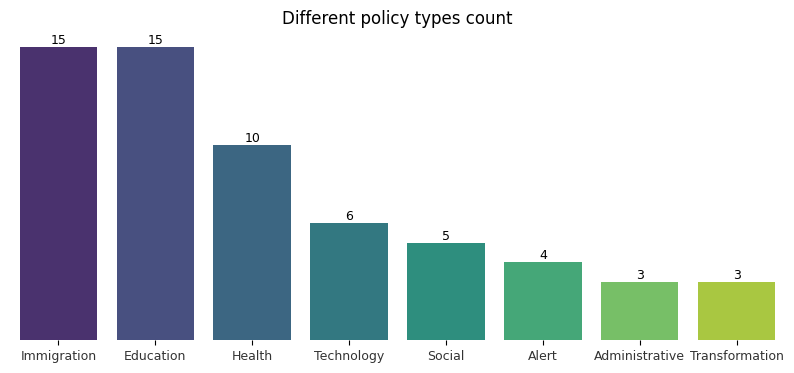

In [157]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax = bar_graph_f_no_percent(policy_types, 'Different policy types count', 'viridis')
sns.despine(left=True, bottom=True)

There most of policies released were related to immigration and education.

In [158]:
policy.loc[policy.type == 'Transformation']

,country,type,gov_policy,detail,start_date,end_date
policy_id,,,,,,
57,Korea,Transformation,Logistics center,On-site inspection of major logistics faciliti...,2020-05-29,2020-06-11
58,Korea,Transformation,Wearing of masks,"Mandatory wearing of passenger mask domestic, ...",2020-05-27,NaT
59,Korea,Transformation,Wearing of masks,Drivers such as buses and taxis can refuse to ...,2020-05-26,NaT


Policy transformation types about refer to wearing of masks and logistics.

In [159]:
policy.gov_policy.value_counts().head()

gov_policy
Special Immigration Procedure                    13
School Opening with Online Class                 10
Emergency Use Authorization of Diagnostic Kit     5
Infectious Disease Alert Level                    4
Social Distancing Campaign                        4
Name: count, dtype: int64

A lot of policies focused on imigration procedure, and online school classes.

Policies were released to reduce count of confirmed covid cases and contacts. Let's check if policy amount negatively correlates with covid amount or contact amount.

In [160]:
# Taking daily contacts made from patient dataset.
# Let's assume that all contacts were made the same day as confirmation.
counts['contact'] = patient.groupby('confirmed_date').contact_number.sum()
counts['contact'].fillna(0, inplace=True)

In [161]:
# How many policies were released each day
counts['daily_released_policy'] = policy.start_date.value_counts()

# not every day policies will be released:
counts['daily_released_policy'].fillna(0, inplace=True)

In [162]:
# How many policies ended each day
counts['daily_ended_policy'] = policy.end_date.value_counts()
counts['daily_ended_policy'].fillna(0, inplace=True)

In [163]:
counts['active_policy'] = counts['daily_released_policy'].cumsum() - counts['daily_ended_policy']

In [164]:
counts.head()

,confirmed_cumsum,confirmed,released,deceased,isolated,contact,daily_released_policy,daily_ended_policy,active_policy
2020-01-20,1.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,2.0
2020-01-23,2.0,1.0,0.0,0.0,2.0,75.0,0.0,0.0,2.0
2020-01-26,3.0,1.0,0.0,0.0,3.0,16.0,0.0,0.0,2.0
2020-01-27,4.0,1.0,0.0,0.0,4.0,95.0,0.0,1.0,1.0
2020-01-30,8.0,4.0,0.0,0.0,8.0,170.0,0.0,0.0,2.0


Let's check if there is any correlation between features. Monotonic associations between variables are going to be assumed. Monotonicity is "less restrictive" than that of a linear relationship. Therefore, Spearman's correlation was used.

In [165]:
# Calculation of Spearman's correlation between numeric features:
correlation = counts.corr(method='spearman')

# Adding background style to separate values:
cm = sns.color_palette('mako_r', as_cmap=True)
correlation.iloc[6:, :6].style.background_gradient(cmap=cm, axis=None)

,confirmed_cumsum,confirmed,released,deceased,isolated,contact
daily_released_policy,-0.159272,0.158622,0.146347,0.168709,-0.159783,0.021162
daily_ended_policy,0.114654,-0.006356,-0.106262,0.021149,0.114132,-0.129944
active_policy,0.995297,0.062650,-0.077270,-0.362624,0.995228,-0.411751


We can see that how much there are active policies and total confirmed sum over the days correlates very nicely. Isolated amount also correlates very well with active policies which there are. It is because policies were released as a response to how many confirmed patients there are. As a result of that, we can also see weak correlation between daily released policies and confirmed covid cases.

We can see that active policy amount negatively correlates with contacts and deceased patients, which indicates that policies did achieve what they were suposed to do.

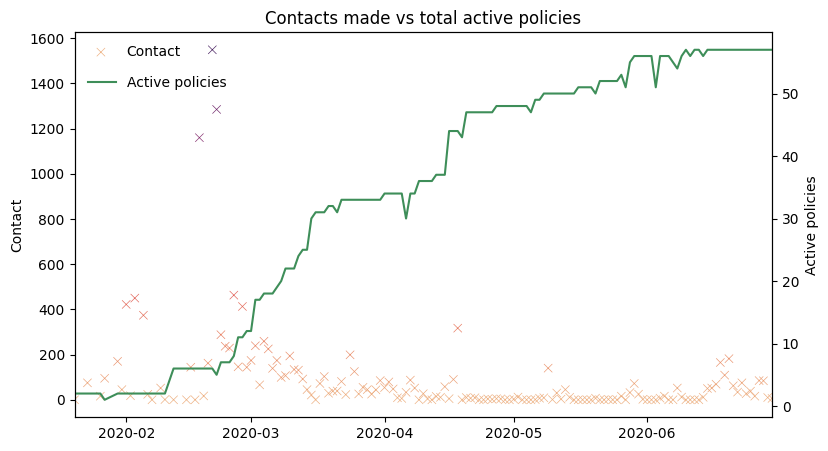

In [166]:
fig = plt.pyplot.figure(figsize=(9, 5))

ax = sns.scatterplot(
    x=counts.index, y=counts['contact'], marker='x', hue=counts['contact'], palette='flare', legend=False
)
ax.set(ylabel='Contact')
ax.set_xlim(counts.index[0], counts.index[-1])
ax.legend(['Contact'], loc='upper left', edgecolor='none')

ax2 = ax.twinx()
ax2 = sns.lineplot(x=counts.index, y=counts['active_policy'], color='#3E8E59')
ax2.set(ylabel='Active policies', title='Contacts made vs total active policies')

ax2.legend(['Active policies'], bbox_to_anchor=[0.236, 0.92], edgecolor='none');

From the graph we can see that there was much higher amount of contacts with COVID carriers in the beginning, when there were less policies. With more policies contact amount decreased.

## Region

Location and statistical data of the regions in South Korea

    code: the code of the region
    province: Special City / Metropolitan City / Province(-do)
    city: City(-si) / Country (-gun) / District (-gu)
    latitude: the latitude of the visit (WGS84)
    longitude: the longitude of the visit (WGS84)
    elementary_school_count: the number of elementary schools
    kindergarten_count: the number of kindergartens
    university_count: the number of universities
    academy_ratio: the ratio of academies
    elderly_population_ratio: the ratio of the elderly population
    elderly_alone_ratio: the ratio of elderly households living alone
    nursing_home_count: the number of nursing homes


In [167]:
region.head()

,code,province,city,latitude,longitude,elementary_school_count,kindergarten_count,university_count,academy_ratio,elderly_population_ratio,elderly_alone_ratio,nursing_home_count
0,10000,Seoul,Seoul,37.566953,126.977977,607,830,48,1.44,15.38,5.8,22739
1,10010,Seoul,Gangnam-gu,37.518421,127.047222,33,38,0,4.18,13.17,4.3,3088
2,10020,Seoul,Gangdong-gu,37.530492,127.123837,27,32,0,1.54,14.55,5.4,1023
3,10030,Seoul,Gangbuk-gu,37.639938,127.025508,14,21,0,0.67,19.49,8.5,628
4,10040,Seoul,Gangseo-gu,37.551166,126.849506,36,56,1,1.17,14.39,5.7,1080


In [168]:
region.dtypes

code                          int64
province                     object
city                         object
latitude                    float64
longitude                   float64
elementary_school_count       int64
kindergarten_count            int64
university_count              int64
academy_ratio               float64
elderly_population_ratio    float64
elderly_alone_ratio         float64
nursing_home_count            int64
dtype: object

In [169]:
# Selecting only information on provinces
mask = region.province == region.city
region_province = region.loc[mask]
region_province.tail()

,code,province,city,latitude,longitude,elementary_school_count,kindergarten_count,university_count,academy_ratio,elderly_population_ratio,elderly_alone_ratio,nursing_home_count
176,51000,Jeollanam-do,Jeollanam-do,34.816095,126.463021,429,542,19,1.45,22.81,13.5,3389
199,60000,Gyeongsangbuk-do,Gyeongsangbuk-do,36.576032,128.505599,471,707,33,1.33,20.85,11.1,4474
223,61000,Gyeongsangnam-do,Gyeongsangnam-do,35.238294,128.692397,501,686,21,1.78,16.51,9.1,5364
242,70000,Jeju-do,Jeju-do,33.488936,126.500423,113,123,4,1.53,15.10,6.4,1245
243,80000,Korea,Korea,37.566953,126.977977,6087,8837,340,1.56,15.67,7.2,94865


Map of south korea is obtained from: https://github.com/southkorea/southkorea-maps

In [170]:
south_korea = gpd.read_file('jsonfiles/skorea-provinces-2018-geo.json')
south_korea.head()

,name,base_year,name_eng,code,geometry
0,서울특별시,2018,Seoul,11,"POLYGON ((127.02215 37.69972, 127.02532 37.699..."
1,부산광역시,2018,Busan,21,"MULTIPOLYGON (((128.82870 35.08997, 128.83203 ..."
2,대구광역시,2018,Daegu,22,"POLYGON ((128.69604 36.01557, 128.69680 36.013..."
3,인천광역시,2018,Incheon,23,"MULTIPOLYGON (((126.48207 37.24419, 126.48263 ..."
4,광주광역시,2018,Gwangju,24,"POLYGON ((126.76338 35.25652, 126.76390 35.254..."


In [171]:
# Checking if are any provinces named differently:

south_korea_provinces = south_korea.name_eng.unique()
region_province_names = region_province.province.unique()

for province in south_korea_provinces:
    if province in region_province_names:
        continue
    print(province)

for province in region_province_names:
    if province in south_korea_provinces:
        continue
    print(province)

Sejongsi
Sejong
Korea


Sejongsi will be renamed to Sejong in the south_korea dataset. Korea comes from region dataset, and it is totals for whole country. It will be removed when dataframes will be merged.

In [172]:
south_korea.replace('Sejongsi', 'Sejong', inplace=True)

In [173]:
region_province_map = south_korea.merge(region_province, left_on=['name_eng'], right_on=['city'], how='inner')

# Adding case_confirmed_province data to the dataset too:
region_province_map = region_province_map.merge(
    case_confirmed_province.reset_index(), left_on=['name_eng'], right_on=['province'], how='inner'
)

# Dropping some unnecessary columns
region_province_map.drop(columns=['name', 'base_year', 'code_x', 'province_x', 'province_y', 'city'], inplace=True)
region_province_map.head(2)

,name_eng,geometry,code_y,latitude,longitude,elementary_school_count,kindergarten_count,university_count,academy_ratio,elderly_population_ratio,elderly_alone_ratio,nursing_home_count,confirmed
0,Seoul,"POLYGON ((127.02215 37.69972, 127.02532 37.699...",10000,37.566953,126.977977,607,830,48,1.44,15.38,5.8,22739,1280
1,Busan,"MULTIPOLYGON (((128.82870 35.08997, 128.83203 ...",11000,35.179884,129.074796,304,408,22,1.40,18.41,8.6,6752,156


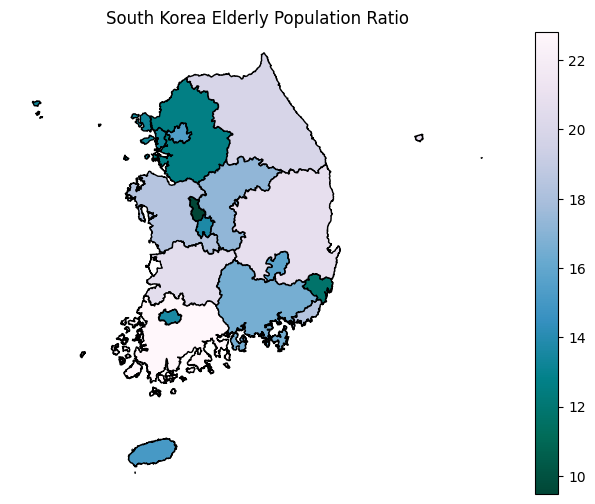

In [174]:
ax1 = region_province_map.plot(
    'elderly_population_ratio', figsize=(8, 6), cmap='PuBuGn_r', edgecolor='black', legend=True
)
ax1.set_title('South Korea Elderly Population Ratio')
ax1.set_axis_off()

In [175]:
options = region_province_map.loc[:, 'elementary_school_count':].columns


@widgets.interact(col=widgets.Dropdown(options=options, description='Data:'))
def seoul_population_map_f(col):
    ax = region_province_map.plot(col, figsize=(8, 6), cmap='PuBuGn_r', edgecolor='black', legend=True)

    if col == 'confirmed':
        ax.set_title(f'South Korea: Confirmed COVID Count')
    else:
        ax.set_title(f'South Korea: {" ".join([x.capitalize() for x in col.split("_")])}')
    ax.set_axis_off()

interactive(children=(Dropdown(description='Data:', options=('elementary_school_count', 'kindergarten_count', …

Let's check if any of the South Korean Statistics correlate with confirmed covid cases:

In [176]:
loc_for_corr = region_province_map.loc[:, 'elementary_school_count':]

# Calculation of Spearman's correlation between numeric features:
correlation = loc_for_corr.corr(method='spearman')

# Background style to visualize values:
cm = sns.color_palette('crest', as_cmap=True)

# Selecting only columns and rows in which I am interested:
correlation.iloc[:-1, -1:].style.background_gradient(cmap=cm, axis=None)

,confirmed
elementary_school_count,0.438725
kindergarten_count,0.512255
university_count,0.468060
academy_ratio,-0.467198
elderly_population_ratio,0.002451
elderly_alone_ratio,-0.079951
nursing_home_count,0.713235


Amount of confirmed covid cases correlate strongly with nursing home count. It seems that COVID spread in nursing homes like wildfire. There is also positive correlation with elementary school, kindergarden and university count. These are all places where COVID could spread in a group of people. There is negative correlation between confirmed amount and acatemy ratio, meaning the more students there were in class the less COVID cases. It might be due to entire schools going on lockdowns if one student got COVID infection, and bigger classes means more chances to go on lockdown, meaning COVID did not spread anymore. It might also be due to COVID spreading first in places where academy ratio is lower.

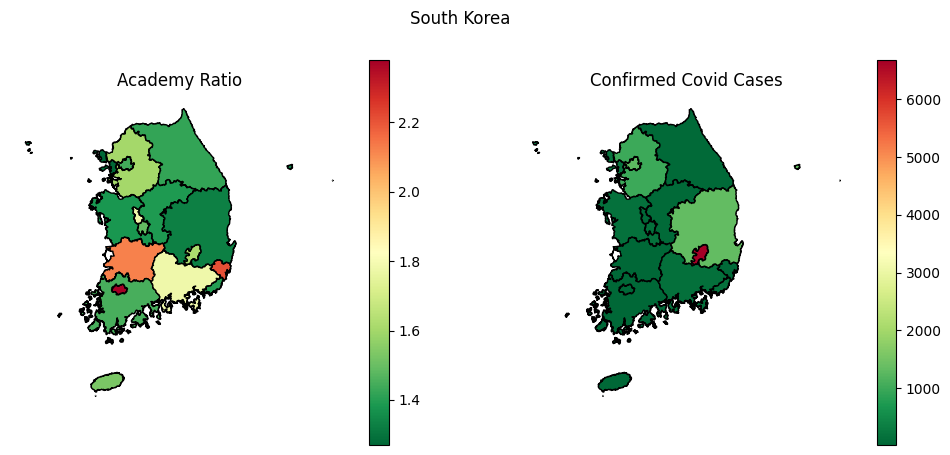

In [177]:
fig, axs = plt.pyplot.subplots(1, 2, sharex=True, figsize=(12, 5))
fig.suptitle('South Korea', fontsize=12)

ax1 = region_province_map.plot('academy_ratio', cmap='RdYlGn_r', edgecolor='k', legend=True, ax=axs[0])
ax1.set_title('Academy Ratio')
ax1.set_axis_off()

ax2 = region_province_map.plot('confirmed', cmap='RdYlGn_r', edgecolor='k', legend=True, ax=axs[1])
ax2.set_title('Confirmed Covid Cases')
ax2.set_axis_off()

We can also see from map that in location with most of COVID cases academy ratio is low, and in few location where academy ratio is high, COVID case count is low.

## Seoul floating

Data of floating population in Seoul, South Korea (from SK Telecom Big Data Hub)

    date: YYYY-MM-DD
    hour: Hour
    birth_year: the birth year of the floating population
    sex: the sex of the floating population
    province: Special City / Metropolitan City / Province(-do)
    city: City(-si) / Country (-gun) / District (-gu)
    fp_num: the number of floating population


In [178]:
seoul_floating.head()

,date,hour,birth_year,sex,province,city,fp_num
0,2020-01-01,0,20,female,Seoul,Dobong-gu,19140
1,2020-01-01,0,20,male,Seoul,Dobong-gu,19950
2,2020-01-01,0,20,female,Seoul,Dongdaemun-gu,25450
3,2020-01-01,0,20,male,Seoul,Dongdaemun-gu,27050
4,2020-01-01,0,20,female,Seoul,Dongjag-gu,28880


In [179]:
seoul_floating['date'] = seoul_floating['date'].astype('datetime64[ns]')
seoul_floating.dtypes

date          datetime64[ns]
hour                   int64
birth_year             int64
sex                   object
province              object
city                  object
fp_num                 int64
dtype: object

Map for Seoul obtained from: https://github.com/southkorea/seoul-maps/blob/master/README.md

In [180]:
seoul_geo = gpd.read_file('jsonfiles/seoul_municipalities_geo.json')
seoul_geo.head()

,SIG_CD,SIG_KOR_NM,SIG_ENG_NM,ESRI_PK,SHAPE_AREA,SHAPE_LEN,geometry
0,11320,도봉구,Dobong-gu,0,0.002110,0.239901,"POLYGON ((127.01985 37.70088, 127.02217 37.699..."
1,11380,은평구,Eunpyeong-gu,1,0.003041,0.327143,"POLYGON ((126.95174 37.65489, 126.95188 37.654..."
2,11230,동대문구,Dongdaemun-gu,2,0.001453,0.182837,"POLYGON ((127.07110 37.60733, 127.07119 37.606..."
3,11590,동작구,Dongjak-gu,3,0.001670,0.237796,"POLYGON ((126.95472 37.51604, 126.95556 37.515..."
4,11545,금천구,Geumcheon-gu,4,0.001325,0.211649,"POLYGON ((126.87994 37.48606, 126.88034 37.485..."


In [181]:
seoul_city_names = seoul_geo.SIG_ENG_NM.unique()
len(seoul_city_names)

25

In [182]:
seoul_floating_city_names = seoul_floating.city.unique()
len(seoul_floating_city_names)

25

One of the cities are named differently in dataset. 

In [183]:
for city in seoul_city_names:
    if city in seoul_floating_city_names:
        continue
    print(city)

for city in seoul_floating_city_names:
    if city in seoul_city_names:
        continue
    print(city)

Dongjak-gu
Dongjag-gu


We see that in one dataset Dongjak-gu is called Dongjag-gu, therefore it is going to be renamed Dongjak-gu.

In [184]:
seoul_floating.replace('Dongjag-gu', 'Dongjak-gu', inplace=True)

In [185]:
seoul_grouped_date_city = seoul_floating.groupby(['date', 'city']).fp_num.sum()
seoul_grouped_date_city = seoul_grouped_date_city.reset_index()
seoul_grouped_date_city.head()

,date,city,fp_num
0,2020-01-01,Dobong-gu,6285430
1,2020-01-01,Dongdaemun-gu,6918490
2,2020-01-01,Dongjak-gu,7669030
3,2020-01-01,Eunpyeong-gu,8780930
4,2020-01-01,Gangbuk-gu,6160610


In [186]:
mask = seoul_grouped_date_city.date == '2020-05-31'
seoul_2020_05_31 = seoul_grouped_date_city[mask].drop(columns='date')
seoul_map_2020_05_31 = seoul_geo.merge(seoul_2020_05_31, left_on=['SIG_ENG_NM'], right_on=['city'], how='inner')
seoul_map_2020_05_31.head()

,SIG_CD,SIG_KOR_NM,SIG_ENG_NM,ESRI_PK,SHAPE_AREA,SHAPE_LEN,geometry,city,fp_num
0,11320,도봉구,Dobong-gu,0,0.002110,0.239901,"POLYGON ((127.01985 37.70088, 127.02217 37.699...",Dobong-gu,6079620
1,11380,은평구,Eunpyeong-gu,1,0.003041,0.327143,"POLYGON ((126.95174 37.65489, 126.95188 37.654...",Eunpyeong-gu,8467980
2,11230,동대문구,Dongdaemun-gu,2,0.001453,0.182837,"POLYGON ((127.07110 37.60733, 127.07119 37.606...",Dongdaemun-gu,6843670
3,11590,동작구,Dongjak-gu,3,0.001670,0.237796,"POLYGON ((126.95472 37.51604, 126.95556 37.515...",Dongjak-gu,7562690
4,11545,금천구,Geumcheon-gu,4,0.001325,0.211649,"POLYGON ((126.87994 37.48606, 126.88034 37.485...",Geumcheon-gu,4830890


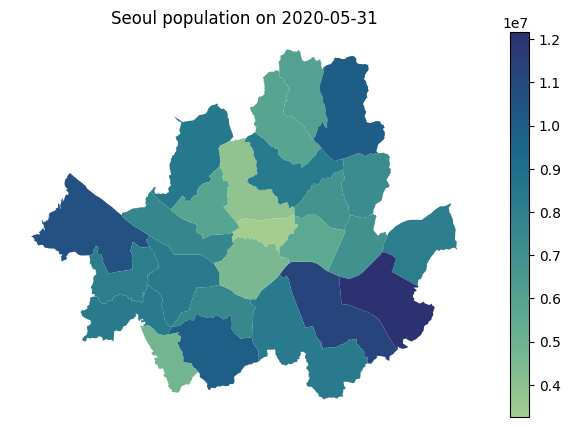

In [187]:
ax1 = seoul_map_2020_05_31.plot('fp_num', figsize=(8, 5), cmap='crest', legend=True)

ax1.set_title('Seoul population on 2020-05-31')
ax1.set_axis_off()

In [188]:
@widgets.interact(date=widgets.Dropdown(options=seoul_grouped_date_city.date.unique(), description='Date:'))
def seoul_population_map_f(date):
    mask = seoul_grouped_date_city.date == date
    seoul_date = seoul_grouped_date_city[mask].drop(columns='date')
    seoul_map_date = seoul_geo.merge(seoul_date, left_on=['SIG_ENG_NM'], right_on=['city'], how='inner')

    lower_lim = seoul_grouped_date_city.fp_num.min()
    upper_lim = seoul_grouped_date_city.fp_num.max()

    ax = seoul_map_date.plot('fp_num', figsize=(8, 5), cmap='crest', vmin=lower_lim, vmax=upper_lim, legend=True)

    ax.set_title(f'Seoul population on {str(date)[:-8]}')
    ax.set_axis_off()

interactive(children=(Dropdown(description='Date:', options=(Timestamp('2020-01-01 00:00:00'), Timestamp('2020…

In [189]:
# Lowest population in Seoul district:
seoul_grouped_date_city.loc[seoul_grouped_date_city.fp_num.idxmin()]

date      2020-01-25 00:00:00
city                  Jung-gu
fp_num                2706020
Name: 613, dtype: object

In [190]:
# Highest population in Seoul district:
seoul_grouped_date_city.loc[seoul_grouped_date_city.fp_num.idxmax()]

date      2020-02-23 00:00:00
city                Songpa-gu
fp_num               23917450
Name: 1346, dtype: object

We can see that population in Seoul from varies a lot day to day. Therefore, average population will be counted for this period.

In [191]:
seoul_city_mean = seoul_grouped_date_city.groupby('city').fp_num.mean()
seoul_city_mean.head()

city
Dobong-gu        5.761227e+06
Dongdaemun-gu    6.960437e+06
Dongjak-gu       7.491807e+06
Eunpyeong-gu     8.058139e+06
Gangbuk-gu       5.721899e+06
Name: fp_num, dtype: float64

In [192]:
seoul_map_average = seoul_geo.merge(seoul_city_mean, left_on=['SIG_ENG_NM'], right_on=['city'], how='inner')
seoul_map_average.head()

,SIG_CD,SIG_KOR_NM,SIG_ENG_NM,ESRI_PK,SHAPE_AREA,SHAPE_LEN,geometry,fp_num
0,11320,도봉구,Dobong-gu,0,0.002110,0.239901,"POLYGON ((127.01985 37.70088, 127.02217 37.699...",5.761227e+06
1,11380,은평구,Eunpyeong-gu,1,0.003041,0.327143,"POLYGON ((126.95174 37.65489, 126.95188 37.654...",8.058139e+06
2,11230,동대문구,Dongdaemun-gu,2,0.001453,0.182837,"POLYGON ((127.07110 37.60733, 127.07119 37.606...",6.960437e+06
3,11590,동작구,Dongjak-gu,3,0.001670,0.237796,"POLYGON ((126.95472 37.51604, 126.95556 37.515...",7.491807e+06
4,11545,금천구,Geumcheon-gu,4,0.001325,0.211649,"POLYGON ((126.87994 37.48606, 126.88034 37.485...",5.433533e+06


In [193]:
# Selecting outbreak data with locations in Seoul:
geo_case_seoul = geo_case[geo_case.province == 'Seoul']
geo_case_outliers_seoul = geo_case_outliers[geo_case_outliers.province == 'Seoul']

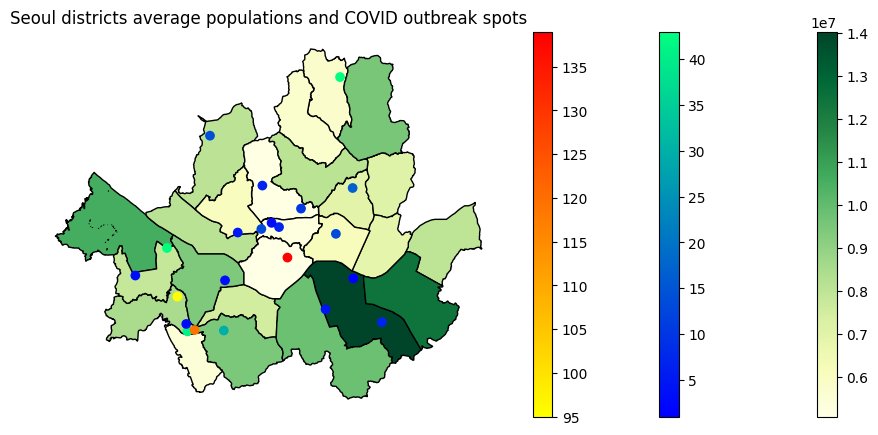

In [194]:
ax1 = seoul_map_average.plot('fp_num', figsize=(12, 5), cmap='YlGn', edgecolor='black', legend=True)

ax2 = geo_case_seoul.plot(
    'confirmed',
    ax=ax1,
    cmap='winter',
    legend=True,
)
ax3 = geo_case_outliers_seoul.plot('confirmed', ax=ax1, cmap='autumn_r', legend=True)

ax1.set_title('Seoul districts average populations and COVID outbreak spots')
ax1.set_axis_off()

We can see that highest outbreak happened in middle of Seoul. Overall, there doesn't seem that there is much relation between amount of COVID outbreak spots and higher population. 

Not all confirmed cases had location data. Let's try to use use patient dataset and calculate COVID patient density for population.

In [195]:
mask = patient.province == 'Seoul'
seoul_patients = patient.loc[mask].groupby('city').city.value_counts()
seoul_patients = seoul_patients.reset_index()

seoul_map_patient = seoul_geo.merge(seoul_patients, left_on=['SIG_ENG_NM'], right_on=['city'], how='inner')
seoul_map_patient['patient_density'] = seoul_map_patient.loc[:, 'count'] / seoul_map_average.fp_num

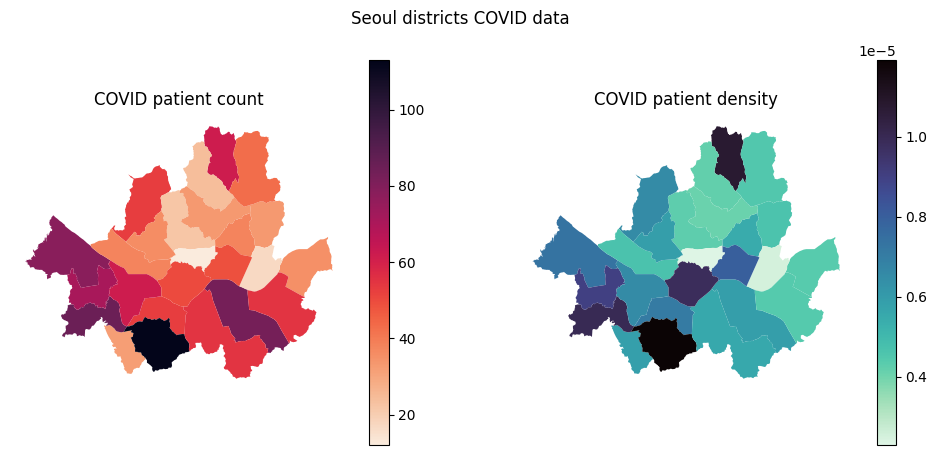

In [196]:
fig, axs = plt.pyplot.subplots(1, 2, sharex=True, figsize=(12, 5))
fig.suptitle('Seoul districts COVID data', fontsize=12)

ax1 = seoul_map_patient.plot('count', cmap='rocket_r', legend=True, ax=axs[0])
ax1.set_title('COVID patient count')
ax1.set_axis_off()

ax2 = seoul_map_patient.plot('patient_density', cmap='mako_r', legend=True, ax=axs[1])
ax2.set_title('COVID patient density')
ax2.set_axis_off()

There seems to be few districts with high covid density, most of surrounding districts have lower amounts of covid patients. Overall, it does not seem like if there are more people in the district that there is higher percentage of infected with COVID. However, in places with COVID outbreaks, there is a high amount of covid patients.

In [197]:
seoul_map_patient.loc[:, 'count'].corr(seoul_map_average.fp_num, method='spearman')

0.6490859599239432

In [198]:
seoul_map_patient.patient_density.corr(seoul_map_average.fp_num, method='spearman')

0.14692307692307693

There is correlation between how many patients there are and population. Therefore, more people is in the district, more COVID patients as well. However, correlation between percent of confirmed infected population and population itself is low.

## Time

Time series data of COVID-19 status in South Korea

    date: YYYY-MM-DD
    time: Time (0 = AM 12:00 / 16 = PM 04:00)

            The time for KCDC to open the information has been changed from PM 04:00 to AM 12:00 since March 2nd.

    test: the accumulated number of tests

            A test is a diagnosis of an infection.

    negative: the accumulated number of negative results
    confirmed: the accumulated number of positive results
    released: the accumulated number of releases
    deceased: the accumulated number of deceases


In [199]:
time['date'] = time['date'].astype('datetime64[ns]')
time.dtypes

date         datetime64[ns]
time                  int64
test                  int64
negative              int64
confirmed             int64
released              int64
deceased              int64
dtype: object

In [200]:
time.head()

,date,time,test,negative,confirmed,released,deceased
0,2020-01-20,16,1,0,1,0,0
1,2020-01-21,16,1,0,1,0,0
2,2020-01-22,16,4,3,1,0,0
3,2020-01-23,16,22,21,1,0,0
4,2020-01-24,16,27,25,2,0,0


In [201]:
time_start_end = time.date.agg(['min', 'max'])

In [202]:
time.agg(['min', 'max'])

,date,time,test,negative,confirmed,released,deceased
min,2020-01-20,0,1,0,1,0,0
max,2020-06-30,16,1273766,1240157,12800,11537,282


In [203]:
# Taking max values since this dataset is accumulated numbers
negative_perc = count_percentage(time.negative.max(), time.test.max())

print(f'Percent that test is negative:{negative_perc}%.')
print(f'Percent that test is not negative:{round((100-negative_perc), 2)}%.')
print(f'Percent that COVID positive:{count_percentage(time.confirmed.max(), time.test.max())}%.')

Percent that test is negative:97.36%.
Percent that test is not negative:2.64%.
Percent that COVID positive:1.0%.


There is 2.64% that the test is going to be positive, while COVID confirmed is only for 1% of done tests. There seems to be a lot of false positives. It also might be that it takes some time to confirm COVID once the test is positive and the amount for that day would increase, but end date for this dataset is 2020-06-30. Let's check % difference evolution during this time period:

In [204]:
time['test_positive'] = round(1 - time.negative / time.test, 4) * 100
time['confirmed_percent'] = round(time.confirmed / time.test, 4) * 100

time['difference'] = time['test_positive'] - time['confirmed_percent']

In [205]:
time['difference'].max()

44.78

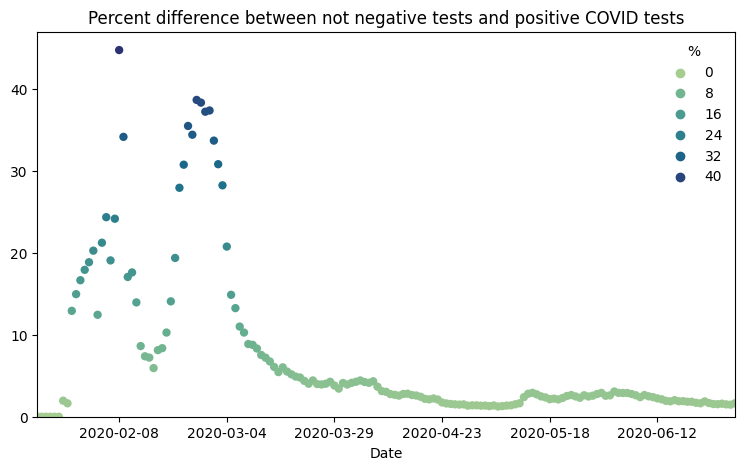

In [206]:
fig = plt.pyplot.figure(figsize=(9, 5))

ax = scatter_graph_f(time, 'date', 'difference', alpha=1, palette='crest', hue='difference', xticker=25)
ax.set(
    title='Percent difference between not negative tests and positive COVID tests',
    ylabel='',
    ylim=0,
    xlim=time_start_end,
)
ax.legend(title='%', edgecolor='none');

At the very start of this dataset, we can see that accuracy of COVID tests was 100%. Later on in February tests reached highest difference between positive COVID and not negative tests (44.78%). There is seems to be a lot of false positive cases or delay for processing positive tests. Difference lowered during beginning of March and continued to stay relatively low around 1.5-2%. 

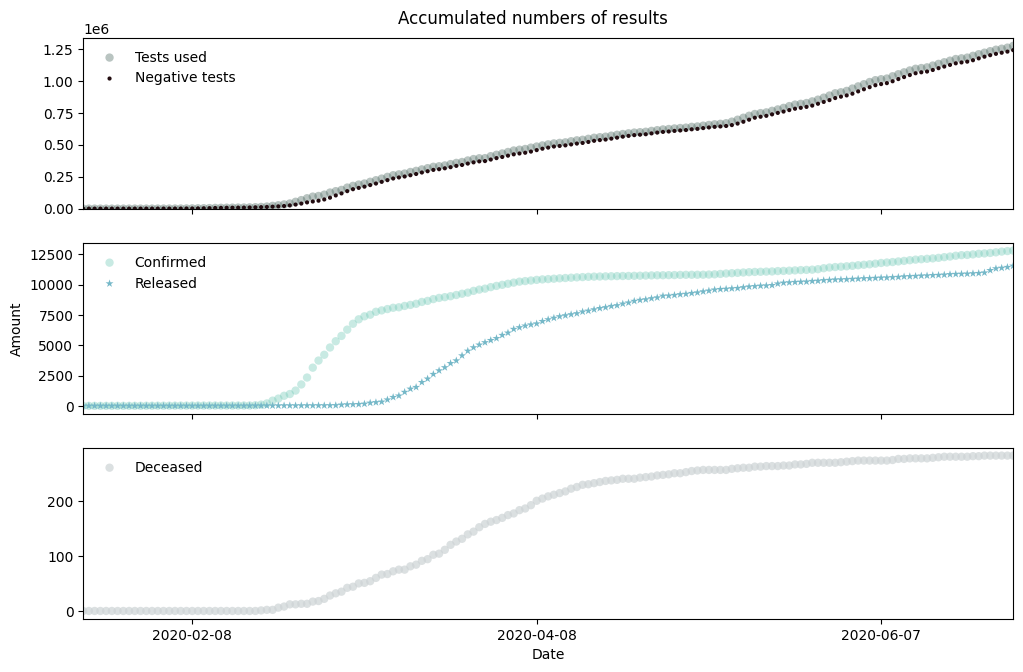

In [207]:
fig, axs = plt.pyplot.subplots(3, sharex=True, figsize=(12, 7))
fig.suptitle('Accumulated numbers of results', fontsize=12)
fig.subplots_adjust(top=0.94)

ax1 = scatter_graph_f(time, 'date', 'test', color='#506C64', ax=axs[0])
ax1 = scatter_graph_f(time, 'date', 'negative', marker='.', color='#220C10', alpha=1, ax=axs[0])
ax1.set(ylabel='', ylim=0, xlim=time_start_end)
ax1.legend(['Tests used', 'Negative tests'], edgecolor='none')

ax2 = scatter_graph_f(time, 'date', 'confirmed', color='#77CBB9', ax=axs[1])
ax2 = scatter_graph_f(time, 'date', 'released', marker='*', color='#75B8C8', alpha=1, ax=axs[1])
ax2.set(ylabel='Amount')
ax2.legend(['Confirmed', 'Released'], edgecolor='none')

ax3 = scatter_graph_f(time, 'date', 'deceased', alpha=0.7, color='#CDD3D5', ax=axs[2])
ax3.set(ylabel='')
ax3.legend(['Deceased'], edgecolor='none');

We can see that almost all COVID tests made during this period were negative. We can see wave of released patients after wave of confirmed tests. Deceased count start to rise faster since end of February and slows down during middle of April. 

## Search trend

Trend data of the keywords searched in NAVER which is one of the largest portal in South Korea

    date: YYYY-MM-DD
    cold: the search volume of 'cold' in Korean language

            The unit means relative value by setting the highest search volume in the period to 100.

    flu: the search volume of 'flu' in Korean language

            Same as above.

    pneumonia: the search volume of 'pneumonia' in Korean language

            Same as above.

    coronavirus: the search volume of 'coronavirus' in Korean language

            Same as above.


In [208]:
search_trend.head()

,date,cold,flu,pneumonia,coronavirus
0,2016-01-01,0.11663,0.05590,0.15726,0.00736
1,2016-01-02,0.13372,0.17135,0.20826,0.00890
2,2016-01-03,0.14917,0.22317,0.19326,0.00845
3,2016-01-04,0.17463,0.18626,0.29008,0.01145
4,2016-01-05,0.17226,0.15072,0.24562,0.01381


In [209]:
search_trend['date'] = search_trend['date'].astype('datetime64[ns]')
search_trend.dtypes

date           datetime64[ns]
cold                  float64
flu                   float64
pneumonia             float64
coronavirus           float64
dtype: object

In [210]:
search_trend_start_end = search_trend.date.agg(['min', 'max'])
search_trend_start_end

min   2016-01-01
max   2020-06-29
Name: date, dtype: datetime64[ns]

In [211]:
search_trend.iloc[:, 1:].describe()

,cold,flu,pneumonia,coronavirus
count,1642.000000,1642.000000,1642.000000,1642.000000
mean,0.190506,0.244946,0.221430,1.862522
std,0.459556,0.762229,0.463014,9.042341
min,0.051630,0.009810,0.068810,0.001540
25%,0.106630,0.042105,0.128630,0.006270
50%,0.133170,0.097855,0.164445,0.008900
75%,0.165900,0.250035,0.209765,0.013158
max,15.720710,27.327270,11.393200,100.000000


Corona virus at some point has the highest search volume. The unit means relative value by setting the highest search volume in the period to 100. No other search trend was even close to these corona virus amount.

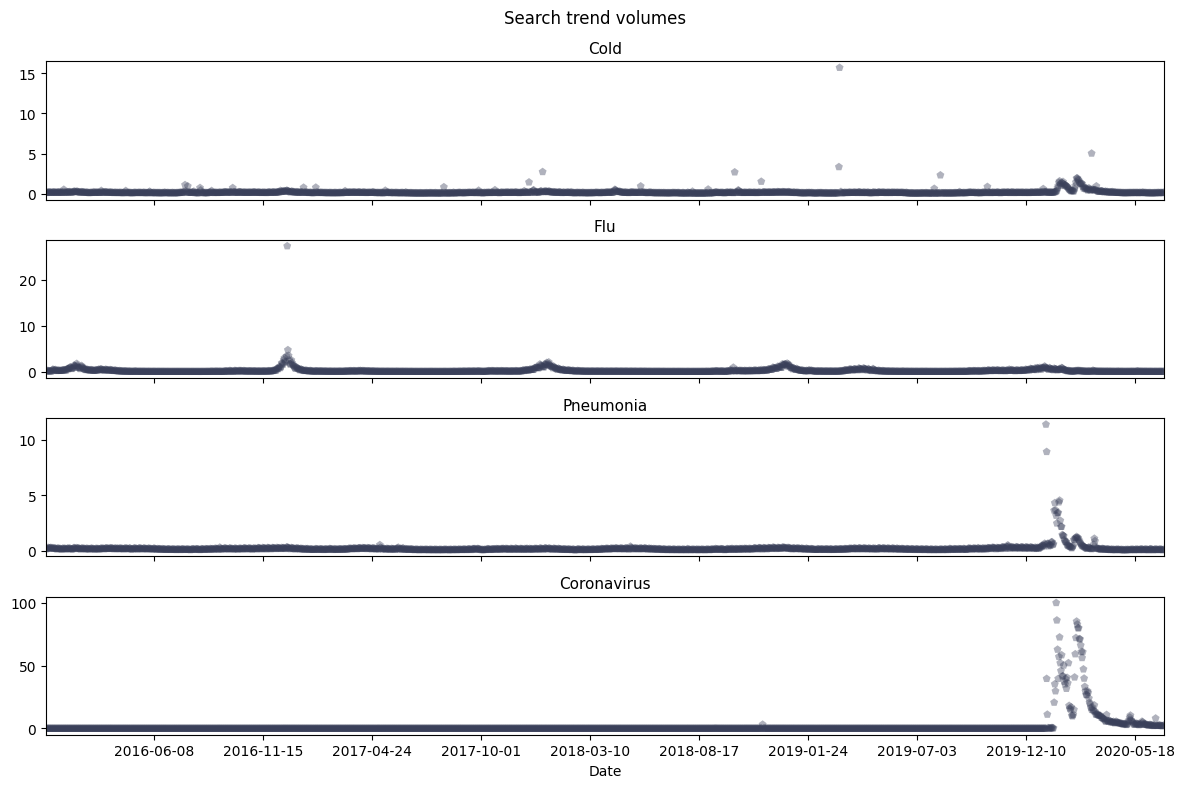

In [212]:
fig, axs = plt.pyplot.subplots(4, sharex=True, figsize=(12, 8))
fig.suptitle('Search trend volumes', fontsize=12)

i = 0
for col in search_trend.iloc[:, 1:].columns:
    ax = scatter_graph_f(data=search_trend, x='date', y=col, color='#3A405A', marker='p', ax=axs[i])
    ax.set(title=col.capitalize(), ylabel='')
    ax.title.set_size(11)
    i += 1

ax.set(xlim=search_trend_start_end)
ax.xaxis.set_major_locator(plt.ticker.MultipleLocator(160))
fig.tight_layout();

Search volume for Cold remains relatively low throughout the year, with some days having spikes. Flu has some seasonal spikes in winter. Search volumes for Pneumonia stayed relatively low, until spike in the end of 2019 and beginning of 2020. Highest search volume was reached by coronavirus, which untill end of 2019, was barely searched for at all. This spike coincides with search spike for pneumonia, seasonal search for flu increase, and increased search for cold. 

In [213]:
correlation = search_trend.iloc[:, 1:].corr(method='spearman')

# Background style to visualize values:
cm = sns.color_palette('mako_r', as_cmap=True)
correlation.style.background_gradient(cmap=cm, axis=None)

,cold,flu,pneumonia,coronavirus
cold,1.000000,0.625171,0.666726,0.522496
flu,0.625171,1.000000,0.662718,0.518082
pneumonia,0.666726,0.662718,1.000000,0.470335
coronavirus,0.522496,0.518082,0.470335,1.000000


We can see that each of the search trends correlate well with each other. Let's check how well it correlates with amount of COVID infected people. Let's use time dataset for this.

In [214]:
# Inner join so take only values which are aviable on both dataset
time_search_trend = time.merge(search_trend, left_on=['date'], right_on=['date'], how='inner')
time_search_trend.drop(columns=['time', 'test_positive', 'confirmed_percent', 'difference'], inplace=True)
# making columns from time dataset no longer accumulated
cum_columns = ['test', 'negative', 'confirmed', 'released', 'deceased']
time_search_trend[cum_columns] -= time_search_trend[cum_columns].shift(1).fillna(0)
time_search_trend.head()

,date,test,negative,confirmed,released,deceased,cold,flu,pneumonia,coronavirus
0,2020-01-20,1.0,0.0,1.0,0.0,0.0,0.19217,0.70343,3.63716,20.69610
1,2020-01-21,0.0,0.0,0.0,0.0,0.0,0.22462,0.59789,4.31987,35.33284
2,2020-01-22,3.0,3.0,0.0,0.0,0.0,0.23808,0.56661,3.66416,29.74474
3,2020-01-23,18.0,18.0,0.0,0.0,0.0,0.30308,0.55625,3.18035,100.00000
4,2020-01-24,5.0,4.0,1.0,0.0,0.0,0.34689,0.40226,2.48156,86.11541


In [215]:
# Calculation of Spearman's correlation between numeric features:
correlation = time_search_trend.iloc[:, 1:].corr(method='spearman')

# Background style to visualize values:
cm = sns.color_palette('mako', as_cmap=True)

# Selecting only columns and rows in which I am interested:
correlation.iloc[5:, :5].style.background_gradient(cmap=cm, axis=None)

,test,negative,confirmed,released,deceased
cold,-0.365222,-0.414816,0.132081,-0.292926,0.146716
flu,-0.391158,-0.448416,-0.062554,-0.435795,-0.003468
pneumonia,-0.313270,-0.361849,0.031962,-0.482186,-0.015239
coronavirus,-0.402442,-0.476894,0.054512,-0.375434,0.105491


There is negative correlation between search trends with the amount of tests done, negative outcomes and released patients. There is weak correlation between cold with confirmed and deceased COVID patients and between coronavirus with deceased.  

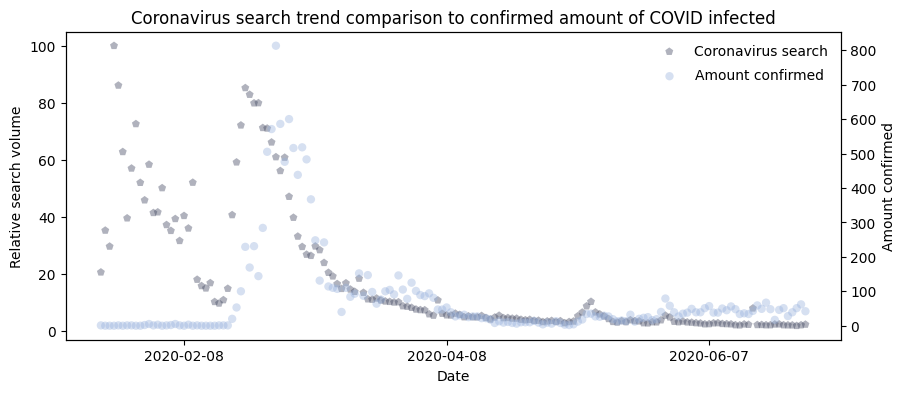

In [216]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax1 = scatter_graph_f(time_search_trend, 'date', 'coronavirus', color='#3A405A', marker='p')
ax1.set(
    title='Coronavirus search trend comparison to confirmed amount of COVID infected', ylabel='Relative search volume'
)
ax1.legend(['Coronavirus search'], loc='upper right', edgecolor='none')

ax2 = ax1.twinx()
ax2 = scatter_graph_f(time_search_trend, 'date', 'confirmed', color='#99B2DD', legend=True)
ax2.set(ylabel='Amount confirmed')
ax2.legend(['Amount confirmed'], bbox_to_anchor=[0.994, 0.92], edgecolor='none');

There was very low correlation between corronavirus search and confirmed amount. However, second wave of coronavirus search looks like it is moved in time few days before the rise of amount confirmed.

## Time gender

Time series data of COVID-19 status in terms of the gender in South Korea

    date: YYYY-MM-DD

            The status in terms of the gender has been presented since March 2nd.

    time: Time
    sex: the gender of patients
    confirmed: the accumulated number of the confirmed
    deceased: the accumulated number of the deceased


In [217]:
time_gender.head()

,date,time,sex,confirmed,deceased
0,2020-03-02,0,male,1591,13
1,2020-03-02,0,female,2621,9
2,2020-03-03,0,male,1810,16
3,2020-03-03,0,female,3002,12
4,2020-03-04,0,male,1996,20


In [218]:
time_gender['date'] = time_gender['date'].astype('datetime64[ns]')
time_gender.dtypes

date         datetime64[ns]
time                  int64
sex                  object
confirmed             int64
deceased              int64
dtype: object

In [219]:
time_gender_start_end = time_gender.date.agg(['min', 'max'])
time_gender_start_end

min   2020-03-02
max   2020-06-30
Name: date, dtype: datetime64[ns]

In [220]:
time_gender['deceased_percent'] = time_gender['deceased'] / time_gender['confirmed'] * 100

In [221]:
time_gender.iloc[-2:]

,date,time,sex,confirmed,deceased,deceased_percent
240,2020-06-30,0,male,5495,151,2.747953
241,2020-06-30,0,female,7305,131,1.793292


There are more females in the dataset, although there are more dead males (confirmed death rate: 1.79% vs 2.75%). In patient dataset we also saw that COVID is slightly more deadly to males than to females. It should be investigated, if this result is due to statistical fluctuations or COVID really is more deadly to males.

In [222]:
# Max number will be total amount of males/females
time_gender_grouped = time_gender.iloc[:, 2:].groupby('sex').max()
time_gender_grouped.iloc[:, :2].sum()

confirmed    12800
deceased       282
dtype: int64

Total numbers are same as in previous dataset.

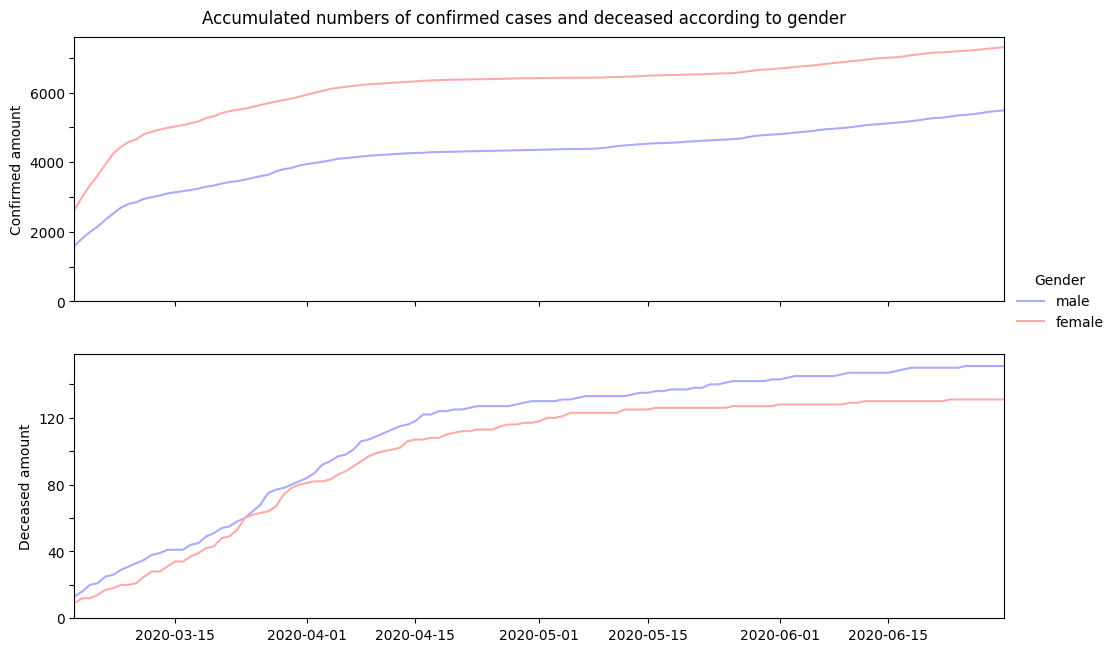

In [223]:
fig, axs = plt.pyplot.subplots(2, sharex=True, figsize=(12, 7))
fig.suptitle('Accumulated numbers of confirmed cases and deceased according to gender', fontsize=12)
fig.subplots_adjust(top=0.94)

ax = sns.lineplot(data=time_gender, x='date', y='confirmed', hue='sex', palette='bwr', ax=axs[0])
ax.set(ylabel='Confirmed amount', ylim=0)
ax.legend(title='Gender', edgecolor='none', loc='center right', bbox_to_anchor=(1.12, 0))

ax2 = sns.lineplot(data=time_gender, x='date', y='deceased', hue='sex', palette='bwr', ax=axs[1], legend=False)
ax2.set(ylabel='Deceased amount', xlabel='', ylim=0, xlim=time_gender_start_end)

for item in [ax, ax2]:
    remove_second_ylabel(item)

We can see that even though there were more females with COVID, there were more overall deaths in males.

Let's check if there is statistical difference between these two datasets using chi-square test. Chosen alpha value is 0.05. Null hypothesis is that there is no difference between men and women. 

In [224]:
crosstab_gender = time_gender.iloc[-2:, 2:5]
crosstab_gender = crosstab_gender.set_index('sex').transpose()
crosstab_gender

sex,male,female
confirmed,5495,7305
deceased,151,131


In [225]:
chi2_contingency(crosstab_gender)

Chi2ContingencyResult(statistic=12.247700846843372, pvalue=0.0004658317806750541, dof=1, expected_freq=array([[5524.29292157, 7275.70707843],
       [ 121.70707843,  160.29292157]]))

The first value (12.248) is the Chi-square value, followed by the p-value (0.00046), then comes the degrees of freedom (1), and lastly the expected frequencies as an array. Since all of the expected frequencies are greater than 5, the test results can be trusted. We can reject the null hypothesis as the p-value is less than alpha - 0.05. Therefore, COVID virus was deadlier to men compared to women, according to this dataset.

## Time age

Time series data of COVID-19 status in terms of the age in South Korea

    date: YYYY-MM-DD

            The status in terms of the age has been presented since March 2nd.

    time: Time
    age: the age of patients
    confirmed: the accumulated number of the confirmed
    deceased: the accumulated number of the deceased


In [226]:
time_age.head()

,date,time,age,confirmed,deceased
0,2020-03-02,0,0s,32,0
1,2020-03-02,0,10s,169,0
2,2020-03-02,0,20s,1235,0
3,2020-03-02,0,30s,506,1
4,2020-03-02,0,40s,633,1


In [227]:
time_age['date'] = time_age['date'].astype('datetime64[ns]')
time_age.dtypes

date         datetime64[ns]
time                  int64
age                  object
confirmed             int64
deceased              int64
dtype: object

In [228]:
time_age['deceased_percent'] = time_age['deceased'] / time_age['confirmed'] * 100

In [229]:
time_age_start_end = time_age.date.agg(['min', 'max'])
time_age_start_end

min   2020-03-02
max   2020-06-30
Name: date, dtype: datetime64[ns]

In [230]:
time_age_grouped = time_age.iloc[-9:, 2:].set_index('age')
time_age_grouped.style.highlight_max(axis=0, props='color:white; background-color:#963646;')

,confirmed,deceased,deceased_percent
age,,,
0s,193,0,0.000000
10s,708,0,0.000000
20s,3362,0,0.000000
30s,1496,2,0.133690
40s,1681,3,0.178465
50s,2286,15,0.656168
60s,1668,41,2.458034
70s,850,82,9.647059
80s,556,139,25.000000


Most confirmed COVID cases were in 20s age group, and least in children. Highest mortality is in 80s age group. It had highest amount of deceased and highest pecent of deceased patients. No infected people aged up to 30 died during this period.

In [231]:
time_age_total = time_age_grouped.iloc[:, :2].sum()
time_age_total

confirmed    12800
deceased       282
dtype: int64

In [232]:
mortality = count_percentage(time_age_total['deceased'], time_age_total['confirmed'])
print(f'Overall age groups percent of deceased is {mortality}%.')

Overall age groups percent of deceased is 2.2%.


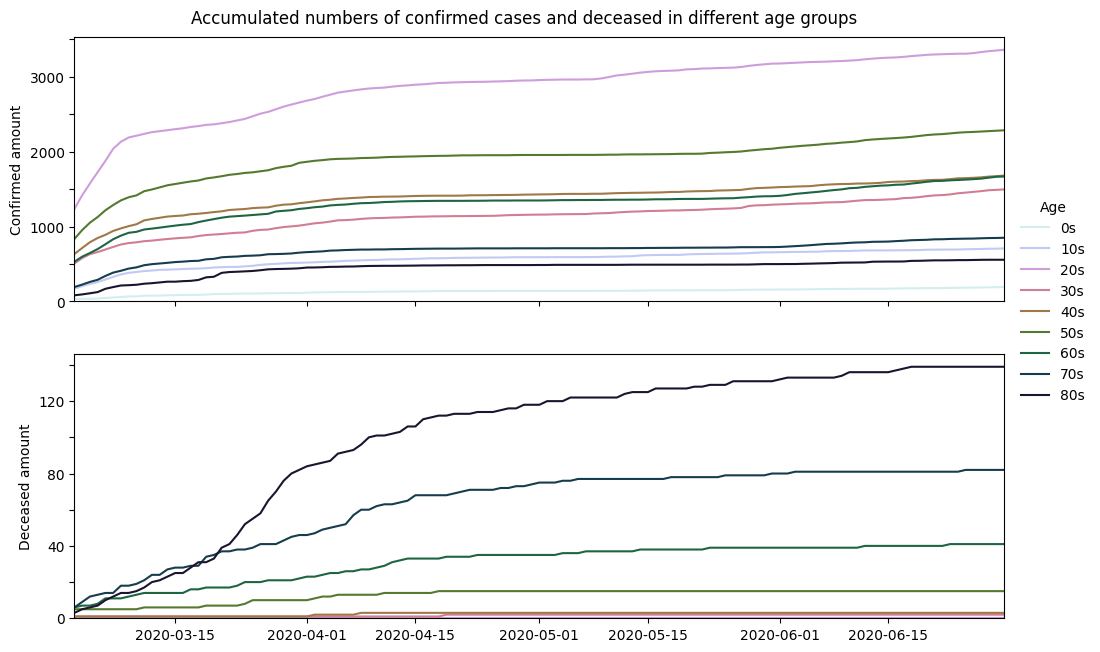

In [233]:
fig, axs = plt.pyplot.subplots(2, sharex=True, figsize=(12, 7))
fig.suptitle('Accumulated numbers of confirmed cases and deceased in different age groups', fontsize=12)
fig.subplots_adjust(top=0.94)

ax = sns.lineplot(data=time_age, x='date', y='confirmed', hue='age', palette='cubehelix_r', ax=axs[0])
ax.set(ylabel='Confirmed amount', ylim=0)
ax.legend(title='Age', edgecolor='none', loc='center right', bbox_to_anchor=(1.1, 0))

ax2 = sns.lineplot(data=time_age, x='date', y='deceased', hue='age', palette='cubehelix_r', ax=axs[1], legend=False)
ax2.set(ylabel='Deceased amount', xlabel='', ylim=0, xlim=time_age_start_end)

for item in [ax, ax2]:
    remove_second_ylabel(item)

From these graphs we can see that the virus is deadlier for older people, as, for example, even if there weren't that many infected in their 80s, amount of deceased in that age group surpassed all other groups. On other hand, there were a lot of confirmed COVID cases for people in their 20s but no recorded deaths during this time period.

Let's check if there is statistical difference between these two datasets using chi-square test. Chosen alpha value is 0.05. Null hypothesis is that there is no difference between age groups. 

In [234]:
crosstab_age = time_age_grouped.drop(columns='deceased_percent').transpose()
crosstab_age

age,0s,10s,20s,30s,40s,50s,60s,70s,80s
confirmed,193,708,3362,1496,1681,2286,1668,850,556
deceased,0,0,0,2,3,15,41,82,139


In [235]:
chi2_contingency(crosstab_age)

Chi2ContingencyResult(statistic=1423.5540392216699, pvalue=4.569623528658452e-302, dof=8, expected_freq=array([[ 188.83962697,  692.73811344, 3289.52759517, 1465.70860725,
        1647.69912857, 2251.39886867, 1672.16022015,  911.90949396,
         680.01834582],
       [   4.16037303,   15.26188656,   72.47240483,   32.29139275,
          36.30087143,   49.60113133,   36.83977985,   20.09050604,
          14.98165418]]))

We see that one value in frequency table is less than 5, therefore the age group for 0s is going to be removed and let's check our results then.

In [236]:
chi2_contingency(crosstab_age.drop(columns='0s'))

Chi2ContingencyResult(statistic=1398.761624823676, pvalue=7.153745275714743e-298, dof=7, expected_freq=array([[ 692.50958181, 3288.44239274, 1465.22507565, 1647.155559  ,
        2250.6561409 , 1671.60858096,  911.60865855,  679.7940104 ],
       [  15.49041819,   73.55760726,   32.77492435,   36.844441  ,
          50.3438591 ,   37.39141904,   20.39134145,   15.2059896 ]]))

The pvalue is very small, which indicates that there definitely is a statistical difference between age groups. That confirms our observation that for elderly this virus is more deadly.

## Time province

Time series data of COVID-19 status in terms of the Province in South Korea

    date: YYYY-MM-DD
    time: Time
    province: the province of South Korea
    confirmed: the accumulated number of the confirmed in the province

            The confirmed status in terms of the provinces has been presented since Feburary 21th.
            The value before Feburary 21th can be different.

    released: the accumulated number of the released in the province

            The confirmed status in terms of the provinces has been presented since March 5th.
            The value before March 5th can be different.

    deceased: the accumulated number of the deceased in the province

            The confirmed status in terms of the provinces has been presented since March 5th.
            The value before March 5th can be different.


In [237]:
time_province.head()

,date,time,province,confirmed,released,deceased
0,2020-01-20,16,Seoul,0,0,0
1,2020-01-20,16,Busan,0,0,0
2,2020-01-20,16,Daegu,0,0,0
3,2020-01-20,16,Incheon,1,0,0
4,2020-01-20,16,Gwangju,0,0,0


In [238]:
time_province['date'] = time_province['date'].astype('datetime64[ns]')
time_province.dtypes

date         datetime64[ns]
time                  int64
province             object
confirmed             int64
released              int64
deceased              int64
dtype: object

In [239]:
time_province_start_end = time_province.date.agg(['min', 'max'])
time_province_start_end

min   2020-01-20
max   2020-06-30
Name: date, dtype: datetime64[ns]

In [240]:
time_province['deceased_percent'] = time_province['deceased'] / time_province['confirmed'] * 100

In [241]:
len(time_province.province.unique())

17

In [242]:
# Since this is accumulated data, last 17 spots will have totals information
time_province_totals = time_province.iloc[-17:, 2:].set_index('province')
time_province_totals.style.highlight_max(axis=0, props='color:white; background-color:#963646;')

,confirmed,released,deceased,deceased_percent
province,,,,
Seoul,1312,985,7,0.533537
Busan,154,142,3,1.948052
Daegu,6906,6700,189,2.736751
Incheon,341,290,1,0.293255
Gwangju,44,32,0,0.000000
Daejeon,117,44,1,0.854701
Ulsan,55,50,1,1.818182
Sejong,50,47,0,0.000000
Gyeonggi-do,1207,931,23,1.905551


Highest amounts of confirmed, released and deceased COVID patients were in Daegu, however Gangwon-do has highest mortality rate. It might be due to that there were not that many COVID infected people there, and if there were more, mortality rate might be lower.

In [243]:
total_amounts_time_province = time_province_totals.iloc[:, :3].sum()
total_amounts_time_province

confirmed    12076
released     10997
deceased       282
dtype: int64

In [244]:
released_percent_time_province = count_percentage(
    total_amounts_time_province['released'], total_amounts_time_province['confirmed']
)
deceased_percent_time_province = count_percentage(
    total_amounts_time_province['deceased'], total_amounts_time_province['confirmed']
)

print(f'Released percent: {released_percent_time_province}%.')
print(f'Deceased percent: {deceased_percent_time_province}%.')

Released percent: 91.06%.
Deceased percent: 2.34%.


Since case amounts differ a lot in provinces, they will not be grouped together. Instead a winget is used.

In [245]:
# Interactive graph


@widgets.interact(key=widgets.Dropdown(options=time_province.province.unique(), description='Province:'))
def province_line_plot_f(key):
    mask = time_province.province == key
    data = time_province[mask]

    fig, axs = plt.pyplot.subplots(2, sharex=True, figsize=(10, 6))
    fig.suptitle(f'{key} COVID statistics')
    fig.subplots_adjust(top=0.94)

    ax = sns.lineplot(data=data, x='date', y='confirmed', color='#172815', ax=axs[0])
    ax = sns.lineplot(data=data, x='date', y='released', color='#709255', linestyle="dashed", ax=axs[0])
    ax.set(ylabel='', ylim=0)
    ax.legend(['confirmed count', 'released count'], title='', edgecolor='none', loc='upper left')

    ax2 = sns.lineplot(data=data, x='date', y='deceased', color='#172815', ax=axs[1])
    ax2.set(ylabel='', xlabel='', ylim=0, xlim=time_province_start_end)
    ax2.legend(['deceased count'], title='', edgecolor='none', loc='upper left')

interactive(children=(Dropdown(description='Province:', options=('Seoul', 'Busan', 'Daegu', 'Incheon', 'Gwangj…

Let's check if there is differences in provinces using chi-square test.

In [246]:
crosstab_provinces = time_province_totals.drop(columns=['released', 'deceased_percent']).transpose()

In [247]:
chi2_contingency(crosstab_provinces)

Chi2ContingencyResult(statistic=58.59605198103777, pvalue=9.006664025047648e-07, dof=16, expected_freq=array([[1.28890144e+03, 1.53417381e+02, 6.93309759e+03, 3.34195825e+02,
        4.29959540e+01, 1.15307331e+02, 5.47221233e+01, 4.88590387e+01,
        1.20193235e+03, 6.64482926e+01, 6.35167503e+01, 1.63189189e+02,
        2.63838809e+01, 2.34523386e+01, 1.41007186e+03, 1.30942224e+02,
        1.85664347e+01],
       [3.00985596e+01, 3.58261855e+00, 1.61902411e+02, 7.80417543e+00,
        1.00404596e+00, 2.69266872e+00, 1.27787668e+00, 1.14096132e+00,
        2.80676485e+01, 1.55170740e+00, 1.48324972e+00, 3.81081081e+00,
        6.16119113e-01, 5.47661434e-01, 3.29281437e+01, 3.05777634e+00,
        4.33565302e-01]]))

We can see that pvalue is 9.0e-07, which would indicate that numbers between provinces differ, however, the test cannot be trusted, because some values are bellow 5 in the frequencies.

## Weather dataset

Data of the weather in the regions of South Korea

    code: the code of the region
    province: Special City / Metropolitan City / Province(-do)
    date: YYYY-MM-DD
    avg_temp: the average temperature
    min_temp: the lowest temperature
    max_temp: the highest temperature
    precipitation: the daily precipitation
    max_wind_speed: the maximum wind speed
    most_wind_direction: the most frequent wind direction
    avg_relative_humidity: the average relative humidity

Source of the weather data: KMA (Korea Meteorological Administration)

#### Weather dataframe null values

In [248]:
weather_missing = weather.isnull().sum()
weather_missing

code                      0
province                  0
date                      0
avg_temp                 15
min_temp                  5
max_temp                  3
precipitation             0
max_wind_speed            9
most_wind_direction      29
avg_relative_humidity    20
dtype: int64

In [249]:
weather_missing_total = weather_missing.sum()
weather_missing_total

81

In [250]:
weather_null_mask = weather.isnull().any(axis=1)
weather_null_values = weather[weather_null_mask]

weather_null_values.tail()

,code,province,date,avg_temp,min_temp,max_temp,precipitation,max_wind_speed,most_wind_direction,avg_relative_humidity
21804,60000,Gyeongsangbuk-do,2019-09-24,NaN,12.1,25.1,0.0,3.2,NaN,NaN
22572,60000,Gyeongsangbuk-do,2019-11-11,13.0,8.5,18.1,0.0,5.9,NaN,64.1
22620,60000,Gyeongsangbuk-do,2019-11-14,4.6,0.9,10.7,0.0,7.7,NaN,28.6
22652,60000,Gyeongsangbuk-do,2019-11-16,10.2,5.1,17.5,0.0,3.8,NaN,79.8
24480,11000,Busan,2020-03-10,9.9,7.3,12.1,0.0,6.5,NaN,83.6


In [251]:
weather_null_values.shape[0]

47

In [252]:
weather.shape[0]

26271

There are 47 rows with null values in the weather dataset. There are total of 26271 rows in weather dataset. In total there are missing 81 cells of values. Therefore, filling in values should not change the result significantly.   

Going to check for visual tendencies, how we can fill in missing values.

In [253]:
weather_province = weather.province.unique()
weather_province

array(['Seoul', 'Busan', 'Daegu', 'Gwangju', 'Incheon', 'Daejeon',
       'Ulsan', 'Gyeonggi-do', 'Gangwon-do', 'Chungcheongbuk-do',
       'Chungcheongnam-do', 'Jeollabuk-do', 'Jeollanam-do',
       'Gyeongsangbuk-do', 'Gyeongsangnam-do', 'Jeju-do',
       'Chunghceongbuk-do'], dtype=object)

We can also notice that some entries for 'Chungcheongbuk-do' are mispelled as 'Chunghceongbuk-do'.

In [254]:
weather.province.replace('Chunghceongbuk-do', 'Chungcheongbuk-do', inplace=True)

weather_province = weather.province.unique()
weather_province

array(['Seoul', 'Busan', 'Daegu', 'Gwangju', 'Incheon', 'Daejeon',
       'Ulsan', 'Gyeonggi-do', 'Gangwon-do', 'Chungcheongbuk-do',
       'Chungcheongnam-do', 'Jeollabuk-do', 'Jeollanam-do',
       'Gyeongsangbuk-do', 'Gyeongsangnam-do', 'Jeju-do'], dtype=object)

In [255]:
# 2016 was a leap year
chungcheongnamdo = weather[weather.province == 'Chungcheongnam-do'].head(366)

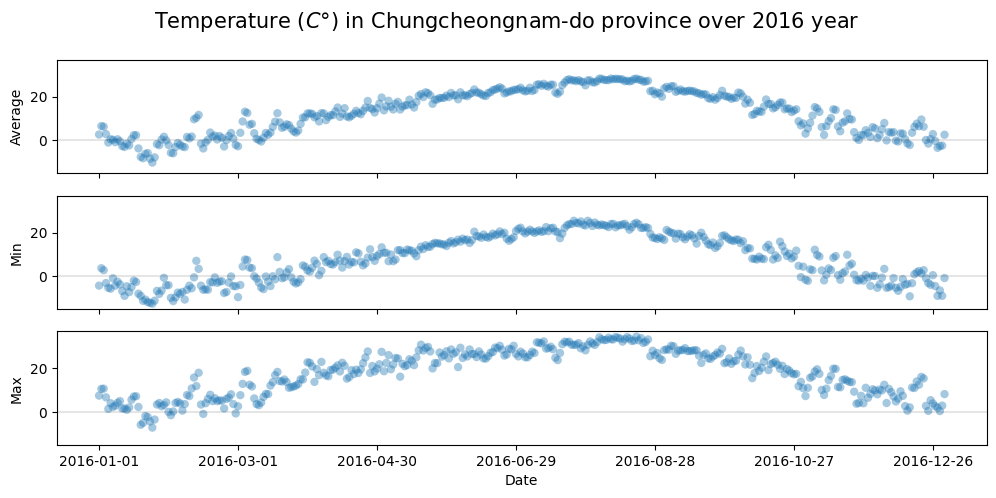

In [256]:
fig, axs = plt.pyplot.subplots(3, sharey=True, sharex=True, figsize=(12, 5))
fig.suptitle('Temperature ($C°$) in Chungcheongnam-do province over 2016 year', fontsize=15)

ax1 = scatter_graph_f(chungcheongnamdo, 'date', 'avg_temp', ax=axs[0])
ax1.set_ylabel('Average')
ax2 = scatter_graph_f(chungcheongnamdo, 'date', 'min_temp', ax=axs[1])
ax2.set_ylabel('Min')
ax3 = scatter_graph_f(chungcheongnamdo, 'date', 'max_temp', ax=axs[2])
ax3.set_ylabel('Max')

for i in range(1, 4):
    eval(f'ax{i}').axhline(y=0, color='black', alpha=0.1)

Average temperature seems to be changing gradualy. Therefore missing values can be filled by using interpolation of nearest values. It will not be exact value, but it will be close approximation to what it should be.

In [257]:
for i in range(len(weather_province)):
    mask = weather.loc[:, 'province'] == weather_province[i]
    weather.loc[mask, 'avg_temp':'max_temp'] = weather.loc[mask, 'avg_temp':'max_temp'].interpolate(method='nearest')

weather.isnull().any()

code                     False
province                 False
date                     False
avg_temp                 False
min_temp                 False
max_temp                 False
precipitation            False
max_wind_speed            True
most_wind_direction       True
avg_relative_humidity     True
dtype: bool

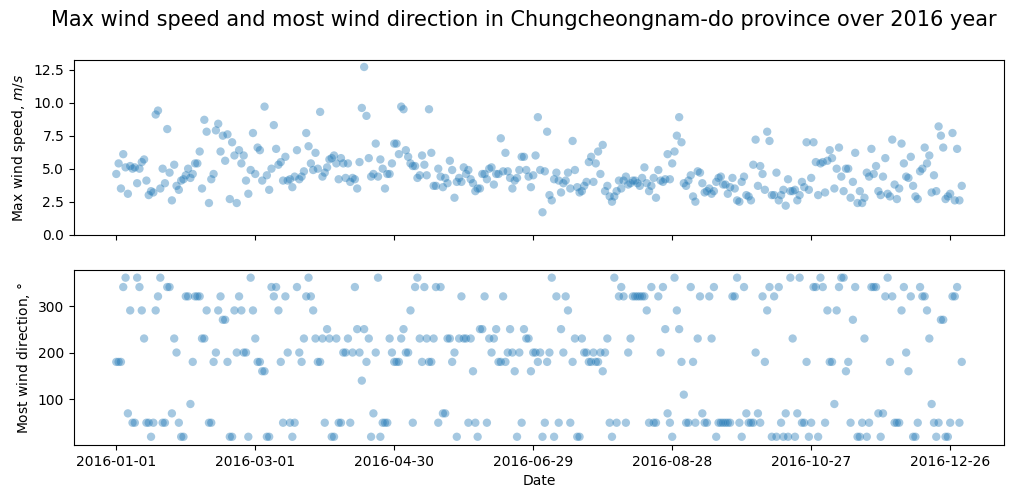

In [258]:
fig, axs = plt.pyplot.subplots(2, sharex=True, figsize=(12, 5))
fig.suptitle('Max wind speed and most wind direction in Chungcheongnam-do province over 2016 year', fontsize=15)

ax1 = scatter_graph_f(chungcheongnamdo, 'date', 'max_wind_speed', ax=axs[0])
ax1.set_ylabel('Max wind speed, $m/s$')
ax1.set(ylim=0)

ax2 = scatter_graph_f(chungcheongnamdo, 'date', 'most_wind_direction', ax=axs[1])
ax2.set_ylabel('Most wind direction, $°$');

Values of max wind speeds and most wind directions seems to be much more varied. South Korea is a relatively small country, therefore we can check if numbers are similar of the provincies/cities, which are close to each other.

In [259]:
weather.loc[:, ['province', 'max_wind_speed']].groupby(['province']).mean()

,max_wind_speed
province,
Busan,6.396468
Chungcheongbuk-do,3.917905
Chungcheongnam-do,4.799329
Daegu,4.988611
Daejeon,3.894945
Gangwon-do,5.038246
Gwangju,4.133557
Gyeonggi-do,4.493605
Gyeongsangbuk-do,6.149513


From average data we can see that average max wind speed is quite varied between locations, even if they are close to each other. For example Incheon and Seoul are not that far away, however average max wind speed in Seoul is lower than Incheon. This might be due that Incheon is much closer to the sea, and Seoul is in between mountains. Due to wind speed variations between the provinces, it seems that the best way to fill in NaN values is using the median of that year. It will reflect characteristics of that year and location.

In [260]:
incheon = weather[weather.province == 'Incheon']
seoul = weather[weather.province == 'Seoul']

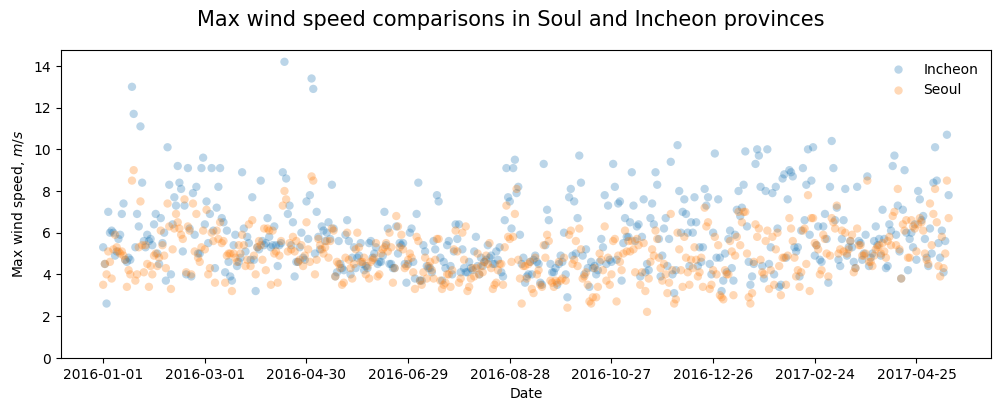

In [261]:
fig = plt.pyplot.figure(figsize=(12, 4))
fig.suptitle('Max wind speed comparisons in Soul and Incheon provinces', fontsize=15)

ax1 = scatter_graph_f(incheon.head(500), 'date', 'max_wind_speed', alpha=0.3)
ax1.set_ylabel('Max wind speed, $m/s$')
ax1.set(ylim=0)
ax2 = scatter_graph_f(seoul.head(500), 'date', 'max_wind_speed', alpha=0.3)
plt.pyplot.legend(labels=['Incheon', 'Seoul'], edgecolor='none');

From the graph we can also see that the max wind speeds are higher in Incheon compared to Seoul, although they do follow same trends. Some days are much more windy compared to the rest, therefore median value was chosen to fill in NaNs.

In [262]:
weather['date'] = pd.to_datetime(weather['date'])
weather.dtypes

code                              int64
province                         object
date                     datetime64[ns]
avg_temp                        float64
min_temp                        float64
max_temp                        float64
precipitation                   float64
max_wind_speed                  float64
most_wind_direction             float64
avg_relative_humidity           float64
dtype: object

In [263]:
# Filling NaN values max_wind_speed of each province for a year with median value
filling = weather.groupby(
    [
        'province',
        weather.date.dt.year,
    ]
)[
    'max_wind_speed'
].transform('median')

weather.max_wind_speed.fillna(filling, inplace=True)
weather.isnull().any()

code                     False
province                 False
date                     False
avg_temp                 False
min_temp                 False
max_temp                 False
precipitation            False
max_wind_speed           False
most_wind_direction       True
avg_relative_humidity     True
dtype: bool

Most wind direction can have values from 0 to 360 degrees (since it covers all directions). Let's check if there is tendencies in these values and if we can fill them somehow.

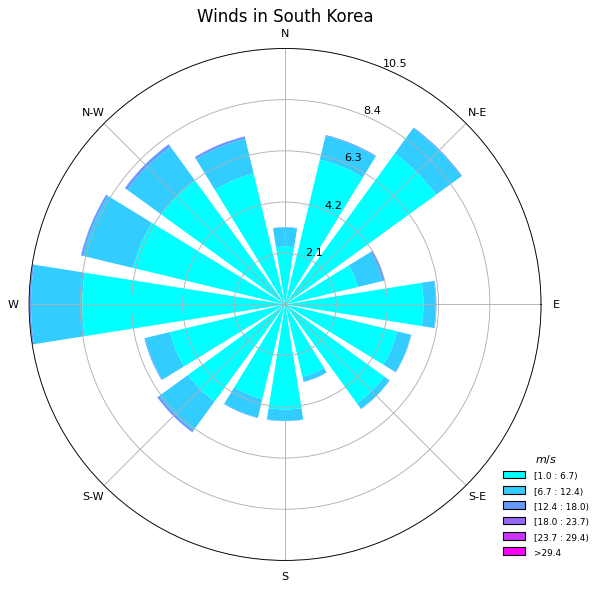

In [264]:
ax = WindroseAxes.from_ax()
ax.bar(
    weather.most_wind_direction, weather.max_wind_speed, normed=True, opening=0.8, edgecolor='none', cmap=plt.cm.cool
)

plt.pyplot.title('Winds in South Korea', fontsize=15)
ax.set_legend(title="$m/s$", bbox_to_anchor=(1.1, 0), loc="lower right", edgecolor='none');

We can see that most of the wind in South Korea blow towards the west.

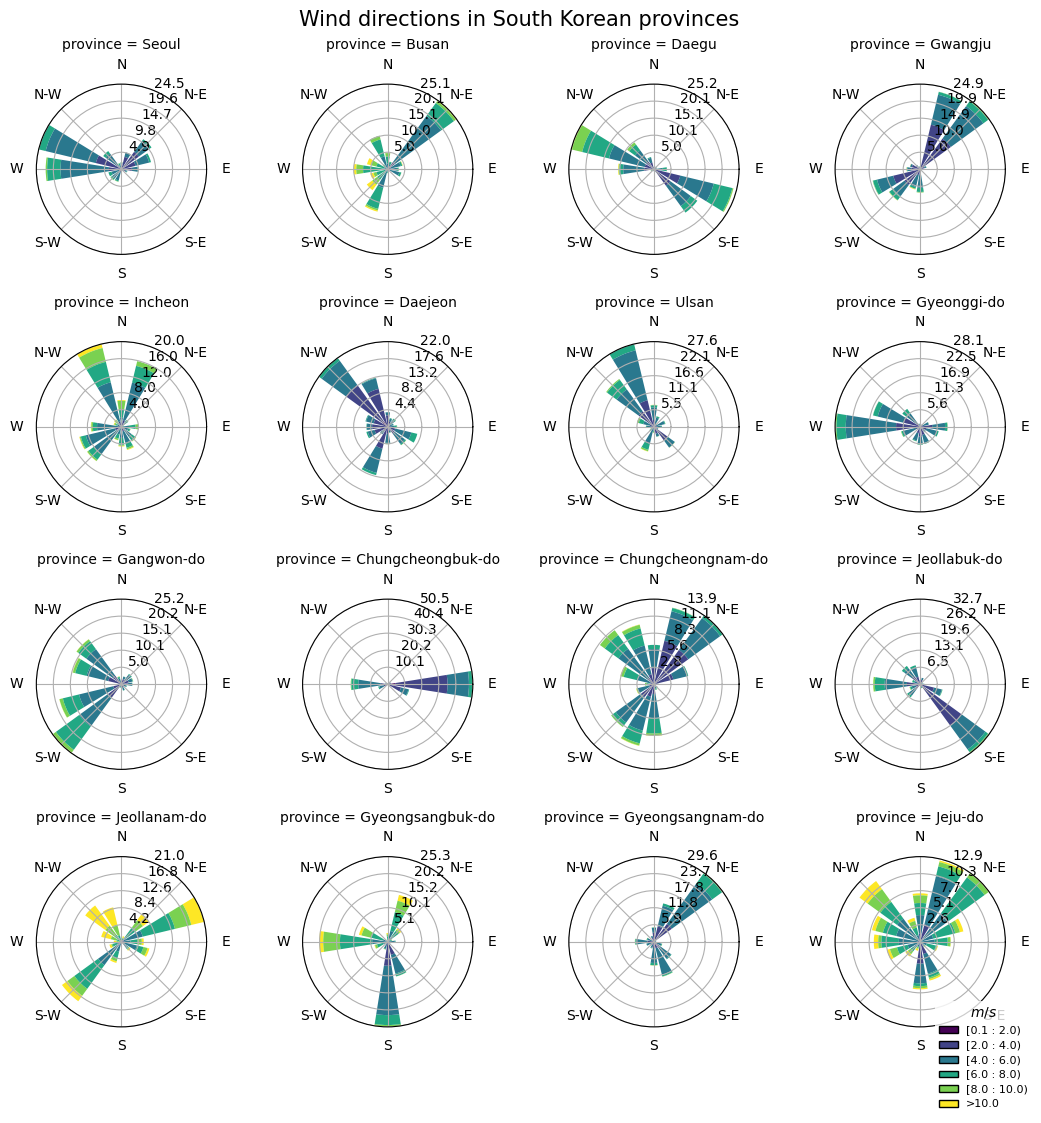

In [265]:
def plot_windrose_subplots(data, *, direction, var, color=None, **kwargs):
    """wrapper function to create subplots per axis"""
    ax = plt.pyplot.gca()
    ax = WindroseAxes.from_ax(ax=ax)
    plot_windrose(direction_or_df=data[direction], var=data[var], ax=ax, **kwargs)


# this creates the raw subplot structure with a subplot per value in province.
g = sns.FacetGrid(
    data=weather,
    col="province",
    col_wrap=4,
    subplot_kws={"projection": "windrose"},
    sharex=False,
    sharey=False,
    despine=False,
    height=2.7,
)

g.fig.suptitle('Wind directions in South Korean provinces', fontsize=15)

g.map_dataframe(
    plot_windrose_subplots,
    direction="most_wind_direction",
    var="max_wind_speed",
    normed=True,
    bins=(0.1, 2, 4, 6, 8, 10),
    calm_limit=0.1,
    kind="bar",
)

g.axes[(len(g.axes) - 1)].set_legend(
    title="$m/s$", bbox_to_anchor=(1.15, -0.5), loc="lower right", edgecolor='none', fontsize=7
);

Looking at the wind directions it seems that the wind is blowing to one direction most of the time across most of provinces of South Korea. For example, in Chungcheongbuk-do the wind is blowing east most of the time. Busan is in Gyeongsangnam-do and their wind directions are similar, mostly to North-east. However, even if Seoul and Incheon are close to each other, their dominant wind directions are very different. Gwangju has mostly north-east winds, but this differs from Jeollanam-do, which has South-West and North-east winds, even if the Gwangju is in Jeollanom-do. These differences might be due to uneven terrain of South Korea.

Even if we were able to use some of the wind direction data for filling NaN values, by using close provinces, there might be other way of doing it, which could fit for all of the provinces.

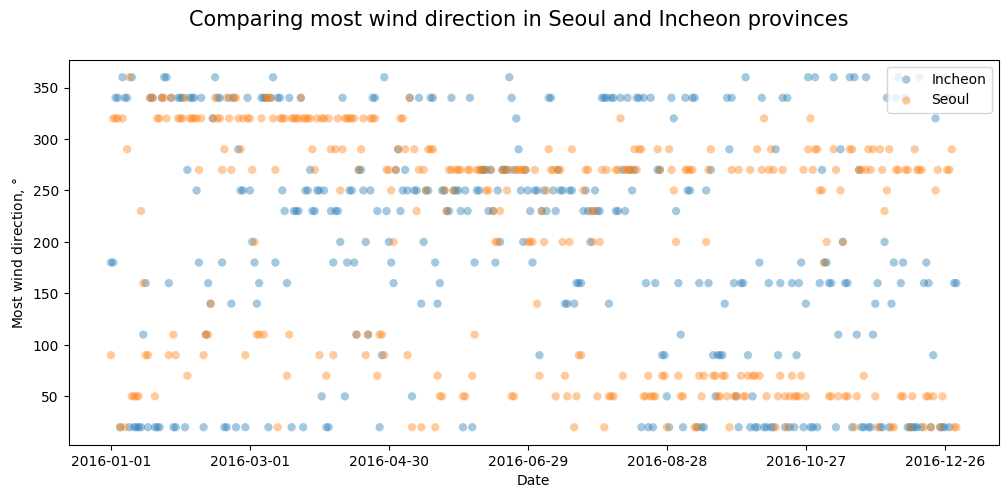

In [266]:
fig = plt.pyplot.figure(figsize=(12, 5))
fig.suptitle('Comparing most wind direction in Seoul and Incheon provinces', fontsize=15)

ax1 = scatter_graph_f(incheon.head(366), 'date', 'most_wind_direction')
ax1.set_ylabel('Most wind direction, $°$')

ax2 = scatter_graph_f(seoul.head(366), 'date', 'most_wind_direction')

plt.pyplot.legend(labels=['Incheon', 'Seoul'], loc='upper right');

There seems to be a tendency for wind to blow in one direction for multiple days in a row.

In [267]:
seoul.most_wind_direction.tail(20)

25951    290.0
25967    290.0
25983    290.0
25999    290.0
26015    270.0
26031    270.0
26047    290.0
26063    290.0
26079    320.0
26095     70.0
26111    290.0
26127    320.0
26143    290.0
26159    270.0
26175     50.0
26191    180.0
26207    230.0
26223    250.0
26239    270.0
26255     50.0
Name: most_wind_direction, dtype: float64

If we look closer at the data, we can see that the wind hasn't changed direction for multiple days in a row, or only changed direction slightly. Also after blowing multiple days in a row it would change direction for a few days, and then blow again towards the previous direction. This means that we can forward fill the missing values with direction of a previous day and it will be a close approximation of what it should be. 

In [268]:
weather['most_wind_direction'] = weather.groupby('province')['most_wind_direction'].ffill().astype(int)

weather.isnull().any()

code                     False
province                 False
date                     False
avg_temp                 False
min_temp                 False
max_temp                 False
precipitation            False
max_wind_speed           False
most_wind_direction      False
avg_relative_humidity     True
dtype: bool

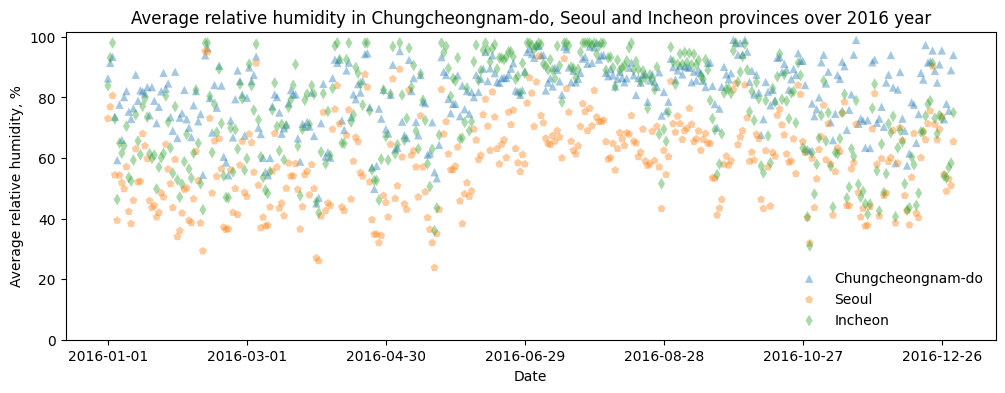

In [269]:
plt.pyplot.figure(figsize=(12, 4))

ax1 = scatter_graph_f(chungcheongnamdo, 'date', 'avg_relative_humidity', marker='^')
ax1.set(title='Average relative humidity in Chungcheongnam-do, Seoul and Incheon provinces over 2016 year')
ax1.set_ylabel('Average relative humidity, %')
ax1.set(ylim=0)

ax2 = scatter_graph_f(seoul.head(366), 'date', 'avg_relative_humidity', marker='p')
ax2 = scatter_graph_f(incheon.head(366), 'date', 'avg_relative_humidity', marker='d')

plt.pyplot.legend(labels=['Chungcheongnam-do', 'Seoul', 'Incheon'], loc='lower right', edgecolor='none');

Average humidity seems to be slightly different for different provinces. Also there is increase in humidity in summer months. Interpolation of nearest values can be used to fill in values. It will not be exact value, but it will be close approximation to what it should be.

In [270]:
for i in range(len(weather_province)):
    mask = weather.loc[:, 'province'] == weather_province[i]
    weather.loc[mask, 'avg_relative_humidity'] = weather.loc[mask, 'avg_relative_humidity'].interpolate(
        method='nearest'
    )

weather.isnull().any()

code                     False
province                 False
date                     False
avg_temp                 False
min_temp                 False
max_temp                 False
precipitation            False
max_wind_speed           False
most_wind_direction      False
avg_relative_humidity    False
dtype: bool

### Weather relation to COVID

Let's check if there is any relation between weather and COVID. For this I will use Patients dataset.

In [271]:
patient.head()

,patient_id,sex,age,country,province,city,infection_case,infected_by,contact_number,symptom_onset_date,confirmed_date,released_date,deceased_date,state
0,1000000001,male,50s,Korea,Seoul,Gangseo-gu,overseas inflow,NaN,75.0,2020-01-22,2020-01-23,2020-02-05,NaT,released
1,1000000002,male,30s,Korea,Seoul,Jungnang-gu,overseas inflow,NaN,31.0,NaT,2020-01-30,2020-03-02,NaT,released
2,1000000003,male,50s,Korea,Seoul,Jongno-gu,contact with patient,2002000001,17.0,NaT,2020-01-30,2020-02-19,NaT,released
3,1000000004,male,20s,Korea,Seoul,Mapo-gu,overseas inflow,NaN,9.0,2020-01-26,2020-01-30,2020-02-15,NaT,released
4,1000000005,female,20s,Korea,Seoul,Seongbuk-gu,contact with patient,1000000002,2.0,NaT,2020-01-31,2020-02-24,NaT,released


In [272]:
patient.groupby(['confirmed_date', 'province']).confirmed_date.count()

confirmed_date  province         
2020-01-20      Incheon              1
2020-01-23      Seoul                1
2020-01-26      Gyeonggi-do          1
2020-01-27      Gyeonggi-do          1
2020-01-30      Jeollabuk-do         1
                                    ..
2020-06-29      Sejong               1
                Seoul                7
2020-06-30      Chungcheongnam-do    1
                Daejeon              4
                Incheon              2
Name: confirmed_date, Length: 904, dtype: int64

In [273]:
patient_grouped = patient.groupby(['confirmed_date', 'province']).agg(
    {'confirmed_date': 'count', 'contact_number': 'sum', 'released_date': 'count', 'deceased_date': 'count'}
)
patient_grouped.rename(
    columns={"confirmed_date": "confirmed", 'released_date': 'released', 'deceased_date': 'deceased'}, inplace=True
)
patient_grouped.reset_index(inplace=True)
patient_grouped.rename(columns={"confirmed_date": "date"}, inplace=True)
patient_grouped.head()

,date,province,confirmed,contact_number,released,deceased
0,2020-01-20,Incheon,1,0.0,1,0
1,2020-01-23,Seoul,1,75.0,1,0
2,2020-01-26,Gyeonggi-do,1,16.0,1,0
3,2020-01-27,Gyeonggi-do,1,95.0,1,0
4,2020-01-30,Jeollabuk-do,1,113.0,1,0


In [274]:
# Inner join so take only values which are aviable on both dataset
patient_weather = patient_grouped.merge(
    weather, left_on=['date', 'province'], right_on=['date', 'province'], how='inner'
)
# Dropping code column as it isn't needed.
# Also dropping min and max temp columns as they are related to average temp
patient_weather.drop(columns=['code', 'min_temp', 'max_temp'], inplace=True)
patient_weather.head()

,date,province,confirmed,contact_number,released,deceased,avg_temp,precipitation,max_wind_speed,most_wind_direction,avg_relative_humidity
0,2020-01-20,Incheon,1,0.0,1,0,1.2,0.0,8.6,320,56.0
1,2020-01-23,Seoul,1,75.0,1,0,4.6,0.0,4.7,290,49.3
2,2020-01-26,Gyeonggi-do,1,16.0,1,0,5.3,0.0,5.2,90,74.3
3,2020-01-27,Gyeonggi-do,1,95.0,1,0,5.9,0.0,5.0,70,71.5
4,2020-01-30,Jeollabuk-do,1,113.0,1,0,5.1,0.0,4.3,270,76.6


Let's check if anything correlates in the dataset

In [275]:
# Calculation of Spearman's correlation between numeric features:
correlation = patient_weather.iloc[:, 2:].corr(method='spearman')

# Background style to visualize values:
cm = sns.color_palette('mako', as_cmap=True)

# Selecting only columns and rows in which I am interested:
correlation.iloc[4:, :4].style.background_gradient(cmap=cm, axis=None)

,confirmed,contact_number,released,deceased
avg_temp,-0.055550,-0.215831,-0.547613,-0.200238
precipitation,0.094983,-0.053411,-0.216676,-0.058398
max_wind_speed,0.007806,0.039996,0.021957,0.077301
most_wind_direction,0.144765,-0.061902,-0.105907,-0.043009
avg_relative_humidity,0.071826,0.007523,-0.095489,0.003370


In [276]:
weather.precipitation.corr(weather.avg_temp, method='spearman')

0.09960891229496985

In [277]:
patient_weather.precipitation.corr(patient_weather.avg_temp, method='spearman')

0.3317095685256653

We can see that correlation with max wind speed and average relative humidity is very weak, therefore it is unlikely that there is any relation. Most wind direction has weak correlation with confirmed amount and weak negative correlation with released, however these relations seem to be accidental, as in there might be more patients in some provinces, which has different winds than rest of South Korea. Precipitation has weak negative correlation with released patients. Perhaps, people were less likely to be released while it was raining, or rain prolonged COVID symptoms. There is also negative correlation between released and average temperature in South Korea, therefore heat also prolonged COVID symptoms. Also, during the period there was positive correlation between temperature and precipitation, (which we cannot see if we take whole weather dataset). Deceased and contact number also was negatively correlated with average temperature. Overall, timeframe for collecting COVID data might be too short to have concrete results.

In [278]:
mask = patient_weather.province == 'Seoul'
patient_weather_seoul = patient_weather[mask]

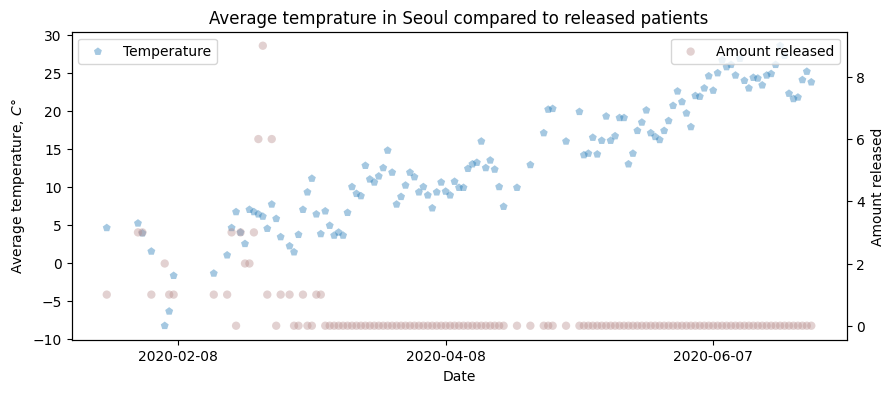

In [279]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax1 = scatter_graph_f(patient_weather_seoul, 'date', 'avg_temp', marker='p')
ax1.set(title='Average temprature in Seoul compared to released patients', ylabel='Average temperature, $C°$')
ax1.legend(['Temperature'])

ax2 = ax1.twinx()
ax2 = scatter_graph_f(patient_weather_seoul, 'date', 'released', color='#B88E8D', legend=True)
ax2.set(ylabel='Amount released')
ax2.legend(['Amount released']);

Here's an example of collected data. Patient dataset has a lot of missing datapoints for released dates, therefore we have a lot of 0 in released patients. Since it has a lot of missing data, let's try also using time_province dataset to check for corelations

In [280]:
# Inner join so take only values which are aviable on both dataset
time_province_weather = time_province.merge(
    weather, left_on=['date', 'province'], right_on=['date', 'province'], how='inner'
)

# Dropping unnecessary columns
time_province_weather.drop(columns=['code', 'min_temp', 'max_temp', 'time', 'deceased_percent'], inplace=True)

# Replacing accumulated values with just values
cum_columns = ['confirmed', 'released', 'deceased']
time_province_weather[cum_columns] -= time_province_weather.groupby('province')[cum_columns].shift(1).fillna(0)

time_province_weather.head()

,date,province,confirmed,released,deceased,avg_temp,precipitation,max_wind_speed,most_wind_direction,avg_relative_humidity
0,2020-01-20,Seoul,0.0,0.0,0.0,0.7,0.0,5.7,270,46.8
1,2020-01-20,Busan,0.0,0.0,0.0,5.1,0.0,6.1,270,45.6
2,2020-01-20,Daegu,0.0,0.0,0.0,4.6,0.0,6.4,290,44.1
3,2020-01-20,Incheon,1.0,0.0,0.0,1.2,0.0,8.6,320,56.0
4,2020-01-20,Gwangju,0.0,0.0,0.0,4.0,0.0,3.3,270,63.1


In [281]:
# Calculation of Spearman's correlation between numeric features:
correlation = time_province_weather.iloc[:, 2:].corr(method='spearman')

# Background style to visualize values:
cm = sns.color_palette('mako', as_cmap=True)

# Selecting only columns and rows in which I am interested:
correlation.iloc[3:, :3].style.background_gradient(cmap=cm, axis=None)

,confirmed,released,deceased
avg_temp,0.014522,0.162125,0.000114
precipitation,0.015181,-0.003987,-0.042202
max_wind_speed,0.065297,0.151455,0.087549
most_wind_direction,0.090966,0.066591,0.040050
avg_relative_humidity,-0.035547,-0.078312,-0.063888


For this dataset we can see weak correlation for released with average temperature and max wind speed, which is different from the previous dataset. Previous dataset had a lot of missing values for released. Here we can see that average temperature actually correlates with released patient amount. Also patients were released on more windy days. However, timeframe for collecting COVID data might be too short to have any concrete results.

In [282]:
mask = time_province_weather.province == 'Seoul'
time_province_weather_seoul = time_province_weather[mask]

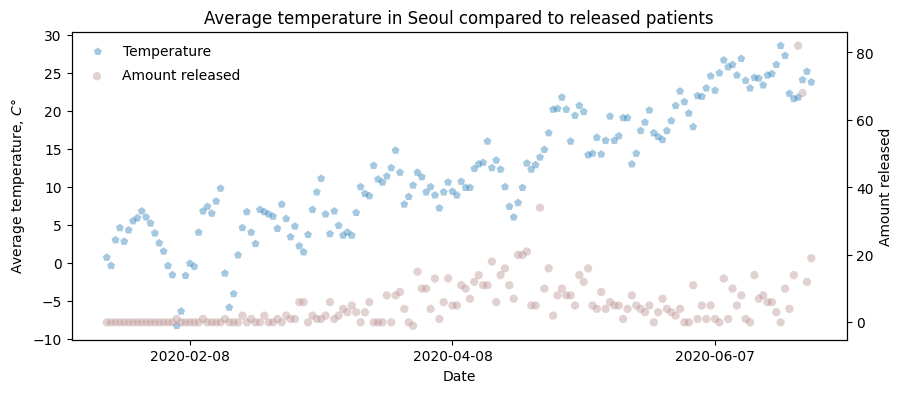

In [283]:
fig = plt.pyplot.figure(figsize=(10, 4))

ax1 = scatter_graph_f(time_province_weather_seoul, 'date', 'avg_temp', marker='p')
ax1.set(title='Average temperature in Seoul compared to released patients', ylabel='Average temperature, $C°$')
ax1.legend(['Temperature'], edgecolor='none')

ax2 = ax1.twinx()
ax2 = scatter_graph_f(time_province_weather_seoul, 'date', 'released', color='#B88E8D', legend=True)
ax2.set(ylabel='Amount released')
ax2.legend(['Amount released'], bbox_to_anchor=[0.234, 0.92], edgecolor='none');

We can see that in the beginning there were no released patients, and later on the amount increased. Since the timeframe starts in winter, and ends in summer, it looks like increase in temperature also increases amount of released patients.

# Summary

* Majority of COVID cases started as part of a group – places where people gather for events or other reasons. As such, we see churches, hospitals, clubs and gyms among places with highest case COVID case counts. There are a lot of outbreaks resulting from religious group activities. Case with highest infection count comes from Daegu province, Shincheonji Church.
* Although the virus spreads among all age groups, it spreads among elderly and sick easier, since hospitals and nursing homes appear often in infection causes. Places often visited by younger people, such as clubs or gyms, have much less cases.
* Although, majority of cases did come from group activities, there is still a considerable percent of them originating from individual to individual transfers, such as overseas travel, patient to patient contact and individual cases.
* Majority of COVID cases originated from city. Least amount of cases originated from country. Therefore, people density is likely to play a part in spread of COVID, most likely due to low density of people. 8.33% of cases originated from abroad.
* Confirmed count rises in waves. The second wave was smaller than the first one and maximums for waves are separated around by 3 months.
* There were more females than males in the dataset, but males had more contacts with others. Also, the virus was more deadly to males compared to females.
*  Most of people had to wait up to ten days to get confirmation that they got covid. Sometimes symptoms only appeared after confirmation of COVID.
*  Active policy amount negatively correlates with contacts and deceased patients, which indicates that policies did achieve what they were suposed to do – reduce contacts and deaths.
*  Amount of confirmed covid cases correlate strongly with nursing home count.
*  There is correlation between how many patients there are and population. Therefore, the more people are in the district, the more COVID patients as well. However, correlation between percent of confirmed infected population and population itself is low.
*  Coronavirus search looks like it is moved in time few days before the rise of amount confirmed.
*  Most confirmed COVID cases were in 20s age group. Highest mortality is in 80s age group. It had the highest amount of deceased and the highest pecent of deceased patients. No infected people aged up to 30 died during this period.
*  COVID does not seem to be related to weather much, however, timeframe for COVID data might be too short to have any concrete results.

## Suggestions for improvement

Deeper investigation of policies and Seoul data. Also investigation for outliers for symptom - confirmation days. Grouping patient data by two categories: for example age and gender. Draw some more interactive graphs for weather data, and other datasets where it is fitting. Create different versions for Git and presentation, since interactive graphs do not work there. Fix accumulated datasets so that following value would not be lower than previous one. Compare Korean data with other countries data. Also, obtain data for longer time period and do analysis on that. 